# Session 2: calibration, peak shape and background analysis of the Lynx spectra

This notebook analyses the four spectra measured in the basement laboratory between 12 and 26 October 2026 with a different HPGe detector and a Mirion (Canberra) Lynx digital MCA. They are a background run with an empty shield, the IAEA-385 reference sediment (labelled "calibration sample 2") and the two Norwegian lake-sediment samples. Session 1 used another detector on the third floor, read out by an ORTEC DSPEC-LF, and its analysis code lives in `code/hpge_analysis.py`. That code is not changed here. It is imported read-only so that we can test it on the new data.

The notebook answers four questions.

1. **Does the old code work on the new data, and if not, why not?** We run it step by step, see where and why it fails, explain each change we made in the new module `code/gamma_spec.py`, and measure how much each change moves the results.
2. **What are channels, bins and an energy calibration, and how do we calibrate?** The Lynx files contain no calibration at all, so the calibration is built from nothing, and every step is explained.
3. **How does the new setup differ from the old one?** We compare the two background spectra qualitatively and quantitatively (detector, electronics, third floor against basement) and then compare the samples with their own background.
4. **Do we agree with InterSpec?** We explain how InterSpec analyses a spectrum with the same care as our own method, run it on the same calibrated spectra and compare the numbers.

Every analysis step starts with a Markdown cell that says why the step is needed, what the physics or statistics behind it is, how the method works and what would go wrong without it. The code is meant to be reused for any similar experiment, so all choices that depend on this particular data set sit in the configuration cell of Section 1.

### Summary of results

| Question | Answer |
|---|---|
| Does the old code work on the Lynx data? | Not as it stands. It cannot read the files, and its rough calibration silently locks onto noise because the files carry no calibration (slope 1 keV per channel). The session-1 calibration puts K-40 at 1710 keV, because the new gain is 17 % lower. Once given a correct starting map, its peak fitting is sound (areas within 0.4 %, energies within 10 eV of the new code for strong peaks), but its straight-line calibration fails ($\chi^2 = 306$ for 8 degrees of freedom) because the Lynx energy scale is curved. |
| What changed in the new code? | A multi-format reader, a calibration that builds itself by pattern matching known lines, an exponentially modified Gaussian integrated exactly over each channel with one tail shared by all peaks, the mode as peak position, a polynomial calibration chosen by an F-test with a systematic floor for ADC non-linearity, free widths for broadened lines such as 511 keV, background subtraction, mass-free activity ratios via IAEA-385, and InterSpec-ready exports. Run on the session-1 spectrum it reproduces the old calibration to within 26 eV. |
| Calibration | Gain 0.1684 keV per channel (the bin width), range 0 to 2760 keV, FWHM 5 to 15 channels. A quadratic term is needed (F-test $p \le 10^{-3}$) and a 79 to 98 eV per-line systematic remains, the same zigzag in every spectrum, so it is the ADC's integral non-linearity. No gain drift above 0.06 keV in two weeks. |
| Peak shape | A small low-energy tail, $\beta = (0.40 \pm 0.06)\,\sigma$ with no step, preferred over a Gaussian by $\Delta D = 11$ (about 3.3 standard deviations). Ignoring it shifts positions by about one statistical error and areas by 0.2 %. |
| New setup against old | Better resolution (FWHM 0.92 against 1.30 keV at 122 keV, 1.77 against 2.00 keV at 1332 keV), lower threshold (1.6 against 10 keV), a curved energy scale, a sharp factor-4 continuum step at 36 keV and suppressed efficiency below about 60 keV. Its background is 20 to 60 times lower in environmental lines (much thicker shielding), but radon inside the shield and cosmic rays are only 2 to 17 times lower, so they now dominate. |
| Samples | Background subtraction removes 38 to 87 % of the radon-daughter and Tl-208 2614.5 keV rates. The sediments' Th-232/K-40 and Ra-226/K-40 ratios are consistent within their errors, while Norway 1 has 1.67 times more Cs-137 relative to K-40 (reported comparison: 4.2 standard deviations). Pb-210, Am-241 and Th-234 at 63 keV are not detected in any spectrum. |
| InterSpec | On the same calibrated spectra InterSpec finds the strong peaks within 7 to 14 eV of our energies, with areas 0.2 to 3 % higher and widths 1 to 3 % larger. It reads our `.Spe` calibration as a lower-edge polynomial, as its manual states, which settles the convention question left open in session 1. |

### How to read the evidence

Three questions must be kept separate: whether the energy calibration is reliable, whether a feature is a real photopeak, and whether that peak measures activity in the sediment. Passing one check does not establish the next. A calibrated peak can belong to the shield rather than the sample; a significant net peak can still give a biased activity if the sample and reference have different efficiencies.

Comparisons within this data set provide the strongest evidence. Explanations involving shielding, radon location, charge trapping or the 36 keV feature are physical interpretations, not direct measurements of detector construction. Reported significances are conditional on the fitted models and uncertainty treatment.

## 1. Setup

### Why a configuration cell
Everything that is specific to this data set (folders, file names, the role of each spectrum and the previous setup we compare with) is collected in one cell. To analyse another experiment, for example a new session or a different group's detector, one edits only this cell and runs the notebook from the top. The methods live in the module `gamma_spec.py`, which contains no file names, gains or detector properties.

### Which code is used
* `code/gamma_spec.py` is the new module (readers for several file formats, automatic calibration, the skewed peak model, Poisson fitting, calibration, resolution, inventory, background subtraction and exports). Its tests are in `code/test_gamma_spec.py`.
* `code/hpge_analysis.py` is the session-1 module, imported as `H` purely to test it on the new data. Nothing in it is modified.
* `data/reference/` holds the ENSDF gamma lines and other constants, shared by both.

In [1]:
import sys
import json
import importlib
import datetime as dt
from pathlib import Path
from zoneinfo import ZoneInfo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, optimize

# ---------------- configuration: the only cell to change when this notebook is reused
SESSION_TAG = "s2"                                               # prefix of every output file
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "data" / "raw").is_dir())   # repository root
SESSION_DIR = ROOT
DATA_DIR = ROOT / "data" / "raw"                          # raw files, never edited
SPECTRA = {                                                      # label: (file name, role)
    "background": ("backround_run_hpge_12_10.csv", "background"),
    "IAEA-385": ("thurs 15 oct - calibration sample 2 .csv", "reference"),
    "Norway 1": ("Norway1_22_10.csv", "sample"),
    "Norway 2": ("norway sample 2 - 22 oct 2026.csv", "sample"),
}
BACKGROUND = "background"
# Reference material in the same geometry as the samples: certificate values (Bq/kg, dry mass) and standard
# uncertainties (the certificate quotes k = 2 expanded uncertainties, halved here), IAEA-385 Rev.04 (2019).
REFERENCE_MATERIAL = dict(name="IAEA-385", reference_date=dt.date(2019, 1, 1),
                          measured_mid_date=dt.date(2026, 10, 17),     # middle of its run (timeline, Section 3)
                          K40=(611, 13.5), Cs137=(19.8, 0.3), Ra226=(22.8, 0.3), Th232=(33.8, 0.45),
                          Am241=(4.42, 0.115), Pb210=(28.5, 0.95))   # Pb-210 is an information value
LOCAL_TZ = ZoneInfo("Europe/London")
PREVIOUS = dict(label="session 1 background (third floor, DSPEC-LF)",
                spectrum=ROOT / "data" / "raw" / "BkgRun5_Long.Chn",
                calibration=ROOT / "results" / "session1" / "s1_energy_calibration.json")
OLD_MODULE_DIR = ROOT / "code"  # session-1 code, imported read-only

sys.path.insert(0, str(ROOT / "code"))
import gamma_spec as G
G = importlib.reload(G)                                          # picks up edits without a kernel restart
sys.path.append(str(OLD_MODULE_DIR))
sys.dont_write_bytecode = True                                  # write nothing into the old code folder
import hpge_analysis as H
sys.dont_write_bytecode = False

FIG, RES, ISP = ROOT / "figures" / "session2", ROOT / "results" / "session2", ROOT / "data" / "interspec" / "session2"
for folder in (FIG, RES, ISP):
    folder.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
pd.set_option("display.width", 220)


def save(fig, name):
    fig.savefig(FIG / f"{SESSION_TAG}_{name}.png", dpi=150, bbox_inches="tight")


def table(df, decimals=3):
    print(df.round(decimals).to_string(index=False))


print(f"new module : {Path(G.__file__).relative_to(ROOT)}")
print(f"old module : {Path(H.__file__).relative_to(ROOT)} (read-only)")
print(f"data       : {DATA_DIR.relative_to(ROOT)}")

new module : code/gamma_spec.py
old module : code/hpge_analysis.py (read-only)
data       : data/raw


## 2. What the detector sees, and how a spectrum is made

### What reaches the crystal
The germanium crystal sits in a vacuum cryostat cooled by liquid nitrogen, inside a lead shield. Photons reach it from five kinds of source, and every one of them leaves its mark on the spectra below.

* **The sample.** Natural K-40, the U-238 and Th-232 decay chains, and man-made Cs-137 and possibly Am-241 in the sediments.
* **The laboratory.** Concrete, bricks and soil contain the same primordial nuclides. Their photons must cross the lead, so only the most penetrating ones (above a few hundred keV) get through in useful numbers.
* **Radon.** Rn-222 gas from the ground and from building materials seeps into the air inside the shield, and its daughters Pb-214 and Bi-214 emit strong lines. Its concentration changes with ventilation and weather.
* **The detector itself.** Traces of radioactivity in the cryostat, holder and shield (for example Pb-210 in old lead).
* **Cosmic rays.** Muons and secondary neutrons pass through everything. Muons leave large energy deposits and a smooth continuum, create positrons whose annihilation gives a 511 keV line, and excite lead atoms (X-rays near 75 keV). Fast neutrons scatter inelastically on germanium and give characteristic broad features at 596 and 691 keV. How many of them arrive depends strongly on how much material is overhead, which is why the floor of the building matters (Section 12).

### How a photon becomes a count
1. **Interaction.** A gamma ray either passes straight through or interacts with the germanium by photoelectric absorption, Compton scattering or pair production. Which one happens depends on its energy (figure below, NIST XCOM data). Only events in which the whole photon energy stays in the crystal end up in the photopeak, which is the feature we measure.
2. **Ionisation.** The fast electron produced in the interaction slows down in a few millimetres and creates on average $N = E/\varepsilon$ electron–hole pairs, with $\varepsilon \approx 2.96$ eV in germanium at 77 K. A 1460.8 keV photon therefore creates about 490 000 pairs. The crystal is cooled because at room temperature thermal excitation across the 0.7 eV band gap would swamp this signal with leakage current.
3. **Charge collection.** A bias of a few kilovolts depletes the high-purity crystal, so the electrons and holes drift to opposite electrodes within a few hundred nanoseconds. Their motion induces a current on the electrodes (the Shockley–Ramo theorem), and the total induced charge equals $Ne$, proportional to the deposited energy. Carriers lost to traps on the way reduce the charge for a small fraction of events, which is what gives photopeaks their low-energy tail (Section 7).
4. **Preamplifier.** A charge-sensitive preamplifier integrates the current into a voltage step of height proportional to $Ne$, which then decays slowly (tens of microseconds) as the feedback capacitor discharges.
5. **Digital pulse processing (the Lynx).** The preamplifier output is digitised continuously. A trapezoidal filter (moving averages over a rise time, with a flat top) turns each step into a trapezoid whose flat-top height is proportional to the step height, while averaging away high-frequency noise. A pole-zero correction removes the preamplifier decay, a baseline restorer tracks the zero level, and pile-up rejection discards pulses that arrive too close together. The simulation below shows the idea with typical filter times. The actual Lynx settings were not written into the CSV files.
6. **Binning.** The flat-top height is converted to an integer between 0 and 16 383, the channel number, and the MCA adds one count to that channel. After days of counting, the 16 384 channel contents form the spectrum. A channel is therefore a narrow bin of pulse height, and an energy calibration is the map from pulse height to deposited energy (Section 4).
7. **Live time.** While the electronics process a pulse they cannot accept another one. The MCA counts the time during which it was able to accept pulses (the live time), so dividing counts by live time gives the true rate (Section 3).

### What the spectrum therefore contains
Each line of energy $E$ produces a photopeak at $E$, a Compton continuum up to the Compton edge $E_C = E\,\frac{2E/m_ec^2}{1+2E/m_ec^2}$ from photons that scatter once and escape, a backscatter peak near $E/(1+2E/m_ec^2)$ from photons that scattered in the shield before entering the crystal, and, above 1022 keV, single and double escape peaks at $E - 511$ and $E - 1022$ keV. The sum of the continua of all lines above a given energy forms the falling background on which every peak sits.

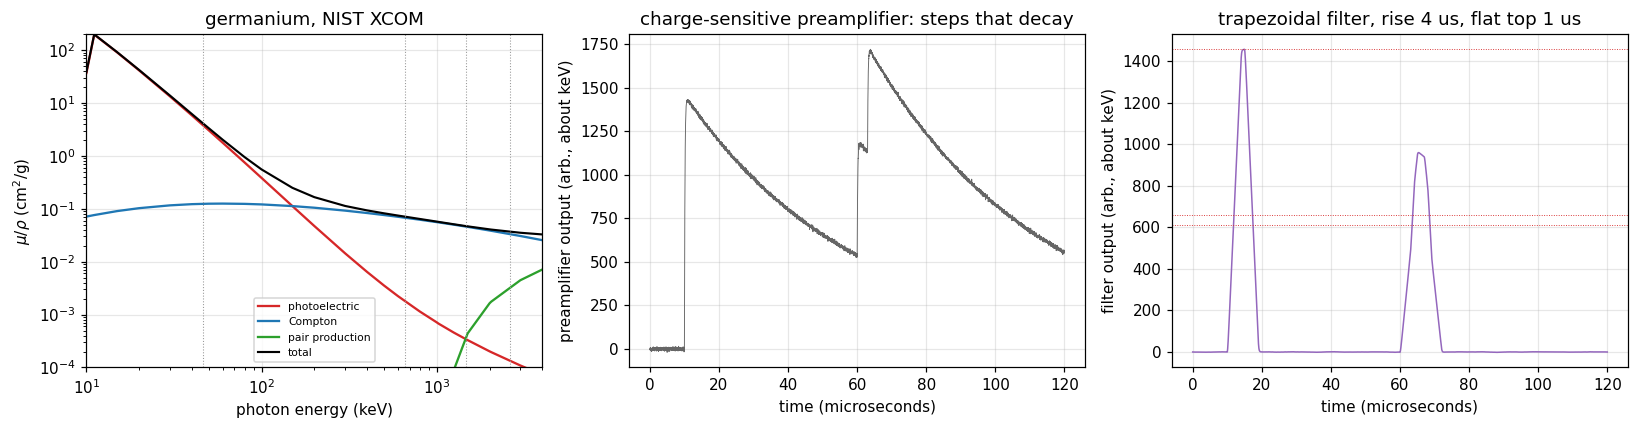

    46.5 keV: photoelectric  96.1 %, Compton   3.9 %, electron-hole pairs created     15723, sqrt(N) / N = 0.798 %
   661.7 keV: photoelectric   3.1 %, Compton  96.9 %, electron-hole pairs created    223533, sqrt(N) / N = 0.212 %
  1460.8 keV: photoelectric   0.7 %, Compton  98.3 %, electron-hole pairs created    493520, sqrt(N) / N = 0.142 %
  2614.5 keV: photoelectric   0.3 %, Compton  87.0 %, electron-hole pairs created    883281, sqrt(N) / N = 0.106 %


In [2]:
xcom = pd.read_csv(G.REFERENCE / "xcom_Z32.csv").drop_duplicates("E_MeV", keep="last")
E_x = xcom.E_MeV.values * 1000
fig, axes = plt.subplots(1, 3, figsize=(15, 4.0))
ax = axes[0]
ax.loglog(E_x, xcom.photo, color="tab:red", label="photoelectric")
ax.loglog(E_x, xcom.incoh, color="tab:blue", label="Compton")
pair = (xcom.pair_nuc + xcom.pair_el).values
ax.loglog(E_x[pair > 0], pair[pair > 0], color="tab:green", label="pair production")
ax.loglog(E_x, xcom.tot_with_coh, color="k", lw=1.4, label="total")
for E in (46.5, 661.7, 1460.8, 2614.5):
    ax.axvline(E, color="0.6", lw=0.7, ls=":")
ax.set(xlim=(10, 4000), ylim=(1e-4, 2e2), xlabel="photon energy (keV)", ylabel=r"$\mu/\rho$ (cm$^2$/g)",
       title="germanium, NIST XCOM")
ax.legend(fontsize=7)

# A simulated preamplifier signal and the trapezoidal filter that measures its height.
dt_us, tau_us, rise_us, flat_us = 0.02, 50.0, 4.0, 1.0       # typical values, the Lynx settings are not in the files
t_us = np.arange(0, 120, dt_us)
rng_pulse = np.random.default_rng(7)
arrivals = [(10.0, 1460.8), (60.0, 661.7), (63.0, 609.3)]      # (time, energy): the last two arrive close together
pre = np.zeros_like(t_us)
for t0, E in arrivals:
    on = t_us >= t0
    rise = 1 - np.exp(-(t_us[on] - t0) / 0.15)                 # ~0.3 microseconds of charge collection
    pre[on] += E * rise * np.exp(-(t_us[on] - t0) / tau_us)
pre += rng_pulse.normal(0, 6.0, pre.size)                      # electronic noise
decay = np.exp(-dt_us / tau_us)
step = np.cumsum(np.r_[pre[0], pre[1:] - decay * pre[:-1]])    # pole-zero correction: undo the decay
k, m = int(rise_us / dt_us), int(flat_us / dt_us)
c = np.r_[0.0, np.cumsum(step)]
ma = lambda d: (c[np.clip(np.arange(len(step)) - d + 1, 0, None)] - c[np.clip(np.arange(len(step)) - d - k + 1, 0, None)]) / k
trap = ma(0) - ma(k + m)
axes[1].plot(t_us, pre, color="0.4", lw=0.6)
axes[1].set(xlabel="time (microseconds)", ylabel="preamplifier output (arb., about keV)",
            title="charge-sensitive preamplifier: steps that decay")
axes[2].plot(t_us, trap, color="tab:purple", lw=1.0)
for t0, E in arrivals:
    axes[2].axhline(E, color="tab:red", lw=0.6, ls=":")
axes[2].set(xlabel="time (microseconds)", ylabel="filter output (arb., about keV)",
            title=f"trapezoidal filter, rise {rise_us:.0f} us, flat top {flat_us:.0f} us")
fig.tight_layout(); save(fig, "detector_signal"); plt.show()

for E in (46.539, 661.657, 1460.820, 2614.511):
    r = xcom.iloc[(xcom.E_MeV * 1000 - E).abs().argmin()]
    tot = r.photo + r.incoh + pair[(xcom.E_MeV * 1000 - E).abs().argmin()]
    print(f"{E:8.1f} keV: photoelectric {100 * r.photo / tot:5.1f} %, Compton {100 * r.incoh / tot:5.1f} %, "
          f"electron-hole pairs created {E / G.EPS_GE:9.0f}, sqrt(N) / N = {100 / np.sqrt(E / G.EPS_GE):.3f} %")

### What the figures show
At 46.5 keV (Pb-210) almost every interaction is photoelectric, so a photon that interacts is usually fully absorbed and the peak-to-continuum ratio is high. By 662 keV Compton scattering dominates, and at 1.46 and 2.61 MeV most interactions are Compton scatters, so a full-energy event usually needs several interactions inside the crystal. That is why the photopeak efficiency falls with energy and why each line carries a large continuum below it.

The pulse simulation shows the measuring principle. Each photon gives a step on the preamplifier output, and the trapezoid's flat top has a height proportional to the step, which is proportional to the number of electron–hole pairs and hence to the deposited energy. The two photons that arrive 3 microseconds apart produce overlapping trapezoids, so neither flat top gives the right height. Real electronics detect such pile-up and reject both pulses, and during that time the live-time clock is stopped. The statistical limit on the width is small (about 0.14 % at 1460.8 keV even before the Fano factor reduces it further), which is why germanium peaks are so narrow compared with scintillators.

## 3. The data files and their metadata

### Why
Every later number depends on three things in each file, namely the counts per channel, the live time (to turn counts into rates) and the start time (to correct for decay and to document the run). Before using them we check that they are consistent, because a wrong live time biases every rate and a wrong start time misdates every decay correction.

### What the Lynx CSV contains
Each file starts with five header lines (`Start Time`, `Energy calibration`, `Live Time (s)`, `Real Time (s)` and `Elapsed Computational`), then the word `Spectrum`, a column header and 16 384 rows of `Channel, Energy (keV), Counts`. Three details matter.

* **Channels are numbered from 1.** Our arrays start at 0, so file channel $n$ becomes array index $n - 1$. Mixing the two conventions would shift every energy by one channel (0.17 keV here).
* **The energy column is not an energy.** The header says `Offset: 0, Slope: 1, Quadratic: 0`, so the column simply repeats the channel number. The MCA was never calibrated, and the calibration has to be built from the spectrum itself (Sections 5 to 8).
* **`Elapsed Computational` is zero.** The Lynx can stop a run when a computed quantity (for example the counts in a region) reaches a preset. A zero means no such preset was used, so the runs were stopped by hand.

### Live time and dead time
While the electronics process one pulse they are blind to the next. For a non-paralysable system with dead time $\tau$ per event, $M$ recorded events in a real time $T$ leave the system live for $T - M\tau$, and photons keep arriving at the true rate $n$ during that time, so $M = n\,(T - M\tau)$ and
$$ m = \frac{M}{T} = \frac{n}{1 + n\tau} . $$
The MCA measures the live time $T_\text{live} = T - M\tau$ directly, so $n = M/T_\text{live}$ without needing to know $\tau$. This is why every rate below uses the live time. At our rates of about 2 counts per second the correction is tiny (0.02 %), but the rule matters for strong sources.

In [3]:
specs = {k: G.read_spectrum(DATA_DIR / f, label=k) for k, (f, role) in SPECTRA.items()}
roles = {k: role for k, (f, role) in SPECTRA.items()}
info = G.describe(specs.values())
table(info.drop(columns=["file", "format", "start", "end_from_real_time"]), 4)
print()
for k, s in specs.items():
    nz = np.flatnonzero(s.counts)
    print(f"{k:10s}: file channels {s.meta['first_channel_label']}..{s.meta['first_channel_label'] + s.n - 1} "
          f"(array index 0..{s.n - 1}), energy column = channel number: {s.meta['energy_column_is_channel_number']}, "
          f"stored calibration {s.stored_cal}")
    print(f"{'':10s}  first non-empty channel index {nz[0]}, last {nz[-1]}, empty channels {np.sum(s.counts == 0)}, "
          f"largest channel content {s.counts.max()} at index {s.counts.argmax()}")
    print(f"{'':10s}  dead time per recorded count {s.dead_fraction / (s.counts.sum() / s.real) * 1e6:.1f} microseconds, "
          f"header 'Elapsed Computational' = {s.meta['header'].get('Elapsed Computational')}")
    print(f"{'':10s}  sha256 {s.sha256}")

     label  channels  live_d  real_d  dead_pct  total_counts  rate_cps      stored_cal
background     16384  2.9363  2.9369    0.0194        545987    2.1521 (0.0, 1.0, 0.0)
  IAEA-385     16384  4.0483  4.0490    0.0196        811751    2.3208 (0.0, 1.0, 0.0)
  Norway 1     16384  2.7499  2.7504    0.0195        542322    2.2826 (0.0, 1.0, 0.0)
  Norway 2     16384  3.9740  3.9748    0.0195        785110    2.2866 (0.0, 1.0, 0.0)

background: file channels 1..16384 (array index 0..16383), energy column = channel number: True, stored calibration (0.0, 1.0, 0.0)
            first non-empty channel index 0, last 16383, empty channels 589, largest channel content 5441 at index 10
            dead time per recorded count 90.1 microseconds, header 'Elapsed Computational' = 0
            sha256 e2c0784a6e618b901b5e61f1cbee770efebd9c07d4bea27c8e1997a38e1e6ed4
IAEA-385  : file channels 1..16384 (array index 0..16383), energy column = channel number: True, stored calibration (0.0, 1.0, 0.0)
   

### The time interval of each run, checked against an independent clock
The start time in the header can be compared with a second, independent clock. When a browser downloads a file, macOS records the moment of the download (and the address it came from, here the data-acquisition web server on the laboratory network) in the file's metadata. A run cannot end after the moment its spectrum was downloaded, so for each file the header start plus the real time must come before the download time. The latest possible true start is the download time minus the real time.

In [4]:
rows = []
for k, s in specs.items():
    dl = G.download_time(s.path)
    start = s.start.astimezone(LOCAL_TZ)
    end = s.end.astimezone(LOCAL_TZ)
    rows.append(dict(spectrum=k, header_start=start.strftime("%a %d %b %H:%M:%S"),
                     header_start_plus_real=end.strftime("%a %d %b %H:%M"),
                     downloaded=dl.astimezone(LOCAL_TZ).strftime("%a %d %b %H:%M:%S") if dl else "unknown",
                     end_before_download=bool(dl and s.end <= dl),
                     latest_possible_start=(dl - dt.timedelta(seconds=s.real)).astimezone(LOCAL_TZ).strftime("%a %d %b %H:%M")
                     if dl else "", real_time_h=s.real / 3600))
timeline = pd.DataFrame(rows)
table(timeline, 2)
print()
for w in G.timeline_check(specs.values()):
    print("warning:", w)

  spectrum        header_start header_start_plus_real          downloaded  end_before_download latest_possible_start  real_time_h
background Mon 12 Oct 16:28:44       Thu 15 Oct 14:57 Thu 15 Oct 10:03:16                False      Mon 12 Oct 11:34        70.48
  IAEA-385 Mon 19 Oct 11:33:35       Fri 23 Oct 12:44 Mon 19 Oct 11:50:07                False      Thu 15 Oct 10:39        97.18
  Norway 1 Mon 19 Oct 11:33:35       Thu 22 Oct 05:34 Thu 22 Oct 09:40:58                 True      Mon 19 Oct 15:40        66.01
  Norway 2 Thu 22 Oct 09:41:14       Mon 26 Oct 08:04 Mon 26 Oct 13:39:38                 True      Thu 22 Oct 15:15        95.39



### What the timing shows
The live times (2.75 to 4.05 days) and dead-time fractions (0.019 to 0.020 %) are consistent with one another and with a count rate of about 2.2 per second, so the counts and times can be trusted. The start times cannot. Two of the four headers are impossible.

* **Background.** The header says the run started on Monday 12 October at 16:28. With 70.5 hours of real time it would then have ended on Thursday 15 October at 14:57, yet the file was downloaded at 10:03 that morning. The true start was therefore no later than 11:34 on Monday.
* **IAEA-385.** Its header gives exactly the same start, to the second, as Norway 1 (Monday 19 October 11:33:35), and the run would then have lasted until Friday 23 October, although the file was downloaded only 17 minutes after that "start". The run must have begun between the background download (Thursday 15 October 10:03) and 10:39, and by 10:23 if it was stopped just before Norway 1 began.
* **Norway 2** is consistent. It started 16 seconds after Norway 1 was downloaded, which also shows that the Lynx clock agreed with the computer clock to within seconds.
* **Norway 1** is consistent with its download, but its real time ends at about 05:34 on Thursday 22 October, four hours before the download, so the run stopped earlier than the file name suggests.

The most likely explanation is that the export writes the start time of whatever acquisition is current at the moment of export, rather than that of the stored spectrum, or that the start time is reset when a run is stopped and restarted while the live and real times keep accumulating. All four files came from the same web server on the laboratory network (the `where from` metadata), so this is a property of the export, not of one file. For this analysis the uncertainty costs almost nothing, because a few days change the Cs-137 decay correction by less than 0.03 %. It does matter for the lab book and for radon ingrowth in sealed pots, so the true times should be taken from the written record. The check itself is cheap and works for any downloaded file, and here it caught two wrong headers before they reached the report.

### Which time enters which calculation?

Use live time for count rates, real time for acquisition duration, and calendar time for decay or radon-ingrowth corrections. These are not interchangeable. A few days have little effect on Cs-137 decay, but can matter for a sealed pot approaching radon equilibrium. Plausible live times support their use; they do not independently calibrate the acquisition clock. The proposed export behaviour remains a hypothesis until checked against the instrument or lab record.

## 4. Channels, bins and what an energy calibration is

### A channel is a bin of pulse height
The MCA does not measure energy. It measures the height of each filtered pulse and sorts it into one of 16 384 equal intervals, the channels. Channel $i$ collects every pulse whose height falls between $i - \tfrac12$ and $i + \tfrac12$ on a continuous pulse-height scale $x$. The spectrum is therefore a histogram, and each count tells us only which bin the pulse fell into, not where inside it.

### The energy calibration is the map from pulse height to energy
Because the collected charge is proportional to the deposited energy and the electronics are designed to be linear, we expect
$$ E(x) = a_0 + a_1 x \quad(+\,a_2 x^2 \text{ if the electronics are slightly non-linear}), $$
where $a_1$ is the **gain** (keV per channel) and $a_0$ the **offset** (the energy of pulse height zero, which absorbs the ADC zero). One channel therefore spans an energy interval of width $a_1$, the **bin width**, from $E(i - \tfrac12)$ to $E(i + \tfrac12)$. Three conventions follow, and mixing them is a classic source of error.

* **Channel centre or lower edge.** Our fitted positions live on the continuous scale $x$, where channel $i$ is centred on $x = i$, so $E(i)$ is the centre of the bin. InterSpec (and the CALp and IAEA .Spe formats) use a polynomial for the **lower edge** of channel $i$, which equals $E(i - \tfrac12)$. Its coefficients are therefore $C_0 = a_0 - a_1/2 + a_2/4$, $C_1 = a_1 - a_2$ and $C_2 = a_2$. Getting this wrong shifts every energy by half a bin (0.084 keV here).
* **Counting from 0 or 1.** The Lynx file numbers channels from 1, our arrays from 0. Getting this wrong shifts every energy by a whole bin.
* **One calibration per setup.** The gain depends on the detector, the preamplifier, the MCA's coarse and fine gain and the number of channels. A calibration made with one setup means nothing for another (Section 5 shows how badly the session-1 calibration fits these files).

### How we calibrate
1. Find peaks in channel space, without any calibration (a matched filter, Section 6).
2. Recognise which peaks are which known lines by their pattern (the ratios of their positions, Section 6). This gives a rough map.
3. Fit every chosen line with a proper peak model, by Poisson maximum likelihood, to get its position with an uncertainty (Section 7).
4. Fit $E(x)$ to the (position, reference energy) pairs by weighted least squares, test whether a quadratic term is needed, and check the result with lines that were not used in the fit (Sections 8 and 10).

### How finely do 16 384 channels sample a peak?
A peak must be wider than a few bins for its position to be measured to a fraction of a bin. The FWHM here is about 1.0 keV at 240 keV and 2.5 keV at 2.6 MeV, which is 6 to 15 channels, so each peak is sampled by many bins. Even so, we integrate the peak shape over each bin instead of evaluating it at the bin centre, because the two differ by an amount that depends on the peak width in bins (table below). For a Gaussian of width $\sigma$ (in bins) the centre value underestimates the bin content at the top by a factor of about $1 - 1/(24\sigma^2)$ and overestimates it in the wings, so the fitted width and area would be slightly biased, more so for narrow peaks or coarse binning.

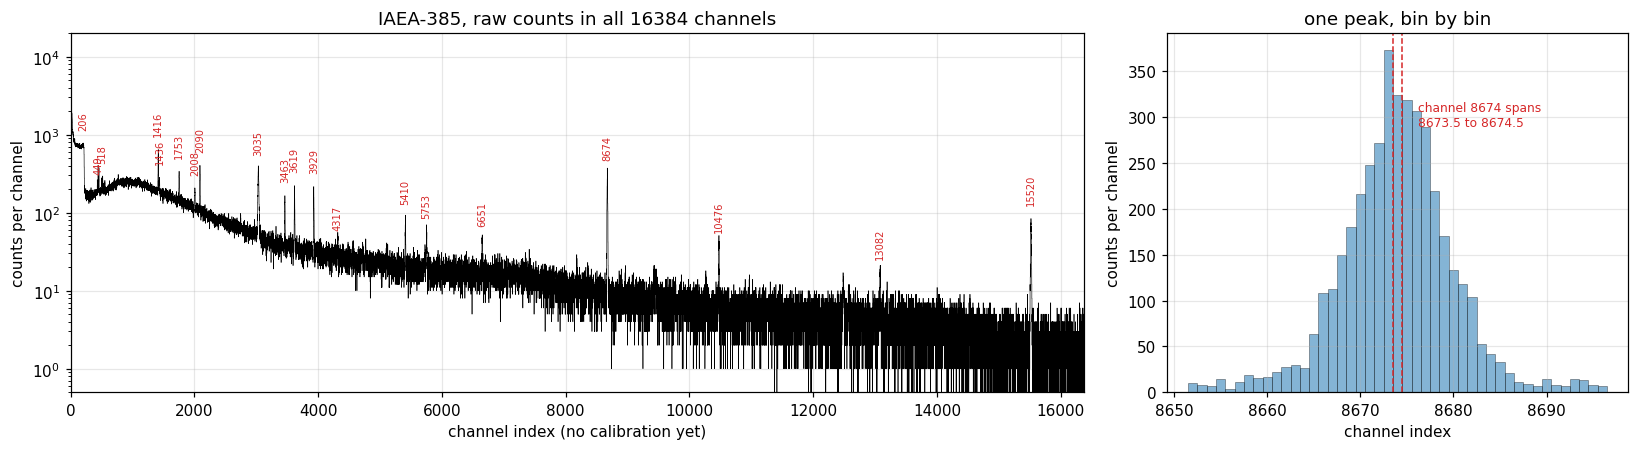

bin content of a unit-area Gaussian at its centre: exact integral against centre value x bin width
   sigma = 0.5 bins: top 0.85562, at 2 sigma 1.45677
   sigma = 1.0 bins: top 0.95985, at 2 sigma 1.12236
   sigma = 2.0 bins: top 0.98968, at 2 sigma 1.03109
   sigma = 4.0 bins: top 0.99740, at 2 sigma 1.00780
   sigma = 6.0 bins: top 0.99884, at 2 sigma 1.00347


In [5]:
s = specs["IAEA-385"]
found, S_ms, width_ms = G.multiscale_search(s.counts)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [2.2, 1]})
ax = axes[0]
ax.step(s.channels, np.maximum(s.counts, 0.5), where="mid", lw=0.4, color="k")
ax.set_yscale("log")
ax.set(xlim=(0, s.n), ylim=(0.5, 2e4), xlabel="channel index (no calibration yet)", ylabel="counts per channel",
       title=f"IAEA-385, raw counts in all {s.n} channels")
for i, S_i, w_i in found[:20]:
    ax.annotate(f"{i}", (i, s.counts[i]), xytext=(0, 10), textcoords="offset points", fontsize=6.5, ha="center",
                color="tab:red", rotation=90)
top = max((f for f in found if f[0] > 5000), key=lambda f: f[1])[0]  # the strongest peak in the upper part
ax = axes[1]
xs = np.arange(top - 22, top + 23)
ax.bar(xs, s.counts[xs], width=1.0, color="tab:blue", alpha=0.55, edgecolor="k", lw=0.4)
for e in (top - 0.5, top + 0.5):
    ax.axvline(e, color="tab:red", lw=1.0, ls="--")
ax.annotate(f"channel {top} spans\n{top - 0.5} to {top + 0.5}", (top + 0.5, s.counts[top]), xytext=(10, -20),
            textcoords="offset points", fontsize=8, color="tab:red")
ax.set(xlabel="channel index", ylabel="counts per channel", title="one peak, bin by bin")
fig.tight_layout(); save(fig, "channels_and_bins"); plt.show()

print("bin content of a unit-area Gaussian at its centre: exact integral against centre value x bin width")
for sig in (0.5, 1.0, 2.0, 4.0, 6.0):
    exact = G.peak_in_bins(0.0, 0.0, sig)
    centre = G.gauss_pdf(0.0, 0.0, sig)
    wing = G.peak_in_bins(2 * sig, 0.0, sig) / G.gauss_pdf(2 * sig, 0.0, sig)
    print(f"   sigma = {sig:3.1f} bins: top {exact / centre:.5f}, at 2 sigma {wing:.5f}")

### What this shows
Without a calibration the spectrum is just counts against channel index, yet it already shows clear peaks on a falling continuum, and the zoom shows that one peak spans about 25 channels, each a separate bin with its own Poisson count. The table confirms that at our widths (about 2 to 6 bins for $\sigma$) the difference between the bin integral and the centre value is below 1 % at the top and changes sign in the wings, which is small but systematic. The bin integral costs nothing, so we always use it.

## 5. Does the session-1 code work on the new data?

### Why test the old code first
The session-1 module was tested on an ORTEC spectrum from a different detector. Running it unchanged on the Lynx data shows which assumptions were hidden in it, and tells us exactly what had to change. We go through its pipeline in the order the session-1 notebook used it.

1. **Reading.** `H.read_chn` reads ORTEC binary files only.
2. **Rough calibration.** `H.bootstrap_map` takes the calibration stored in the file, uses it to predict where K-40 (1460.8 keV) and Tl-208 (2614.5 keV) should be, takes the highest channel within ±30 channels of each prediction and draws a line through the two.
3. **Reusing a calibration.** The session-1 README suggests `H.load_calibration` to apply an earlier calibration to a later spectrum.
4. **Fitting.** `H.fit_roi` fits a symmetric Gaussian plus a step on a straight line by Poisson likelihood, and `H.calibrate` fits the line.

In [6]:
s = specs["IAEA-385"]
print("1. reading")
try:
    H.read_chn(s.path)
except Exception as err:
    print(f"   H.read_chn on the Lynx CSV fails: {type(err).__name__}: {str(err).replace(str(ROOT) + '/', '')}")

print("\n2. rough calibration from the stored calibration (offset 0, slope 1)")
old_spec = H.Spectrum(counts=s.counts, live=s.live, real=s.real, start=s.start, stored_cal=s.stored_cal,
                      path=s.path, sha256=s.sha256)
g0_bad, g1_bad, cK_bad, cT_bad = H.bootstrap_map(old_spec)
print(f"   K-40 searched near channel {(1460.820 - s.stored_cal[0]) / s.stored_cal[1]:.0f}, picked channel {cK_bad} "
      f"({s.counts[cK_bad]} counts)")
print(f"   Tl-208 searched near channel {(2614.511 - s.stored_cal[0]) / s.stored_cal[1]:.0f}, picked channel {cT_bad} "
      f"({s.counts[cT_bad]} counts)")
print(f"   resulting map: E = {g0_bad:.1f} + {g1_bad:.4f} * channel  (it just reproduces 'one channel = one keV')")

print("\n3. applying the session-1 calibration to the new channels")
cal_s1_json = H.load_calibration(PREVIOUS["calibration"])
g0_auto, g1_auto, auto_tab_iaea, _ = G.auto_calibrate(s.counts)       # the correct identification, from Section 6
check = auto_tab_iaea[["nuclide", "E_ref", "channel"]].copy()
check["E_with_session1_cal"] = cal_s1_json.energy(check.channel)
check["error_keV"] = check.E_with_session1_cal - check.E_ref
table(check, 2)
print(f"   session-1 gain {cal_s1_json.a[1]:.6f} keV/channel against {g1_auto:.6f} here: ratio {cal_s1_json.a[1] / g1_auto:.4f}")

1. reading
   H.read_chn on the Lynx CSV fails: ValueError: data/raw/thurs 15 oct - calibration sample 2 .csv is not an ORTEC integer .Chn file

2. rough calibration from the stored calibration (offset 0, slope 1)
   K-40 searched near channel 1461, picked channel 1436 (284 counts)
   Tl-208 searched near channel 2615, picked channel 2607 (89 counts)
   resulting map: E = 46.0 + 0.9852 * channel  (it just reproduces 'one channel = one keV')

3. applying the session-1 calibration to the new channels
nuclide   E_ref  channel  E_with_session1_cal  error_keV
 Pb-212  238.63  1416.37               279.46      40.83
 Pb-214  295.22  1752.75               345.76      50.54
 Ac-228  338.32  2008.57               396.18      57.86
 Pb-214  351.93  2089.91               412.22      60.28
 Tl-208  583.19  3462.74               682.81      99.62
 Bi-214  609.32  3618.63               713.53     104.21
 Ac-228  911.20  5410.65              1066.75     155.54
 Ac-228  968.97  5753.02              11

### Why steps 1 to 3 fail
* **Reading** fails for the plain reason that the file is text, not ORTEC binary.
* **The rough calibration fails silently**, which is more dangerous. With a stored slope of 1 keV per channel, the code looks for K-40 near channel 1461 and Tl-208 near channel 2615 and simply takes the largest count in each window. Both windows contain only continuum, so the two "peaks" are noise and the fitted line is again about one keV per channel. Nothing crashes, but every later step would fit the wrong places. The hidden assumption was that the stored calibration is already roughly right, which was true for the ORTEC file (3 keV off at 2.6 MeV) and is completely false here.
* **The session-1 calibration does not transfer.** The new detector and MCA have a gain about 17 % lower, so the old calibration puts K-40 near 1710 keV. A calibration belongs to one detector, one amplifier setting and one channel count.

### What happens if we give the old fitter the right starting point
The fitting and calibration functions themselves are general. If we supply the correct rough map from Section 6, the old pipeline runs. The cell below does exactly what the session-1 notebook did (the same ten lines, a Gaussian plus a free step, ±7 starting widths) so that we can later compare its calibration with the new one on the same data.

In [7]:
OLD_LINES = [("Pb-212", 238.632, 0.002), ("Pb-214", 295.224, 0.002), ("Pb-214", 351.932, 0.021),
             ("Tl-208", 583.187, 0.002), ("Bi-214", 609.321, 0.007), ("Ac-228", 911.204, 0.004),
             ("Bi-214", 1120.294, 0.006), ("K-40", 1460.820, 0.005), ("Bi-214", 1764.491, 0.014),
             ("Tl-208", 2614.511, 0.010)]
to_ch = lambda E: (E - g0_auto) / g1_auto
sigma_start_old = lambda E: (1.0 + 0.0006 * E) / H.FWHM_PER_SIGMA / g1_auto
rows = []
for name, E, sE in OLD_LINES:
    c = H.highest_channel(s.counts, to_ch(E), 8)
    centres = [c, to_ch(241.995)] if abs(E - 238.632) < 0.01 else [c]
    fit = H.fit_roi(s.counts, centres, sigma_start_old(E), half=7.0, step=None)
    p = H.peak(fit)
    rows.append(dict(nuclide=name, E_ref=E, sE_ref=sE, mu=p["mu"], smu=p["smu"], sigma_ch=p["sigma"], area=p["A"],
                     sarea=p["sA"], step=fit["theta"][3], dev=fit["dev"], ndf=fit["ndf"], p_value=fit["pval"]))
old_lines = pd.DataFrame(rows)
cal_old_code = H.calibrate(old_lines.mu, old_lines.smu, old_lines.E_ref, old_lines.sE_ref)
table(old_lines, 3)
print(f"\nold pipeline, IAEA-385: E = {cal_old_code.a[0]:.4f} + {cal_old_code.a[1]:.8f} x, "
      f"chi2/ndf = {cal_old_code.chi2:.1f}/{cal_old_code.ndf}, scale factor {cal_old_code.scale:.2f}")
R_STEP_OLD = float(old_lines.loc[old_lines.nuclide.isin(["K-40", "Tl-208"]) & (old_lines.E_ref > 1000), "step"].mean())
print(f"step ratio from K-40 and Tl-208 2614.5 (as the session-1 notebook did): {R_STEP_OLD:.4f}")

nuclide    E_ref  sE_ref        mu   smu  sigma_ch     area  sarea   step    dev  ndf  p_value
 Pb-212  238.632   0.002  1416.384 0.090     2.637 3135.824 88.007 -0.053 90.721   56    0.002
 Pb-214  295.224   0.002  1752.818 0.178     2.524 1242.496 64.905  0.015 31.603   37    0.720
 Pb-214  351.932   0.021  2090.096 0.117     2.784 2193.520 68.745 -0.006 43.157   39    0.298
 Tl-208  583.187   0.002  3463.022 0.211     3.104  851.770 43.044  0.064 44.592   43    0.405
 Bi-214  609.321   0.007  3618.401 0.159     3.458 1509.341 51.550  0.031 46.588   45    0.407
 Ac-228  911.204   0.004  5410.489 0.287     3.834  658.395 36.275  0.025 40.799   51    0.846
 Bi-214 1120.294   0.006  6650.541 0.487     3.913  329.513 30.530 -0.163 61.015   55    0.269
   K-40 1460.820   0.005  8674.051 0.098     4.706 3732.536 64.879  0.019 85.303   63    0.032
 Bi-214 1764.491   0.014 10476.470 0.373     5.042  487.796 27.517  0.059 72.457   69    0.365
 Tl-208 2614.511   0.010 15519.582 0.241     6.380

### Old pipeline with a correct start
Given the right starting map, the old pipeline runs without complaint and its individual fits look reasonable (p-values from 0.03 to 0.85, apart from 0.002 at 238.6 keV, where the Pb-214 neighbour shares the window). The calibration it produces, however, has $\chi^2 = 306$ for 8 degrees of freedom, which the old code hides behind a scale factor of 6.2. Section 8 shows that the cause is not the peak model but a real curvature and small wiggles in the energy scale of the new electronics, which a straight line cannot follow. The old code fits a straight line unless told otherwise, and that is the second assumption it carried over from session 1, where it happened to be true. The step ratio it measures here (0.012) is half the session-1 value, a first hint that the new detector has less low-side structure.

## 6. A first calibration with no prior knowledge: pattern matching

### Why
Without a stored calibration we must recognise known lines in a spectrum whose energy scale we do not know. Doing it by eye works once, but it is slow and it is not reproducible. The new code does it automatically, which makes the whole analysis work for any detector, gain or channel count.

### The idea
The mentor's remark in session 1 gives the key. If two peaks are known to be lines of energies $E_a$ and $E_b$, their separation in channels $\Delta c$ fixes the gain, $a_1 = (E_b - E_a)/\Delta c$, and then the offset. We do not know which peaks are which, so we try every possibility and let the spectrum decide.

1. **Find peaks without a calibration.** A matched filter (the negative second derivative of a Gaussian, with zero sum so that a flat or straight continuum gives no response) is convolved with the counts. Its output divided by its own Poisson standard deviation is a significance $S$, which is close to a standard normal variable where there is no peak. Since the peak width is unknown, the filter is run for widths from 1.5 to 12 channels and each channel keeps the largest $S$. Local maxima above $S = 5$ are peak candidates.
2. **Locate each candidate** to a fraction of a channel by the first moment of its counts above a straight floor.
3. **Vote.** For every pair of the 30 strongest candidates and every pair of reference lines (13 strong, isolated natural lines from ENSDF, the same set used for the final calibration), compute the gain and offset they imply. Reject physically absurd ones (a gain outside 0.01 to 5 keV per channel or an offset beyond ±30 keV). For each surviving hypothesis, predict where all the other reference lines should be and count how many land within 3 channels (or 0.8 keV) of a candidate. The right hypothesis explains many lines at once, a wrong one only the two it was built from.
4. **Refine.** Fit a straight line to all matched pairs and repeat the matching three times.

### Why it is robust
Peaks are sparse. With 30 candidates spread over 16 384 channels, a reference line lands within ±3 channels of some candidate by accident with probability about $30 \times 7/16\,384 \approx 1.3\,\%$. A wrong hypothesis therefore explains, on average, far less than one extra line, while the correct one explains ten or more. The method needs no starting values and does not care which lines happen to be strongest.

### What would happen without it
We would have to identify peaks by eye in every new spectrum, or trust a stored calibration that may not exist (as here) or may be wrong (as in session 1). Either way the analysis would stop being automatic, and a misidentified anchor would silently corrupt everything that follows.

background: 13 candidates used,  7 of 13 reference lines matched, rough map E = -0.139 + 0.168467 x, rms residual 0.198 keV
IAEA-385  : 28 candidates used, 13 of 13 reference lines matched, rough map E = -0.160 + 0.168456 x, rms residual 0.171 keV
Norway 1  : 24 candidates used, 12 of 13 reference lines matched, rough map E = -0.166 + 0.168460 x, rms residual 0.184 keV
Norway 2  : 27 candidates used, 13 of 13 reference lines matched, rough map E = -0.090 + 0.168462 x, rms residual 0.135 keV

mentor's two-line estimate from IAEA-385 alone: gain = (2614.511 - 1460.820) / (15519.51 - 8673.94) = 0.168531 keV per channel
nuclide    E_ref   channel      S  E_rough  residual_keV
 Pb-212  238.632  1416.372 38.348  238.436        -0.196
 Pb-214  295.224  1752.747 21.501  295.101        -0.123
 Ac-228  338.320  2008.566 12.946  338.195        -0.125
 Pb-214  351.932  2089.908 34.923  351.897        -0.035
 Tl-208  583.187  3462.743 21.999  583.159        -0.028
 Bi-214  609.321  3618.627 31.827 

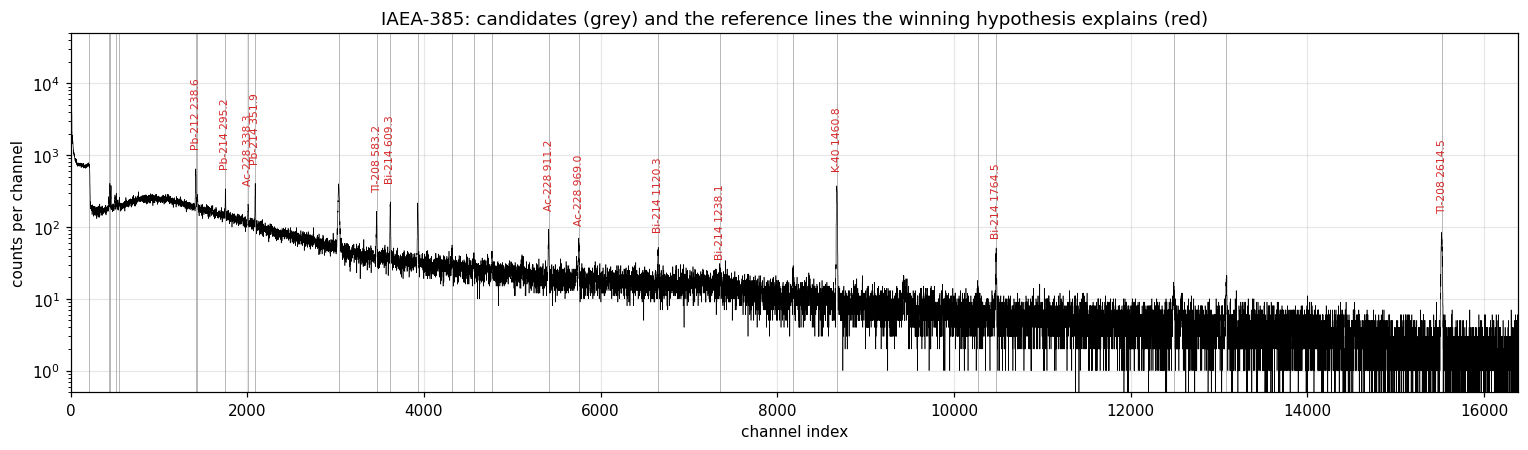

In [8]:
auto, rough = {}, {}
for k, s in specs.items():
    g0, g1, tab, found_k = G.auto_calibrate(s.counts)
    auto[k] = dict(g0=g0, g1=g1, table=tab, found=found_k)
    rough[k] = G.linear_calibration(g0, g1)
    print(f"{k:10s}: {len(found_k):2d} candidates used, {len(tab):2d} of {len(G.NATURAL_LINES)} reference lines matched, "
          f"rough map E = {g0:+.3f} + {g1:.6f} x, rms residual {np.std(tab.E_rough - tab.E_ref):.3f} keV")
k1 = auto["IAEA-385"]["table"]
ck, ct = k1.set_index("E_ref").channel[1460.820], k1.set_index("E_ref").channel[2614.511]
print(f"\nmentor's two-line estimate from IAEA-385 alone: gain = (2614.511 - 1460.820) / ({ct:.2f} - {ck:.2f}) "
      f"= {(2614.511 - 1460.820) / (ct - ck):.6f} keV per channel")
table(auto["IAEA-385"]["table"].assign(residual_keV=lambda d: d.E_rough - d.E_ref), 3)

s = specs["IAEA-385"]
fig, ax = plt.subplots(figsize=(14, 4.2))
ax.step(s.channels, np.maximum(s.counts, 0.5), where="mid", lw=0.4, color="k")
ax.set_yscale("log")
for i, S_i, w_i in auto["IAEA-385"]["found"]:
    ax.axvline(i, color="0.7", lw=0.6, zorder=0)
for r in auto["IAEA-385"]["table"].itertuples():
    ax.annotate(f"{r.nuclide} {r.E_ref:.1f}", (r.channel, s.counts[int(round(r.channel))]), xytext=(0, 14),
                textcoords="offset points", rotation=90, fontsize=7, color="tab:red", ha="center")
ax.set(xlim=(0, s.n), ylim=(0.5, 5e4), xlabel="channel index", ylabel="counts per channel",
       title="IAEA-385: candidates (grey) and the reference lines the winning hypothesis explains (red)")
fig.tight_layout(); save(fig, "auto_calibration"); plt.show()

### Result
The pattern matching finds the same gain, 0.16846 to 0.16847 keV per channel, in all four spectra. It explains 12 or 13 of the 13 reference lines in the three sample spectra and 7 in the weak background, with no wrong identification. The rough maps are already good to about 0.2 keV rms, which is far inside the 3-channel matching tolerance and more than enough to place every fitting window correctly. The two-line estimate from K-40 and Tl-208 alone gives 0.168531 keV per channel, 0.05 % higher. That shows both the power and the limit of the two-line method, since any error in two positions, or any curvature of the scale, goes straight into the gain. Using all the lines averages this down, and Section 8 then measures the curvature properly.

## 7. The shape of a photopeak, and how we treat its skew

### Why the shape matters
Three numbers come from every peak, its position (for the calibration and identification), its width (for the resolution) and its area (for rates and activities). All three depend on the model fitted to it. If the model is symmetric but the peak is not, the fit puts the centre too high or too low, and the counts in the asymmetric part are partly given to the continuum, which biases the area. The session-1 K-40 study (`session1_K40_peak_fit.ipynb`, Sections 3b and 18) found exactly this for the old detector and settled on a skewed model. Here we carry that treatment over, explain it fully, and test whether this detector needs it.

### Where a skew comes from
1. **The Gaussian core.** The number of electron–hole pairs fluctuates with variance $F N$ ($F \approx 0.1$ is the Fano factor), and electronic noise adds in quadrature, so the pulse heights of full-energy events are Gaussian.
2. **Incomplete charge collection.** Impurities and lattice defects trap some carriers on their way to the electrodes. Trapping can only remove charge, never add it, so a fraction of events are shifted to lower pulse height. This produces a **low-energy tail** and changes the shape of the peak itself.
3. **A step.** Photons that Compton scatter through a small angle before entering the crystal arrive with slightly less energy, so the continuum just below each peak is raised by an amount proportional to the peak area. Smeared by the resolution this gives a step, $h\,\tfrac12\operatorname{erfc}[(x-\mu)/\sqrt2\sigma]$.

### The exponentially modified Gaussian (EMG), from first principles
Let the pulse height with perfect collection be Gaussian with centre $\mu$ and width $\sigma$, and let the charge lost to trapping, $t \ge 0$, be exponentially distributed with mean $\beta$. The observed height $x = x_0 - t$ then has the convolution
$$ g(x) = \int_0^\infty \frac{1}{\beta}e^{-t/\beta}\,\frac{1}{\sqrt{2\pi}\,\sigma}\exp\!\left[-\frac{(x+t-\mu)^2}{2\sigma^2}\right]dt
= \frac{1}{2\beta}\exp\!\left(\frac{x-\mu}{\beta}+\frac{\sigma^2}{2\beta^2}\right)\operatorname{erfc}\!\left(\frac{x-\mu}{\sqrt2\,\sigma}+\frac{\sigma}{\sqrt2\,\beta}\right) , $$
obtained by completing the square in $t$. Because $x$ is a sum of two independent parts, its moments follow at once. The mean is $\mu - \beta$, the variance $\sigma^2 + \beta^2$ and the skewness $\gamma_1 = -2\beta^3/(\sigma^2+\beta^2)^{3/2}$, negative as a low-energy tail must be. As $\beta \to 0$ the EMG becomes the Gaussian. The exponential and erfc can overflow separately, so the code writes their product with $\operatorname{erfcx}(z) = e^{z^2}\operatorname{erfc}(z)$, which is the same number in a numerically safe form.

### Integrating it exactly over a channel (new in this module)
Differentiating $g$ under the integral and integrating by parts gives $\beta\,g'(x) = g(x) - \phi(x)$, where $\phi$ is the Gaussian density. Hence $\frac{d}{dx}\left[\Phi\!\left(\tfrac{x-\mu}{\sigma}\right) + \beta\,g(x)\right] = \phi + g - \phi = g$, so the cumulative distribution is
$$ F(x) = \Phi\!\left(\frac{x-\mu}{\sigma}\right) + \beta\,g(x) , $$
and the expected counts in channel $i$ are exactly $A\,[F(i+\tfrac12) - F(i-\tfrac12)]$. The session-1 notebook approximated this integral with Simpson's rule. The closed form is exact and just as fast.

### Which number is "the position" of a skewed peak?
For a Gaussian the mean, median and mode coincide. For the EMG there are three natural candidates, the Gaussian centre $\mu$ (which lies above the visible top), the mean $\mu - \beta$ (pulled down by the tail) and the mode, the most probable pulse height. From $\beta g' = g - \phi$ the slope vanishes where $g = \phi$, which happens once, below $\mu$, so the mode is found by a one-dimensional root search. We use the mode for every peak because it is what the eye calls the top, it is closest to what a Gaussian fit to a nearly symmetric peak finds, and it depends least on how the tail is modelled. What matters most is that **every calibration line uses the same definition** (Section 8 measures what mixing them would do).

### How we fit
The model of the expected counts in channel $i$ is a straight continuum plus $A$ times the bin integral of the peak (plus an optional step). We minimise the Poisson deviance
$$ D = 2\sum_i\left[f_i - n_i + n_i\ln\frac{n_i}{f_i}\right] , $$
which is $-2\ln$ of the likelihood ratio against a perfect model. Least-squares $\chi^2$ with $\sigma_i^2 = n_i$ (Neyman) or $\sigma_i^2 = f_i$ (Pearson) would bias areas by about one count per channel at low counts (session-1 notebook, Section 4). For a correct model $D$ follows a $\chi^2$ distribution with (channels minus free parameters) degrees of freedom, which gives a goodness-of-fit p-value. The parameter covariance is the inverse of the expected Fisher information $J^{\mathsf T}WJ$ with $W = \operatorname{diag}(1/f_i)$, and the uncertainty of the mode follows by first-order propagation through $(\mu, \sigma, \beta)$.

### First, a model-free look
Before fitting we test the K-40 peak for asymmetry using only the raw counts. The session-1 study did this in two ways, a mirror test (net counts at equal distances below and above the highest channel) and the skewness. The mirror test needs to know where the top is, and with only a few hundred counts per channel at the top the highest channel is set by Poisson fluctuations as much as by the peak shape. The skewness uses every count in the window and needs only a rough centre, so it is the more robust test at these statistics. We take as floor a straight line through the outermost 10 channels on each side of an 81-channel window, centre the window on the first moment of the net counts, and compute the third standardised moment
$$ \gamma_1 = \frac{m_3}{m_2^{3/2}} , \qquad m_k = \frac{\sum_i w_i (x_i - \bar x)^k}{\sum_i w_i} , $$
with weights $w_i$ equal to the net counts within ±15 channels. It is zero for any symmetric peak and negative for a low-energy tail. Its error comes from 1000 Poisson resamplings of the counts (a parametric bootstrap). We do this in all three sample spectra and compare the result with what an EMG of each tail length would give in the same window.

In [9]:
rng_skew = np.random.default_rng(1)
shape_spectra = [k for k, r in roles.items() if r != "background"]   # spectra with strong lines, one detector


def net_window(y_all, centre, ext=40, n_side=10):
    # raw counts within +-ext channels and a straight floor through the outermost n_side channels on each side
    x = np.arange(centre - ext, centre + ext + 1, dtype=float)
    y = y_all[centre - ext:centre + ext + 1].astype(float)
    xl, xr = x[:n_side].mean(), x[-n_side:].mean()
    bl, br = y[:n_side].mean(), y[-n_side:].mean()
    return x, y, bl + (br - bl) * (x - xl) / (xr - xl)


def skewness(x, net, centre, half=15):
    # third standardised moment of the net counts within +-half channels of the centre
    keep = np.abs(x - centre) <= half
    w, xs = net[keep], x[keep]
    m = np.sum(w * xs) / w.sum()
    return (np.sum(w * (xs - m)**3) / w.sum()) / (np.sum(w * (xs - m)**2) / w.sum())**1.5


rows = []
for k in shape_spectra:
    s = specs[k]
    c0 = int(round(rough[k].channel(1460.820)))
    x, y, floor = net_window(s.counts, c0)
    near = np.abs(x - c0) <= 20
    centre = int(round(np.sum(x[near] * (y - floor)[near]) / np.sum((y - floor)[near])))  # first moment, no fit
    x, y, floor = net_window(s.counts, centre)
    g_obs = skewness(x, y - floor, centre)
    boot = []
    for _ in range(1000):
        yb = rng_skew.poisson(y).astype(float)
        xl, xr = x[:10].mean(), x[-10:].mean()
        fb = yb[:10].mean() + (yb[-10:].mean() - yb[:10].mean()) * (x - xl) / (xr - xl)
        boot.append(skewness(x, yb - fb, centre))
    top = int(np.argmax(y))
    rows.append(dict(spectrum=k, highest_channel=int(x[top]), counts_at_top=int(y[top]),
                     neighbours=f"{int(y[top - 1])}, {int(y[top + 1])}", first_moment=centre,
                     skewness=g_obs, s_skewness=float(np.std(boot))))
skew = pd.DataFrame(rows)
table(skew, 3)
w = 1 / skew.s_skewness**2
g_mean, g_err = float(np.sum(w * skew.skewness) / w.sum()), float(1 / np.sqrt(w.sum()))
print(f"weighted mean skewness of K-40 in the three sample spectra: {g_mean:.3f} +- {g_err:.3f} "
      f"({abs(g_mean) / g_err:.1f} standard deviations from zero)")

# What a symmetric peak and an EMG with a tail of beta = tau * sigma predict for the same window
fk = G.fit_roi(specs["IAEA-385"].counts, [rough["IAEA-385"].channel(1460.820)], 1.85 / G.FWHM_PER_SIGMA / g1_auto,
               shape="gauss", step=0.0)
sig_k = float(fk["theta"][3])                                     # width of K-40 in channels, from a quick Gaussian fit
tt = np.linspace(-60, 60, 24001)
for tau_test in (0.0, 0.2, 0.4, 0.6):
    pdf = G.emg_pdf(tt, 0.0, sig_k, max(tau_test * sig_k, 1e-9))
    m = np.sum(tt * pdf) / pdf.sum()
    keep = np.abs(tt - m) <= 15
    mm = np.sum(tt[keep] * pdf[keep]) / pdf[keep].sum()
    g = (np.sum(pdf[keep] * (tt[keep] - mm)**3) / pdf[keep].sum()) / (np.sum(pdf[keep] * (tt[keep] - mm)**2) / pdf[keep].sum())**1.5
    full = -2 * tau_test**3 / (1 + tau_test**2)**1.5
    print(f"   EMG with beta = {tau_test:.1f} sigma: skewness {full:+.3f} for the whole peak, {g:+.3f} within +-15 channels")

spectrum  highest_channel  counts_at_top neighbours  first_moment  skewness  s_skewness
IAEA-385             8673            373   272, 324          8674    -0.142       0.056
Norway 1             8675            120    101, 96          8674    -0.140       0.096
Norway 2             8675            183   173, 171          8674    -0.048       0.092
weighted mean skewness of K-40 in the three sample spectra: -0.121 +- 0.043 (2.8 standard deviations from zero)
   EMG with beta = 0.0 sigma: skewness -0.000 for the whole peak, +0.000 within +-15 channels
   EMG with beta = 0.2 sigma: skewness -0.015 for the whole peak, -0.010 within +-15 channels
   EMG with beta = 0.4 sigma: skewness -0.102 for the whole peak, -0.056 within +-15 channels
   EMG with beta = 0.6 sigma: skewness -0.272 for the whole peak, -0.116 within +-15 channels


All three spectra give a negative skewness, and their weighted mean is $-0.121 \pm 0.043$, 2.8 standard deviations from zero. An EMG predicts $-0.056$ in the same window for $\beta = 0.4\,\sigma$ and $-0.116$ for $\beta = 0.6\,\sigma$, so the model-free measurement points to a low-energy tail of that size, without any fit. It also shows why the mirror test is not used here. The highest channel of IAEA-385 holds 373 counts while its neighbours hold 272 and 324, an upward fluctuation of about 2.5 standard deviations, so the top of the raw histogram is set by noise rather than by the shape, and a comparison anchored on it would mainly measure that noise.

### Model comparison line by line
Next we fit each calibration line in IAEA-385 with four models on exactly the same channels, a Gaussian, a Gaussian with a free step, an EMG with a free tail, and an EMG with tail and step. The models are nested, so the drop in deviance $\Delta D$ from adding one parameter follows a $\chi^2_1$ distribution if the parameter is not needed (Wilks' theorem, conservative for the EMG because $\beta = 0$ sits at the edge of its range). We also list the Akaike criterion $\text{AIC} = D + 2k$, which penalises each of the $k$ parameters.

In [10]:
s = specs["IAEA-385"]
rows = []
for name, E, sE in G.NATURAL_LINES:
    x_e = float(rough["IAEA-385"].channel(E))
    s0 = (0.8 + 0.0005 * E) / G.FWHM_PER_SIGMA / g1_auto
    centres = [x_e] + [float(rough["IAEA-385"].channel(e)) for e in G.NEIGHBOURS.get(E, [])]
    fits = {lab: G.fit_roi(s.counts, centres, s0, **kw) for lab, kw in [
        ("G", dict(shape="gauss", step=0.0)), ("G+step", dict(shape="gauss", step="free")),
        ("EMG", dict(shape="emg", step=0.0)), ("EMG+step", dict(shape="emg", step="free"))]}
    pE = G.peak(fits["EMG"])
    rows.append(dict(line=f"{name} {E:.1f}", area=pE["A"], D_G=fits["G"]["dev"],
                     dD_step=fits["G"]["dev"] - fits["G+step"]["dev"], dD_tail=fits["G"]["dev"] - fits["EMG"]["dev"],
                     dD_both=fits["G"]["dev"] - fits["EMG+step"]["dev"], ndf_G=fits["G"]["ndf"],
                     beta_over_sigma=pE["beta"] / pE["sigma"], s_ratio=pE["sbeta"] / pE["sigma"],
                     best_AIC=min(fits, key=lambda m: fits[m]["aic"])))
per_line = pd.DataFrame(rows)
table(per_line, 2)
print(f"\nsum over {len(per_line)} lines: tail lowers D by {per_line.dD_tail.sum():.1f} for {len(per_line)} extra "
      f"parameters (p = {stats.chi2.sf(per_line.dD_tail.sum(), len(per_line)):.3f}), "
      f"step lowers D by {per_line.dD_step.sum():.1f} (p = {stats.chi2.sf(per_line.dD_step.sum(), len(per_line)):.3f})")

         line    area   D_G  dD_step  dD_tail  dD_both  ndf_G  beta_over_sigma  s_ratio best_AIC
 Pb-212 238.6 3165.88 84.85    10.20     3.50    20.86     47             0.62     0.17 EMG+step
 Pb-214 295.2 1250.71 62.29     0.18     0.26     0.32     58             0.46     0.40        G
 Ac-228 338.3  775.52 21.07     4.90     4.99     5.25     31             1.92     0.68      EMG
 Pb-214 351.9 2186.89 29.22     0.22     0.00     0.28     32             0.08     3.72        G
 Tl-208 583.2  873.23 39.87     1.97     1.41     1.97     36             0.72     0.27        G
 Bi-214 609.3 1484.49 31.86     0.24    -0.00     0.24     36             0.02    93.90        G
 Ac-228 911.2  675.86 34.45     1.34     2.58     2.71     42             0.95     0.28      EMG
 Ac-228 969.0  460.39 55.82     0.21    -0.00     0.35     65             0.01   247.42        G
Bi-214 1120.3  340.79 52.28     0.40     0.25     1.34     45             0.61     0.55        G
Bi-214 1238.1  109.76 55.40   

Line by line the evidence is weak. The tail lowers the deviance clearly only for K-40 ($\Delta D = 6.7$) and marginally for Pb-212 at 238.6 keV and Ac-228 at 338.3 keV. Summed over all 13 lines it gains 20.0 for 13 extra parameters ($p = 0.10$), which on its own is not significant. A step gains about the same (29.8, $p = 0.005$), mostly from the same two strong lines, because with a few thousand counts per peak a tail and a step both just put extra counts on the low side and the data cannot tell them apart. The fitted ratios $\beta/\sigma$ scatter from 0 to 1.9 with errors to match. This is what a real but small effect spread over many weak peaks looks like, and it is why we next fit one common shape to all of them.

### One shape for all peaks: a joint profile likelihood
A tail that is real but small is hard to see in one peak of a few thousand counts, while the same tail in many peaks adds up. Physically the trapping tail should scale with the peak width, so we describe it by one shared ratio $\tau = \beta/\sigma$ (and the step by one shared ratio $r$, the step height as a fraction of the peak height) for every line in every sample spectrum, which all come from the same detector. For each $(\tau, r)$ on a grid we fit all 13 lines in the three sample spectra, with each line's area, position, width and continuum free, and add up the deviances. The minimum of the total gives the best common shape, and $\Delta D = 1$ around it gives the uncertainty, since $D_\text{total}$ is $-2\ln L$ up to a constant. The empty-shield background is left out because its lines are too weak to help.

grid minimum at tau = 0.4, step ratio r = 0.0
Gaussian with no step is worse by Delta D = 11.2; best Gaussian with a step (r = 0.01) is worse by 9.1


parabola through the fine scan: tau = 0.398 +- 0.063 (Delta D = 1), step ratio fixed at 0.0


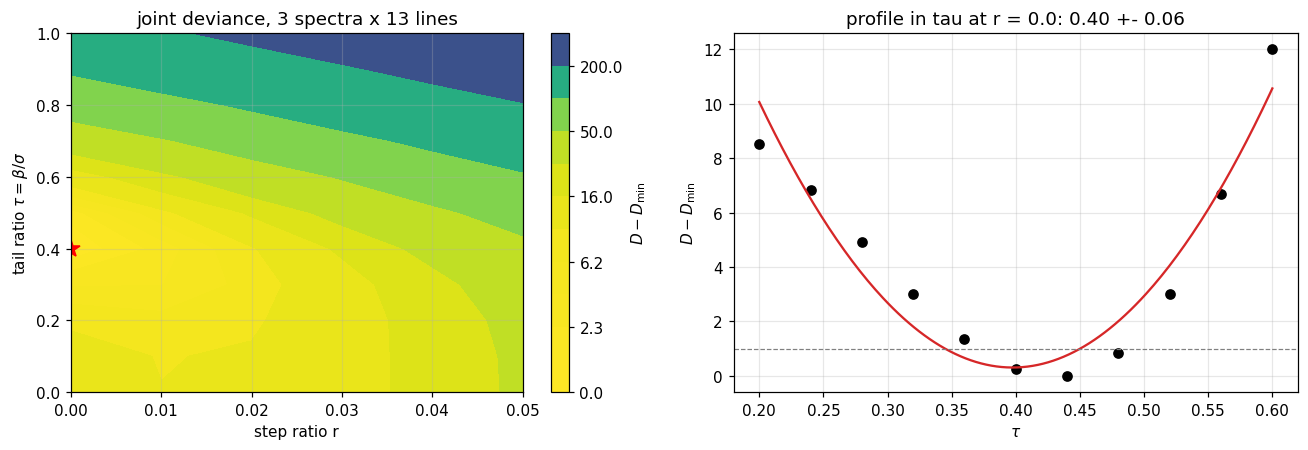

In [11]:
shape_spectra = [k for k, r in roles.items() if r != "background"]
TAUS = np.round(np.arange(0.0, 1.01, 0.1), 2)
STEPS = np.round(np.arange(0.0, 0.051, 0.01), 3)
D_grid = np.zeros((len(TAUS), len(STEPS)))
for a, tau in enumerate(TAUS):
    for b, r in enumerate(STEPS):
        D_grid[a, b] = sum(G.fit_lines(specs[k], rough[k], tail_ratio=tau, step=r)[0].dev.sum() for k in shape_spectra)
ia, ib = np.unravel_index(D_grid.argmin(), D_grid.shape)
print(f"grid minimum at tau = {TAUS[ia]}, step ratio r = {STEPS[ib]}")
print(f"Gaussian with no step is worse by Delta D = {D_grid[0, 0] - D_grid.min():.1f}; "
      f"best Gaussian with a step (r = {STEPS[D_grid[0].argmin()]}) is worse by {D_grid[0].min() - D_grid.min():.1f}")

fine = np.round(np.arange(max(TAUS[ia] - 0.2, 0.0), TAUS[ia] + 0.201, 0.04), 3)
D_fine = np.array([sum(G.fit_lines(specs[k], rough[k], tail_ratio=t, step=float(STEPS[ib]))[0].dev.sum()
                       for k in shape_spectra) for t in fine])
c2, c1, c0 = np.polyfit(fine, D_fine, 2)
TAU = float(-c1 / (2 * c2))
TAU_ERR = float(1 / np.sqrt(c2))
STEP = float(STEPS[ib])
print(f"parabola through the fine scan: tau = {TAU:.3f} +- {TAU_ERR:.3f} (Delta D = 1), step ratio fixed at {STEP}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
cs = axes[0].contourf(STEPS, TAUS, D_grid - D_grid.min(), levels=[0, 1, 2.3, 4, 6.2, 9, 16, 25, 50, 100, 200, 400],
                      cmap="viridis_r")
axes[0].plot(STEP, TAU, "r*", ms=12)
fig.colorbar(cs, ax=axes[0], label=r"$D - D_\min$")
axes[0].set(xlabel="step ratio r", ylabel=r"tail ratio $\tau = \beta/\sigma$", title="joint deviance, 3 spectra x 13 lines")
axes[1].plot(fine, D_fine - D_fine.min(), "o", color="k")
tt = np.linspace(fine[0], fine[-1], 200)
axes[1].plot(tt, np.polyval([c2, c1, c0], tt) - D_fine.min(), color="tab:red")
axes[1].axhline(1, color="0.5", ls="--", lw=0.8)
axes[1].set(xlabel=r"$\tau$", ylabel=r"$D - D_\min$", title=f"profile in tau at r = {STEP}: {TAU:.2f} +- {TAU_ERR:.2f}")
fig.tight_layout(); save(fig, "tail_profile"); plt.show()

The joint fit settles the question. The best common shape has a tail of $\tau = \beta/\sigma = 0.40 \pm 0.06$ and no step ($r = 0$). A pure Gaussian is worse by $\Delta D = 11.2$ for one parameter, about 3.3 standard deviations, and the best Gaussian with a step is still worse by 9.1, so the shared tail describes the low-side counts better than a step does. The session-1 detector, analysed the same way in Section 12, gives $\tau = 0.45 \pm 0.03$, close to the 0.49 found from its K-40 peak alone, so both detectors tail in a similar way. The tail is small (from Section 9, $\beta$ is 0.14 keV at 60 keV and 0.39 keV at 2.6 MeV), but it is real, and from here on every peak is fitted with this shape.

### What the common-tail fit establishes

Pooling lines increases sensitivity because every line constrains the same shape parameter while retaining its own amplitude, position and continuum. This reduces the unstable trade-off between a weak line's tail and its background. It assumes that one dimensionless tail ratio describes all selected energies and runs. Coherent residuals on one side of several peaks would challenge that assumption.

The likelihood difference supports the EMG among the tested models; it does not uniquely identify a microscopic charge-loss mechanism. Zero tail lies on a parameter boundary, so conversion of deviance differences into Gaussian significance is approximate. A dedicated null simulation would calibrate that model-selection significance. Fixing the fitted tail in subsequent fits also makes their errors conditional on that value rather than propagating its full uncertainty.

### What happens if we ignore the tail? A test with simulated peaks
On real data we never know the true answer, so we test both models on simulated spectra whose truth we choose. We take the fitted K-40 peak of IAEA-385 (EMG with the common $\tau$) as the truth, draw 400 Poisson spectra from it, and fit each one twice, once with a Gaussian plus free step (the old model) and once with the EMG with $\tau$ fixed. For each fit we record the error in position (against the true mode) and in area, divided by the quoted uncertainty (the pull). An unbiased method with honest errors gives pulls with mean 0 and standard deviation 1.

truth: area 3744, sigma 4.415, beta 1.755 channels, mode - mu = -1.570


          model quantity  mean_error  error_of_mean  mean_pull  sd_pull
Gaussian + step      pos      -0.091          0.005     -0.919    0.978
Gaussian + step        A      -8.191          3.270     -0.134    1.007
EMG (tau fixed)      pos       0.004          0.004      0.047    1.004
EMG (tau fixed)        A       0.570          3.261      0.001    1.001
relative area bias of the Gaussian model: -0.22 % (+- 0.09 %)


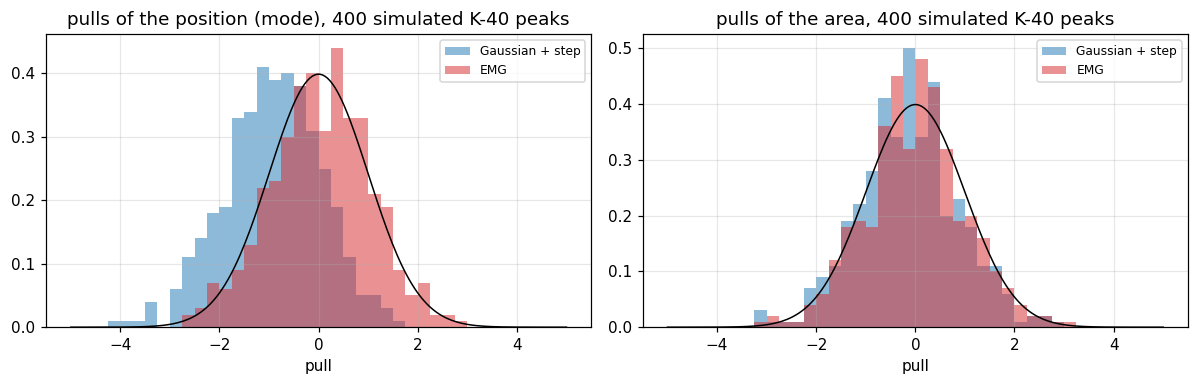

In [12]:
s = specs["IAEA-385"]
xk = float(rough["IAEA-385"].channel(1460.820))
s0 = 1.85 / G.FWHM_PER_SIGMA / g1_auto
truth_fit = G.fit_roi(s.counts, [xk], s0, shape="emg", tail_ratio=TAU, step=0.0)
th = truth_fit["theta"].copy()
lo = int(truth_fit["x"][0])
n_ch = len(truth_fit["x"])
theta_true = th.copy()
theta_true[7] = th[7] - lo                                      # positions relative to the simulated window
theta_true[[0, 1, 2]] = [th[0] + th[1] * (lo + (n_ch - 1) / 2 - truth_fit["x0"]), th[1], 0.0]
A_true, mu_true, sig_true, beta_true = theta_true[6], theta_true[7], theta_true[3], theta_true[4]
mode_true = G.emg_mode(mu_true, sig_true, beta_true)
print(f"truth: area {A_true:.0f}, sigma {sig_true:.3f}, beta {beta_true:.3f} channels, mode - mu = {mode_true - mu_true:.3f}")
rng_toy = np.random.default_rng(20261027)
rows = []
for _ in range(400):
    y = G.simulate_roi(theta_true, n_ch, 1, rng_toy)
    start = [mode_true + rng_toy.uniform(-1, 1)]
    sg = sig_true * rng_toy.uniform(0.9, 1.1)
    fg = G.fit_roi(y, start, sg, shape="gauss", step="free", lo=0, hi=n_ch - 1)
    fe = G.fit_roi(y, start, sg, shape="emg", tail_ratio=TAU, step=0.0, lo=0, hi=n_ch - 1)
    pg, pe = G.peak(fg), G.peak(fe)
    rows.append(dict(pos_G=pg["position"] - mode_true, spos_G=pg["sposition"], A_G=pg["A"] - A_true, sA_G=pg["sA"],
                     pos_E=pe["position"] - mode_true, spos_E=pe["sposition"], A_E=pe["A"] - A_true, sA_E=pe["sA"]))
toys = pd.DataFrame(rows)
summ = []
for lab in ("G", "E"):
    for q in ("pos", "A"):
        pull = toys[f"{q}_{lab}"] / toys[f"s{q}_{lab}"]
        summ.append(dict(model="Gaussian + step" if lab == "G" else "EMG (tau fixed)", quantity=q,
                         mean_error=toys[f"{q}_{lab}"].mean(), error_of_mean=toys[f"{q}_{lab}"].std() / np.sqrt(len(toys)),
                         mean_pull=pull.mean(), sd_pull=pull.std(ddof=1)))
toy_summary = pd.DataFrame(summ)
table(toy_summary, 3)
print(f"relative area bias of the Gaussian model: {100 * toys.A_G.mean() / A_true:+.2f} % "
      f"(+- {100 * toys.A_G.std() / np.sqrt(len(toys)) / A_true:.2f} %)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
grid = np.linspace(-5, 5, 200)
for ax, q, lab in zip(axes, ("pos", "A"), ("position (mode)", "area")):
    for m, col in (("G", "tab:blue"), ("E", "tab:red")):
        ax.hist(toys[f"{q}_{m}"] / toys[f"s{q}_{m}"], bins=np.linspace(-5, 5, 41), density=True, alpha=0.5, color=col,
                label="Gaussian + step" if m == "G" else "EMG")
    ax.plot(grid, stats.norm.pdf(grid), color="k", lw=1)
    ax.set(xlabel="pull", title=f"pulls of the {lab}, 400 simulated K-40 peaks")
    ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "toy_pulls"); plt.show()

The simulation shows what ignoring the tail would cost. The Gaussian plus step places the K-40 peak $0.091 \pm 0.005$ channels (15 eV) below the true mode, about one statistical standard deviation of the position (mean pull $-0.92$), so a calibration built that way would carry a bias as large as its own statistical errors. Its area is biased by only $-0.22 \pm 0.09\,\%$, because the free step absorbs most of the tail counts. The EMG fit is unbiased in both (mean pulls 0.05 and 0.00) and its pull widths are 1.00, so its quoted uncertainties are honest. For this detector the tail therefore matters mainly for positions, at the level of their statistical errors, and very little for areas. A detector with a longer tail, or peaks with many more counts, would make the bias larger in units of the error, which is why the method is kept general.

### Scope of the simulation

A pull is $(\widehat q-q_\mathrm{true})/\widehat\sigma_q$. Its mean tests bias; its width tests whether the quoted error matches repeated-experiment scatter. A width above one indicates underestimated errors, while a width below one indicates conservative errors or dependence between the estimate and its uncertainty.

These toys test an isolated K-40-like peak generated from the adopted EMG. They do not validate that model against all detector responses or test unresolved multiplets, changing radon, reference geometry or calibration extrapolation. Their conclusion is conditional: with the simulated shape, continuum and statistics, the EMG recovers the input position and area with the observed pull behaviour.

## 8. The energy calibration of each spectrum

### Method
For each spectrum separately we fit all 13 reference lines with the common shape (EMG with the shared $\tau$, no step), with each line's area, position, width and continuum free, at the place where the rough map of Section 6 puts it. Known neighbours inside a window are fitted together with it (Pb-214 242.0 keV next to Pb-212 238.6 keV, Pb-212 300.1 keV next to Pb-214 295.2 keV and Ac-228 964.8 keV next to 969.0 keV). A line is used only if it is clearly significant (area at least 5 standard deviations), was found within 3 widths of where it was expected, has an acceptable fit ($p > 10^{-4}$) and does not have its width stuck at a bound.

The calibration is then a weighted least-squares fit of $E(x)$ to the (mode, ENSDF energy) pairs. Each point has an error in energy (the ENSDF uncertainty, 2 to 21 eV) and an error in position. The position error is converted to energy with the local gain, $s^2 = s_E^2 + (a_1 s_x)^2$, and the fit is iterated (the "effective variance" method).

### When the points scatter more than their errors allow
If $\chi^2/\nu$ is well above 1, either the model or the errors are incomplete. Session 1 multiplied the coefficient covariance by $\chi^2/\nu$ (the PDG scale factor). Here we instead add a per-line systematic $s_\text{sys}$ in quadrature, $s^2 = s_E^2 + (a_1 s_x)^2 + s_\text{sys}^2$, and choose it so that $\chi^2/\nu = 1$. The two are similar for the coefficients, but the systematic has a physical meaning (how far any single line can sit from the smooth curve) and it must also be added to the uncertainty of every energy measured later, which a scale factor would forget. A spectrum whose own lines are too weak to measure the curvature borrows it from the reference spectrum taken with the same electronics, because an ADC non-linearity belongs to the hardware, and fits only its offset and gain.

### Linear or quadratic?
A quadratic term $a_2 x^2$ always lowers $\chi^2$ a little. The F-test asks whether it lowers it by more than chance, with $F = (\chi^2_1 - \chi^2_2)/(\chi^2_2/\nu_2)$ following an $F(1, \nu_2)$ distribution if the true relation is linear. We adopt the quadratic only if $p_F < 0.01$, because an unnecessary term inflates the uncertainty of extrapolations (for example to 46.5 keV, far below the lowest calibration line).

### Why calibrate every spectrum separately
The gain of an HPGe system drifts slightly with temperature and electronics, and the spectra were taken over two weeks. Calibrating each one separately protects every spectrum against drift, and comparing the calibrations measures the drift (below).

In [13]:
lines, line_fits, cals, cals_lin, cals_quad, cal_tests = {}, {}, {}, {}, {}, []
for k, s in specs.items():
    t, f = G.fit_lines(s, rough[k], tail_ratio=TAU, step=STEP)
    t["used"] = G.select_lines(t)
    u = t[t.used]
    lin = G.fit_calibration(u.position, u.sposition, u.E_ref, u.sE_ref, degree=1, scale_by_chi2=False)
    quad = G.fit_calibration(u.position, u.sposition, u.E_ref, u.sE_ref, degree=2, scale_by_chi2=False)
    F, pF = G.f_test(lin, quad)
    degree = 2 if pF < 0.01 else 1
    cal = G.fit_calibration(u.position, u.sposition, u.E_ref, u.sE_ref, degree=degree, sys_keV="auto")
    t["E_fit"] = cal.energy(t.position)
    t["resid_keV"] = t.E_fit - t.E_ref
    t["resid_lin_keV"] = lin.energy(t.position) - t.E_ref
    t["sE_stat"] = lin.gain(t.position) * t.sposition
    lines[k], line_fits[k], cals[k], cals_lin[k], cals_quad[k] = t, f, cal, lin, quad
    cal_tests.append(dict(spectrum=k, lines_used=int(t.used.sum()), a0=lin.a[0], a1=lin.a[1],
                          chi2_lin=lin.chi2, ndf_lin=lin.ndf, chi2_quad=quad.chi2, ndf_quad=quad.ndf, a2=quad.a[2],
                          s_a2=np.sqrt(quad.C[2, 2]), F=F, p_F=pF, adopted="quadratic" if degree == 2 else "linear",
                          sys_keV=cal.sys))
cal_summary = pd.DataFrame(cal_tests)

# A spectrum whose lines are too weak to show the curvature (F-test p > 0.01) borrows it from the
# reference spectrum, because the non-linearity belongs to the ADC, which is the same in every run.
REFERENCE_SPECTRUM = next(k for k, r in roles.items() if r == "reference")
for k in specs:
    row = cal_summary.spectrum == k
    if k != REFERENCE_SPECTRUM and cal_summary.loc[row, "adopted"].iloc[0] == "linear" and cals[REFERENCE_SPECTRUM].degree > 1:
        t = lines[k]
        u = t[t.used]
        cals[k] = G.fit_calibration_borrowed_shape(u.position, u.sposition, u.E_ref, u.sE_ref, cals[REFERENCE_SPECTRUM])
        t["E_fit"] = cals[k].energy(t.position)
        t["resid_keV"] = t.E_fit - t.E_ref
        cal_summary.loc[row, "adopted"] = f"curvature from {REFERENCE_SPECTRUM}"
        cal_summary.loc[row, "sys_keV"] = cals[k].sys
with pd.option_context("display.float_format", "{:.6g}".format):
    print(cal_summary.to_string(index=False))
for k, cal in cals.items():
    poly = " + ".join(f"({c:.6g} +- {np.sqrt(cal.C[j, j]):.2g}) x^{j}" for j, c in enumerate(cal.a))
    print(f"{k:10s} adopted: E = {poly}, per-line systematic {1000 * cal.sys:.0f} eV")
print()
table(lines["IAEA-385"][["nuclide", "E_ref", "position", "sposition", "sigma_ch", "area", "signif", "pval", "used",
                         "resid_lin_keV", "resid_keV", "sE_stat"]], 4)

  spectrum  lines_used         a0       a1  chi2_lin  ndf_lin  chi2_quad  ndf_quad          a2        s_a2       F         p_F                 adopted   sys_keV
background           7  -0.257632 0.168475   59.7279        5     24.235         4 6.82427e-09 1.14537e-09 5.85812    0.072735 curvature from IAEA-385  0.174311
  IAEA-385          12 -0.0553013 0.168435   363.386       10    50.3732         9  8.0864e-09 4.57251e-10 55.9248 3.77792e-05               quadratic 0.0790393
  Norway 1          11  -0.123284 0.168451   147.416        9    36.8516         8  6.9967e-09 6.65536e-10 24.0021  0.00119499               quadratic 0.0981072
  Norway 2          12 -0.0937189 0.168446   208.263       10     36.888         9 7.12458e-09 5.44361e-10 41.8124 0.000115921               quadratic 0.0789188
background adopted: E = (0.0943576 +- 0.13) x^0 + (0.168366 +- 1.5e-05) x^1 + (6.19769e-09 +- 0) x^2, per-line systematic 174 eV
IAEA-385   adopted: E = (0.0911669 +- 0.068) x^0 + (0.16836 +- 2.3

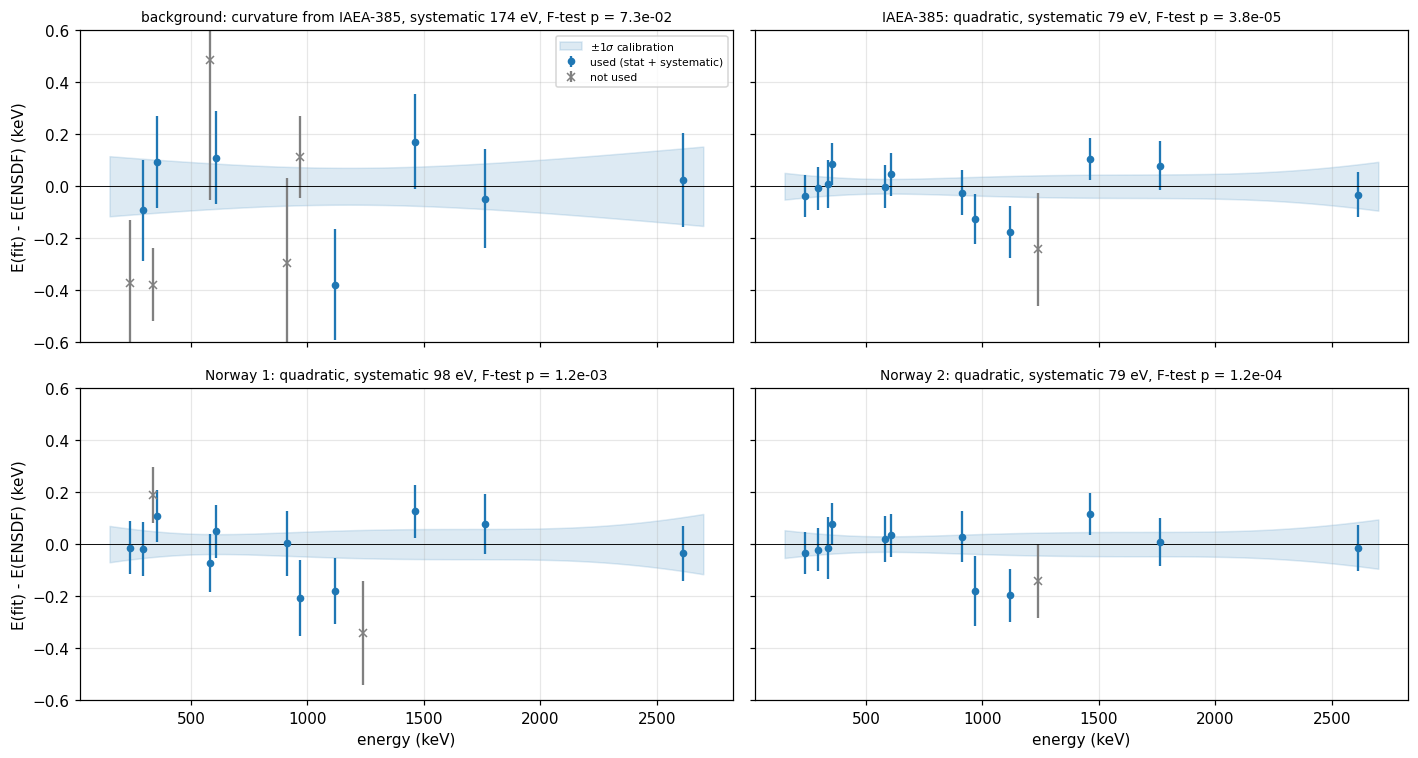

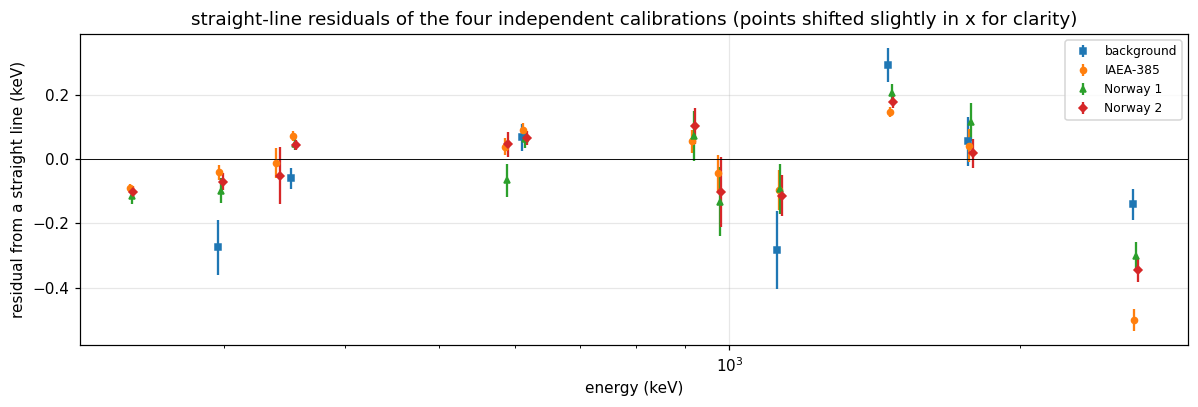

correlation of the straight-line residual patterns between the sample spectra:
          IAEA-385  Norway 1  Norway 2
IAEA-385      1.00      0.87      0.95
Norway 1      0.87      1.00      0.93
Norway 2      0.95      0.93      1.00
  spectrum     line  position  sposition  shift_vs_IAEA_ch  significance  shift_keV
background  609.321  3618.626      0.250             0.214         0.767      0.036
background 1460.820  8674.115      0.312             0.014         0.045      0.002
background 2614.511 15519.400      0.291            -0.329        -0.916     -0.055
  IAEA-385  609.321  3618.412      0.125             0.000         0.000      0.000
  IAEA-385 1460.820  8674.101      0.086             0.000         0.000      0.000
  IAEA-385 2614.511 15519.728      0.209             0.000         0.000      0.000
  Norway 1  609.321  3618.319      0.176            -0.093        -0.430     -0.016
  Norway 1 1460.820  8674.065      0.160            -0.036        -0.197     -0.006
  Norway 

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True)
Eg = np.linspace(150, 2700, 300)
for ax, (k, t) in zip(axes.flat, lines.items()):
    cal = cals[k]
    band = cal.sigma(cal.channel(Eg))
    ax.fill_between(Eg, -band, band, color="tab:blue", alpha=0.15, label=r"$\pm1\sigma$ calibration")
    u, nu = t[t.used], t[~t.used]
    ax.errorbar(u.E_ref, u.resid_keV, yerr=np.hypot(u.sE_stat, cal.sys), fmt="o", color="tab:blue", ms=4,
                label="used (stat + systematic)")
    ax.errorbar(nu.E_ref, nu.resid_keV, yerr=nu.sE_stat, fmt="x", color="0.5", ms=5, label="not used")
    ax.axhline(0, color="k", lw=0.6)
    row = cal_summary.set_index("spectrum").loc[k]
    ax.set_title(f"{k}: {row.adopted}, systematic {1000 * row.sys_keV:.0f} eV, F-test p = {row.p_F:.1e}", fontsize=9)
    ax.set_ylim(-0.6, 0.6)
for ax in axes[1]:
    ax.set_xlabel("energy (keV)")
for ax in axes[:, 0]:
    ax.set_ylabel("E(fit) - E(ENSDF) (keV)")
axes[0, 0].legend(fontsize=7)
fig.tight_layout(); save(fig, "calibration_residuals"); plt.show()

# The same straight-line residuals in every spectrum would mean the electronics, not statistics.
fig, ax = plt.subplots(figsize=(11, 3.8))
for (k, t), mk in zip(lines.items(), ["s", "o", "^", "D"]):
    u = t[t.used]
    ax.errorbar(u.E_ref * (1 + 0.004 * list(lines).index(k)), u.resid_lin_keV, yerr=u.sE_stat, fmt=mk, ms=4, label=k)
ax.axhline(0, color="k", lw=0.6)
ax.set(xscale="log", xlabel="energy (keV)", ylabel="residual from a straight line (keV)",
       title="straight-line residuals of the four independent calibrations (points shifted slightly in x for clarity)")
ax.legend(fontsize=8)
fig.tight_layout(); save(fig, "nonlinearity_pattern"); plt.show()
common = pd.concat({k: t.set_index("E_ref").resid_lin_keV[t.set_index("E_ref").used] for k, t in lines.items()
                    if k != BACKGROUND}, axis=1)
print("correlation of the straight-line residual patterns between the sample spectra:")
print(common.corr().round(2).to_string())

ref = "IAEA-385"
drift = []
for k in specs:
    for E in (609.321, 1460.820, 2614.511):
        a = lines[k].set_index("E_ref").loc[E]
        b = lines[ref].set_index("E_ref").loc[E]
        drift.append(dict(spectrum=k, line=E, position=a.position, sposition=a.sposition,
                          shift_vs_IAEA_ch=a.position - b.position,
                          significance=(a.position - b.position) / np.hypot(a.sposition, b.sposition),
                          shift_keV=(a.position - b.position) * cals[ref].gain(b.position)))
drift = pd.DataFrame(drift)
table(drift, 3)

Three results stand out.

* **The energy scale is not a straight line.** For the three sample spectra a straight line gives $\chi^2$ of 147 to 363 for 9 or 10 degrees of freedom. A quadratic term lowers this to 37 to 50 (F-test p from $4\times10^{-5}$ to $1\times10^{-3}$), so the quadratic is adopted. Its coefficient is about $5$ to $6\times10^{-9}$ keV per channel squared in every spectrum, which bends the scale by about 0.4 keV in the middle of the range relative to a straight line through its ends. The session-1 detector with the DSPEC-LF needed no such term, so the curvature belongs to the new electronics.
* **What remains is a property of the electronics, not of the statistics.** Even the quadratic leaves $\chi^2$ about four times the number of degrees of freedom, and the second figure shows why. The straight-line residuals of the four independent spectra follow the same zigzag (correlations of 0.87 to 0.95 between the sample spectra), for example $+0.15$ to $+0.21$ keV at K-40 against $-0.30$ to $-0.50$ keV at 2614.5 keV. A pattern that repeats in every run is fixed in the ADC. It is the integral non-linearity, the small deviation of a real ADC from a perfectly linear conversion, here below 0.01 % of the 2760 keV full scale after the quadratic, which is within what spectroscopy ADCs are normally specified to. A low-order polynomial cannot follow such wiggles, so instead of pretending they are noise we add a per-line systematic in quadrature, chosen so that $\chi^2/\nu = 1$. It comes out at 79 to 98 eV for the sample spectra and 174 eV for the weak background, and it is included in every energy uncertainty quoted from here on. The background lines are too weak to show the curvature themselves (F-test $p = 0.07$), so the background borrows the curvature measured in IAEA-385, since the ADC is the same in every run, and fits only its own offset and gain.
* **There is no measurable gain drift.** Over two weeks the positions of the 609.3, 1460.8 and 2614.5 keV lines agree with IAEA-385 to within 0.33 channels (0.055 keV), and no shift exceeds 1.2 standard deviations. Separate calibrations are kept for every spectrum anyway, since they cost nothing and would absorb drift too small for us to see.

### Reading the calibration diagnostics

Residuals compare fitted energies with reference energies. A smooth bend suggests an insufficient polynomial order; a repeated non-smooth pattern suggests a shared systematic effect. Repetition makes independent counting noise unlikely, but does not uniquely isolate the ADC: shared line blends, peak-shape assumptions and reference choices can also repeat. An electronic pulser or additional clean calibration lines would help distinguish these explanations.

For coefficients $\boldsymbol a=(a_0,a_1,a_2)$ and $\boldsymbol v=(1,x,x^2)$, coefficient uncertainty contributes
$$\sigma_{\mathrm{coeff}}^2(E)=\boldsymbol v^\mathsf{T}\operatorname{Cov}(\boldsymbol a)\boldsymbol v.$$
The off-diagonal terms matter because polynomial coefficients are correlated. An independently measured peak position contributes approximately $[E'(x)\sigma_x]^2$ as well. The residual systematic floor describes departures from the smooth calibration; it is not detector resolution and does not disappear with longer counting.

The saved summary gives floors of 0.079–0.098 keV for the samples and 0.174 keV for the background. The weak background borrows curvature from IAEA-385, making their calibrations dependent. A floor chosen to bring reduced $\chi^2$ to unity cannot subsequently serve as independent proof of calibration accuracy. The unused Cs-137 line provides a stronger check.

### How the choice of position definition and model changes the calibration
Section 7 showed that the mode, the Gaussian centre and the mean of a skewed peak differ. Each spectrum's calibration is built from modes. Here we rebuild the IAEA-385 calibration from each of the other definitions, and from the old pipeline of Section 5 (Gaussian plus step), and see how far the energy scale moves. If the shift were the same for every line it would be absorbed into the offset and do no harm, but the tail grows with the width, which grows with energy, so the shift is not uniform.

In [15]:
t = lines["IAEA-385"]
u = t[t.used]
deg, sys0 = cals["IAEA-385"].degree, cals["IAEA-385"].sys          # same polynomial and systematic for every variant
variants = {}
variants["EMG mode (adopted)"] = cals["IAEA-385"]
variants["EMG mean (mu - beta)"] = G.fit_calibration(u["mean"], u.sposition, u.E_ref, u.sE_ref, degree=deg, sys_keV=sys0)
variants["EMG Gaussian centre mu"] = G.fit_calibration(u.mu, u.smu, u.E_ref, u.sE_ref, degree=deg, sys_keV=sys0)
tg, _ = G.fit_lines(specs["IAEA-385"], rough["IAEA-385"], tail_ratio=0.0, step=0.0)
variants["Gaussian fit, no step"] = G.fit_calibration(tg.position[u.index], tg.sposition[u.index], u.E_ref, u.sE_ref,
                                                      degree=deg, sys_keV=sys0)
tgs, _ = G.fit_lines(specs["IAEA-385"], rough["IAEA-385"], tail_ratio=0.0, step="free")
variants["Gaussian + free step (old model)"] = G.fit_calibration(tgs.position[u.index], tgs.sposition[u.index], u.E_ref,
                                                                 u.sE_ref, degree=deg, sys_keV=sys0)
variants["old pipeline as run in Section 5 (linear, 10 lines)"] = G.Calibration(
    np.array(cal_old_code.a), np.array(cal_old_code.C), cal_old_code.chi2, cal_old_code.ndf)
probe_E = np.array([46.539, 100.0, 238.632, 661.657, 1460.820, 2614.511])
base = variants["EMG mode (adopted)"]
probe_x = base.channel(probe_E)
rows = []
for name, c in variants.items():
    rows.append(dict(variant=name, chi2=c.chi2, ndf=c.ndf, **{f"dE {E:.0f}": float(c.energy(x) - base.energy(x))
                                                               for E, x in zip(probe_E, probe_x)}))
defs = pd.DataFrame(rows)
table(defs, 3)
print(f"\nstatistical calibration uncertainty of the adopted fit at the same energies (keV): "
      f"{np.round(base.sigma(probe_x), 3)}")

                                            variant    chi2  ndf  dE 47  dE 100  dE 239  dE 662  dE 1461  dE 2615
                                 EMG mode (adopted)   9.000    9  0.000   0.000   0.000   0.000    0.000    0.000
                               EMG mean (mu - beta)   9.054    9  0.015   0.016   0.017   0.022    0.031    0.042
                             EMG Gaussian centre mu   8.540    9 -0.127  -0.133  -0.148  -0.191   -0.266   -0.356
                              Gaussian fit, no step   8.836    9  0.007   0.008   0.009   0.012    0.019    0.031
                   Gaussian + free step (old model)  12.404    9  0.011   0.008   0.002  -0.013   -0.022    0.009
old pipeline as run in Section 5 (linear, 10 lines) 305.916    8 -0.113  -0.091  -0.039   0.066    0.051   -0.462

statistical calibration uncertainty of the adopted fit at the same energies (keV): [0.062 0.057 0.043 0.029 0.044 0.084]


The choice of position definition matters exactly as Section 7 predicted. Calibrating with the Gaussian centre $\mu$ of the EMG would make every energy 0.13 to 0.36 keV too low, several times the statistical calibration uncertainty (0.03 to 0.08 keV), because $\mu$ sits above the visible top of the peak, by about $0.36\,\sigma$ for this tail. The mean, a plain Gaussian fit and the old Gaussian-plus-step model all move the scale by at most 0.04 keV on this detector, so any of them would be acceptable, provided the same definition is used for every line, while mixing $\mu$ with any of the others would not be. The last row is the old pipeline as it was actually run in Section 5. It is off by up to 0.46 keV at 2614.5 keV, and that error comes almost entirely from the missing curvature, not from the peak model.

## 9. Energy resolution and tail of the new detector

### Why
The width of a peak decides whether two nearby lines can be separated, how many continuum counts lie under a peak (and hence the detection limit), and it lets us fix the width when fitting weak peaks, which makes those fits far more stable. A smooth model of the width against energy is also a physical fingerprint of the detector, which we compare with the session-1 detector in Section 12.

### Where the width comes from
Three independent effects add in quadrature,
$$ \text{FWHM}^2 = w_0^2 + w_1^2\,E + w_2^2\,E^2 . $$
* $w_0$ is electronic noise (leakage current and preamplifier), independent of energy.
* $w_1^2 E$ is carrier statistics. With $N = E/\varepsilon$ pairs and variance $FN$, the width is $2.355\sqrt{F\varepsilon E}$, so $w_1^2 = 2.355^2 F\varepsilon$ and the Fano factor follows from $w_1$.
* $w_2^2E^2$ collects effects proportional to the signal, such as incomplete charge collection and slow gain drift during the run.

We fit the model to the Gaussian width parameter $\sigma$ of the EMG (converted to a FWHM with the local gain), because that part of the shape is what the three effects describe, while the tail is described separately by $\beta = \tau\sigma$. For comparison with other detectors and with InterSpec we also report the actual FWHM of the skewed peak. Lines from the three sample spectra are pooled, since they come from the same detector.

In [16]:
pool = []
for k in shape_spectra:
    t = lines[k][lines[k].used].copy()
    gain = cals[k].gain(t.position)
    t["fwhm_gauss_keV"] = G.FWHM_PER_SIGMA * t.sigma_ch * gain
    t["s_fwhm_gauss_keV"] = G.FWHM_PER_SIGMA * t.ssigma_ch * gain
    t["fwhm_keV"] = t.fwhm_ch * gain
    t["s_fwhm_keV"] = t.sfwhm_ch * gain
    t["spectrum"] = k
    pool.append(t)
pool = pd.concat(pool, ignore_index=True)
W, W_cov, W_chi2, W_ndf = G.fit_resolution(pool.E_ref.values, pool.fwhm_gauss_keV.values, pool.s_fwhm_gauss_keV.values)
WT, WT_cov, WT_chi2, WT_ndf = G.fit_resolution(pool.E_ref.values, pool.fwhm_keV.values, pool.s_fwhm_keV.values)
fano, s_fano = G.fano_from_w1(W[1], np.sqrt(W_cov[1, 1]))
sigma_keV = lambda E: G.fwhm_model(E, *W) / G.FWHM_PER_SIGMA          # Gaussian part, used for fixed-shape fits
beta_keV = lambda E: TAU * sigma_keV(E)
print(f"{len(pool)} line measurements from {', '.join(shape_spectra)}")
print(f"Gaussian part: w0 = {W[0]:.3f} +- {np.sqrt(W_cov[0, 0]):.3f} keV, w1 = {W[1]:.4f} +- {np.sqrt(W_cov[1, 1]):.4f} keV^1/2, "
      f"w2 = {W[2]:.2e} +- {np.sqrt(W_cov[2, 2]):.1e}, chi2/ndf = {W_chi2:.1f}/{W_ndf}")
print(f"   Fano factor from w1: F = {fano:.3f} +- {s_fano:.3f}")
print(f"actual FWHM of the skewed peak: w0 = {WT[0]:.3f}, w1 = {WT[1]:.4f}, w2 = {WT[2]:.2e}, chi2/ndf = {WT_chi2:.1f}/{WT_ndf}")
for E in (59.54, 122.06, 661.657, 1332.49, 1460.82, 2614.511):
    print(f"   {E:8.2f} keV: Gaussian-part FWHM {G.fwhm_model(E, *W):.3f} keV, actual FWHM {G.fwhm_model(E, *WT):.3f} keV, "
          f"tail beta {beta_keV(E):.3f} keV, FWHM = {G.fwhm_model(E, *WT) / cals['IAEA-385'].gain(cals['IAEA-385'].channel(E)):.1f} channels")

35 line measurements from IAEA-385, Norway 1, Norway 2
Gaussian part: w0 = 0.757 +- 0.039 keV, w1 = 0.0384 +- 0.0022 keV^1/2, w2 = 3.83e-04 +- 9.8e-05, chi2/ndf = 30.3/32
   Fano factor from w1: F = 0.090 +- 0.010
actual FWHM of the skewed peak: w0 = 0.803, w1 = 0.0407, w2 = 4.06e-04, chi2/ndf = 30.3/32
      59.54 keV: Gaussian-part FWHM 0.813 keV, actual FWHM 0.862 keV, tail beta 0.137 keV, FWHM = 5.1 channels
     122.06 keV: Gaussian-part FWHM 0.869 keV, actual FWHM 0.921 keV, tail beta 0.147 keV, FWHM = 5.5 channels
     661.66 keV: Gaussian-part FWHM 1.270 keV, actual FWHM 1.346 keV, tail beta 0.214 keV, FWHM = 8.0 channels
    1332.49 keV: Gaussian-part FWHM 1.672 keV, actual FWHM 1.773 keV, tail beta 0.282 keV, FWHM = 10.5 channels
    1460.82 keV: Gaussian-part FWHM 1.743 keV, actual FWHM 1.848 keV, tail beta 0.294 keV, FWHM = 11.0 channels
    2614.51 keV: Gaussian-part FWHM 2.329 keV, actual FWHM 2.470 keV, tail beta 0.393 keV, FWHM = 14.7 channels


The three-term model fits the 35 widths well ($\chi^2 = 30.3$ for 32 degrees of freedom). The electronic-noise term is $w_0 = 0.76 \pm 0.04$ keV and dominates below about 390 keV (where $w_1^2E = w_0^2$), and the carrier-statistics term gives a Fano factor $F = 0.090 \pm 0.010$, consistent with the accepted value of about 0.1 for germanium. The actual FWHM of the skewed peak is about 6 % larger than its Gaussian part, 0.92 keV at 122 keV, 1.35 keV at 662 keV, 1.77 keV at 1332 keV and 2.47 keV at 2614.5 keV. At 1460.8 keV a peak spans 11 channels and at 59.5 keV about 5, so every peak is sampled by many bins. Compared with the session-1 detector (1.30, 2.00 and 2.65 keV at the same energies, Section 12) the new system resolves about 30 % better at low energy and 7 to 12 % better at high energy. The gain is mostly in the noise term $w_0$, which falls with the capacitance of the detector and the noise of the preamplifier and filter, so a smaller crystal, a quieter front end or a better digital filter could each explain it. The session-1 Fano factor found here (0.088) is lower than the 0.104 of the session-1 notebook, because that notebook fitted symmetric Gaussians whose width also absorbed the tail.

### Resolution is not energy uncertainty

FWHM describes the spread of individual full-energy events. A strong peak's position can be measured much more precisely: for an isolated Gaussian with $N$ counts and negligible background, its centroid error scales as $\sigma/\sqrt N$. Background and overlapping peaks weaken this ideal relation. Thus an eV-scale statistical position error can coexist with a keV-scale peak width, while absolute energy accuracy remains limited by calibration systematics.

The three resolution terms form an effective description. Interpreting the energy-linear variance term as a Fano factor assumes that other energy-dependent broadening has been separated correctly. Keep Gaussian-core width distinct from full EMG FWHM when comparing detectors or software.

## 10. Every peak in every spectrum

### Method
With the calibration, the resolution model and the tail model in hand, the matched-filter search is repeated with the width every channel should have, and every candidate with $S > 5$ is fitted with the EMG whose width and tail are fixed from the smooth models. Fixing the shape leaves only the area, position and continuum free, which keeps fits of weak peaks stable and makes the areas of different peaks directly comparable. Strong isolated peaks ($S > 10$) are the exception. They are fitted with the width free (the tail still tied to it), so that a line that is not an ordinary photopeak, such as the Doppler-broadened 511 keV annihilation line, is not forced into the wrong shape. Candidates closer than 10 widths are fitted together, since a neighbour inside the window would otherwise distort the continuum. Each fitted energy is then matched to every library line (ENSDF gamma lines plus annihilation, escape peaks, X-rays and neutron-induced germanium lines) within $\max(0.5\text{ keV}, 3s_E)$.

### A second, independent test of the calibration
Only 13 lines went into each calibration, but the inventory contains many more lines of known energy. Lines that were not used in the fit test the calibration independently, in the same spirit as cross-validation. If the calibration is right their residuals scatter around zero at all energies, including below 238 keV, where we have no calibration line and where any non-linearity of the ADC would show.

In [17]:
library = G.build_library()
inv = {k: G.fit_inventory(s, cals[k], sigma_keV, TAU, library) for k, s in specs.items()}
for k, df in inv.items():
    print(f"{k:10s}: {len(df):3d} peaks with S > 5, {np.sum(df.source != 'unidentified'):3d} matched to a library line")
cols = ["E_keV", "sE_keV", "S", "area", "s_area", "rate_cpd", "source", "E_lib", "dE", "other"]
print("\nIAEA-385 inventory")
with pd.option_context("display.width", 250, "display.max_colwidth", 45):
    print(inv["IAEA-385"][cols].round(2).to_string(index=False))

background:   7 peaks with S > 5,   7 matched to a library line
IAEA-385  :  19 peaks with S > 5,  18 matched to a library line
Norway 1  :  16 peaks with S > 5,  15 matched to a library line
Norway 2  :  18 peaks with S > 5,  17 matched to a library line

IAEA-385 inventory
  E_keV  sE_keV     S    area  s_area  rate_cpd       source   E_lib    dE            other
  36.13    0.11  6.74 1240.39   84.52    306.40 unidentified     NaN   NaN                 
  74.86    0.10 11.76 1053.82   58.59    260.32  Bi K-alpha2   74.82  0.04 Pb K-alpha1 75.0
  77.12    0.10 10.82 1045.18   57.51    258.18  Bi K-alpha1   77.11  0.01                 
  87.33    0.11  5.54  447.32   53.50    110.50   Bi K-beta1   87.34 -0.01  Pb K-beta2 87.3
 238.58    0.09 23.83 2927.64   87.32    723.19       Pb-212  238.63 -0.05                 
 295.22    0.09 13.85 1243.95   67.22    307.28       Pb-214  295.22 -0.01                 
 338.33    0.10  7.96  622.85   47.74    153.86       Ac-228  338.32  0.01     R

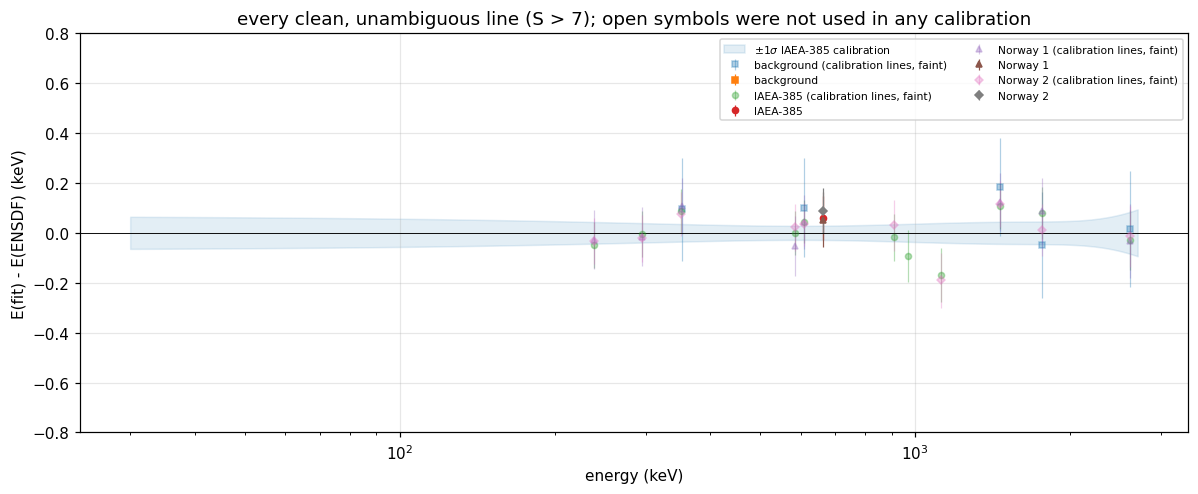

independent lines 230 keV and above: 3 lines, weighted mean offset +0.068 +- 0.055 keV, chi2 = 0.1 for 2 dof
spectrum   E_keV source   E_lib    dE  sE_keV      S
Norway 1 661.710 Cs-137 661.657 0.053   0.111 11.342
IAEA-385 661.716 Cs-137 661.657 0.059   0.087 17.849
Norway 2 661.746 Cs-137 661.657 0.089   0.091 11.426


In [18]:
not_single = ["X-ray", "single escape", "double escape", "fast neutrons in the crystal",
              "positrons (cosmic rays and pair production)"]
fig, ax = plt.subplots(figsize=(11, 4.6))
Eg = np.linspace(30, 2700, 400)
band = cals["IAEA-385"].sigma(cals["IAEA-385"].channel(Eg))
ax.fill_between(Eg, -band, band, color="tab:blue", alpha=0.12, label=r"$\pm1\sigma$ IAEA-385 calibration")
marks = dict(zip(specs, ["s", "o", "^", "D"]))
validation = []
for k, df in inv.items():
    clean = df[~df.origin.isin(not_single) & (df.source != "unidentified") & df.other.eq("") & (df.S > 7)].copy()
    clean["calibration_line"] = [np.isclose(E, [l[1] for l in G.NATURAL_LINES], atol=0.01).any() for E in clean.E_lib]
    clean["spectrum"] = k
    validation.append(clean)
    for used, alpha in ((True, 0.35), (False, 1.0)):
        d = clean[clean.calibration_line == used]
        ax.errorbar(d.E_keV, d.dE, yerr=d.sE_keV, fmt=marks[k], ms=4, alpha=alpha, lw=0.8,
                    label=f"{k}" + (" (calibration lines, faint)" if used else ""))
validation = pd.concat(validation, ignore_index=True)
ax.axhline(0, color="k", lw=0.6)
ax.set_xscale("log")
ax.set(xlabel="energy (keV)", ylabel="E(fit) - E(ENSDF) (keV)", ylim=(-0.8, 0.8),
       title="every clean, unambiguous line (S > 7); open symbols were not used in any calibration")
ax.legend(fontsize=7, ncol=2)
fig.tight_layout(); save(fig, "calibration_check_all_lines"); plt.show()

indep = validation[~validation.calibration_line]
for name, sel in [("below 230 keV", indep.E_lib < 230), ("230 keV and above", indep.E_lib >= 230)]:
    d = indep[sel]
    if len(d):
        w = 1 / d.sE_keV**2
        m = np.sum(w * d.dE) / w.sum()
        print(f"independent lines {name}: {len(d)} lines, weighted mean offset {m:+.3f} +- {1 / np.sqrt(w.sum()):.3f} keV, "
              f"chi2 = {np.sum(w * (d.dE - m)**2):.1f} for {len(d) - 1} dof")
table(indep.sort_values("E_keV")[["spectrum", "E_keV", "source", "E_lib", "dE", "sE_keV", "S"]], 3)

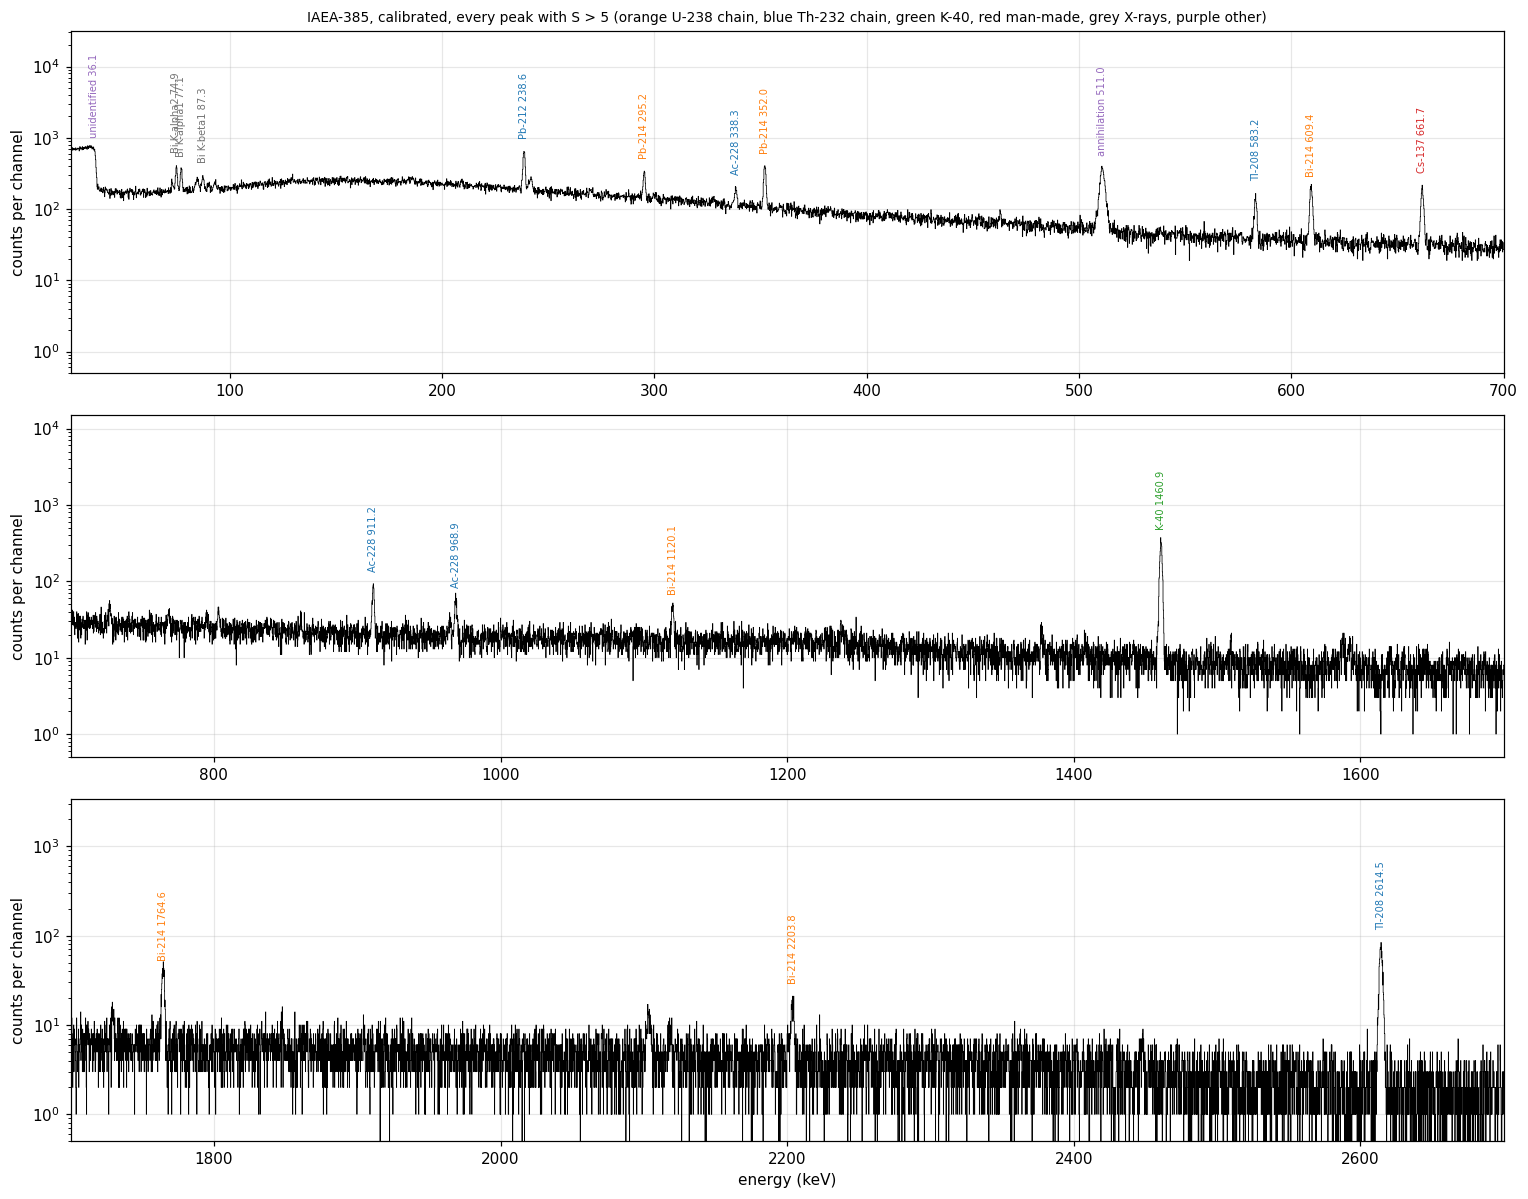

In [19]:
family = {"U-238": "tab:orange", "U-235": "tab:brown", "Th-232": "tab:blue", "primordial": "tab:green",
          "anthropogenic": "tab:red", "X-ray": "0.45"}
colour = lambda origin: next((c for key, c in family.items() if key in str(origin)), "tab:purple")
k = "IAEA-385"
s, cal, df = specs[k], cals[k], inv[k]
E_c = cal.energy(s.channels)
fig, axes = plt.subplots(3, 1, figsize=(14, 11))
for ax, (lo_E, hi_E) in zip(axes, [(25, 700), (700, 1700), (1700, 2700)]):
    m = (E_c >= lo_E) & (E_c <= hi_E)
    ax.step(E_c[m], np.maximum(s.counts[m], 0.5), where="mid", lw=0.5, color="k")
    ax.set_yscale("log")
    for r in df[(df.E_keV >= lo_E) & (df.E_keV <= hi_E)].itertuples():
        ax.annotate(f"{r.source} {r.E_keV:.1f}", (r.E_keV, s.counts[int(round(r.position))]), xytext=(0, 8),
                    textcoords="offset points", rotation=90, fontsize=6.5, color=colour(r.origin), ha="center", va="bottom")
    ax.set_xlim(lo_E, hi_E)
    ax.set_ylim(0.5, s.counts[m].max() * 40)
    ax.set_ylabel("counts per channel")
axes[0].set_title(f"{k}, calibrated, every peak with S > 5 (orange U-238 chain, blue Th-232 chain, green K-40, "
                  f"red man-made, grey X-rays, purple other)", fontsize=9)
axes[-1].set_xlabel("energy (keV)")
fig.tight_layout(); save(fig, "IAEA385_labelled"); plt.show()

The search finds 7 peaks in the empty-shield background and 16 to 19 in the sample spectra, and all but one in each sample spectrum match a library line. The exception, near 36 keV, is not a peak at all but the edge of the continuum step described in Section 12. The samples contain what a sediment should, namely the Th-232 chain (Pb-212, Ac-228, Tl-208), the U-238 chain through radon (Pb-214, Bi-214), K-40, Cs-137 from fallout, the 511 keV annihilation line and Pb and Bi X-rays. The 511 keV line, fitted with its width free, comes out about twice as wide as a photopeak because of the Doppler broadening from the motion of the electrons with which the positrons annihilate. A fixed width would have lost almost half of its area, which is why strong isolated peaks are fitted with free width.

The independent test of the calibration is limited, because most strong lines were used in the calibrations. The Cs-137 line at 661.657 keV, used in none of them, is reproduced to $+0.068 \pm 0.055$ keV on average in the three samples, consistent with zero within the calibration systematic. Below 230 keV no clean gamma line is strong enough for the test, and the Pb and Bi X-rays near 75 keV are composite lines whose nominal energies confirm the scale only to about 0.1 keV, so the calibration below 238 keV is an extrapolation of the quadratic and should be quoted with that caveat.

### A search candidate is not an isotope identification

Searching many channels and widths creates multiple opportunities for noise or continuum structure to resemble a line. The search threshold selects candidates; it is not a global discovery probability. Fit residuals, expected width and other lines of the proposed isotope provide further checks. The 36 keV feature demonstrates why a search alone is insufficient.

Non-detection does not establish zero activity. An upper limit needs a stated confidence level and a procedure handling the non-negative signal boundary and background uncertainty. Blends also need care: the 186 keV feature cannot separately determine Ra-226 and U-235 without additional information. Low-energy identifications remain especially sensitive to the unvalidated calibration extrapolation.

## 11. Old against new on the same spectrum

### Why
Section 5 showed that the old code fails at the start but runs once it is given the right calibration. The last question about it is whether its results would then be good enough, or whether the new peak model changes the numbers we will actually use. We run the complete old inventory (`H.peak_search` and `H.fit_inventory`, with the old Gaussian plus step model) on IAEA-385, giving it our calibration and resolution model, and match its peaks to the new inventory.

old inventory: 21 peaks, new inventory: 19 peaks, matched within 0.6 keV: 19
strong peaks (S > 10, 13): median area ratio new/old 1.0036, mean energy difference old - new -9.4 eV (spread 4.5 eV)
      source    E_new  dE_old_minus_new  sE_new  area_new  area_old  area_ratio_new_old  s_ratio      S
unidentified   36.127             0.012   0.105  1240.385  1165.063               1.065    0.073  6.742
 Bi K-alpha2   74.860            -0.005   0.102  1053.824  1012.676               1.041    0.058 11.761
 Bi K-alpha1   77.117            -0.006   0.102  1045.175  1007.162               1.038    0.057 10.818
  Bi K-beta1   87.332            -0.006   0.113   447.321   432.065               1.035    0.124  5.538
      Pb-212  238.583            -0.006   0.091  2927.641  2915.549               1.004    0.030 23.830
      Pb-214  295.219            -0.006   0.091  1243.953  1239.545               1.004    0.054 13.855
      Ac-228  338.335             0.000   0.097   622.854   596.341          

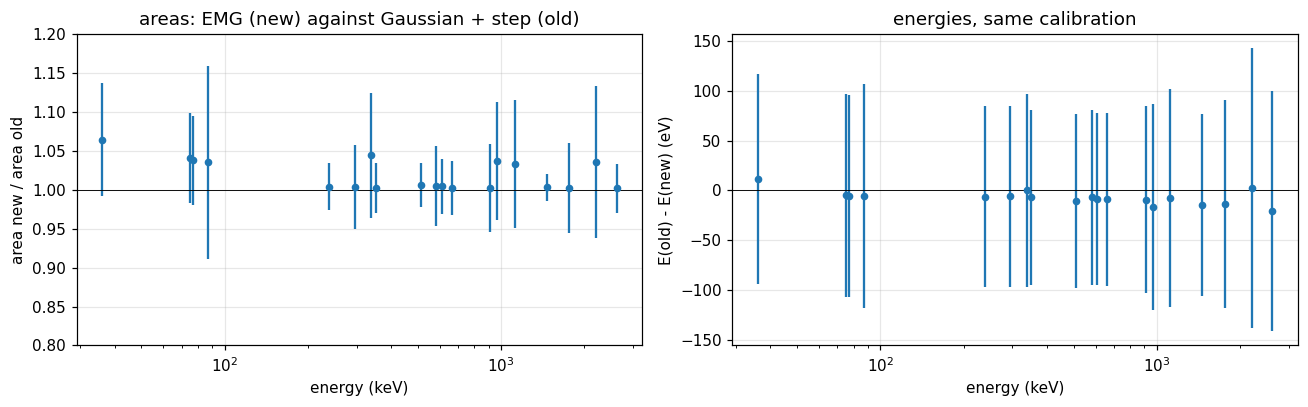

In [20]:
k = "IAEA-385"
s, cal = specs[k], cals[k]                       # the same (adopted) calibration for old and new code
cal_H = H.Calibration(a=np.array(cal.a), C=np.array(cal.C), chi2=cal.chi2, ndf=cal.ndf, scale=cal.scale)
sigma_model_ch = lambda E: sigma_keV(E) / cal.gain(cal.channel(E))
cands_old, S_old = H.peak_search(s.counts, sigma_model_ch(cal.energy(s.channels)), 5.0)
inv_old = H.fit_inventory(s.counts, cands_old, S_old, cal_H, sigma_model_ch, R_STEP_OLD, H.build_library(), s.live)
new = inv[k]
pairs = []
for r in inv_old.itertuples():
    j = (new.E_keV - r.E_keV).abs().idxmin()
    if abs(new.E_keV[j] - r.E_keV) < 0.6:
        pairs.append(dict(source=new.source[j], E_new=new.E_keV[j], dE_old_minus_new=r.E_keV - new.E_keV[j],
                          sE_new=new.sE_keV[j], area_new=new.area[j], area_old=r.area,
                          area_ratio_new_old=new.area[j] / r.area, s_ratio=new.area[j] / r.area * new.s_area[j] / new.area[j],
                          S=new.S[j]))
pairs = pd.DataFrame(pairs)
print(f"old inventory: {len(inv_old)} peaks, new inventory: {len(new)} peaks, matched within 0.6 keV: {len(pairs)}")
strong = pairs[pairs.S > 10]
print(f"strong peaks (S > 10, {len(strong)}): median area ratio new/old {strong.area_ratio_new_old.median():.4f}, "
      f"mean energy difference old - new {strong.dE_old_minus_new.mean() * 1000:+.1f} eV "
      f"(spread {strong.dE_old_minus_new.std() * 1000:.1f} eV)")
table(pairs.sort_values("E_new"), 3)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].errorbar(pairs.E_new, pairs.area_ratio_new_old, yerr=pairs.s_ratio, fmt="o", ms=4)
axes[0].axhline(1, color="k", lw=0.6)
axes[0].set(xscale="log", xlabel="energy (keV)", ylabel="area new / area old", ylim=(0.8, 1.2),
            title="areas: EMG (new) against Gaussian + step (old)")
axes[1].errorbar(pairs.E_new, 1000 * pairs.dE_old_minus_new, yerr=1000 * pairs.sE_new, fmt="o", ms=4)
axes[1].axhline(0, color="k", lw=0.6)
axes[1].set(xscale="log", xlabel="energy (keV)", ylabel="E(old) - E(new) (eV)", title="energies, same calibration")
fig.tight_layout(); save(fig, "old_vs_new_inventory"); plt.show()

With the same calibration and resolution model, the old and new inventories agree closely. Every one of the 19 new peaks has an old counterpart within 0.6 keV (the old search also returned two extra weak candidates). For the 13 strong peaks the energies differ by only $-9.4$ eV on average, with a spread of 4.5 eV, and the areas by a median of 0.36 %. Weak peaks and X-rays differ more (3 to 7 %), because the tail moves a larger fraction of a small peak's counts relative to its continuum. The old fitting code is therefore sound. What failed on the new data was its input and starting point (Sections 5 and 6) and its straight-line calibration (Section 8), not its peak fitting. On this detector the EMG changes the strong-peak results at the per-mille level, well inside their statistical errors, and it matters more for weak peaks and for any detector with a longer tail.

## 12. How different is the new setup? Comparing the two backgrounds

### What changed between the sessions
* **The detector.** A different germanium crystal, with its own size (hence efficiency), resolution, tailing and internal contamination.
* **The electronics.** A Lynx digital MCA instead of an ORTEC DSPEC-LF, with its own gain, threshold and filter settings.
* **The location.** Session 1 was measured on the third floor, session 2 in the basement.

### What the location should change, and why
* **Cosmic rays.** At sea level the secondary cosmic radiation consists mainly of muons, plus neutrons and electrons. The electrons and neutrons are absorbed in a few hundred g/cm² of material (the hadronic component has an attenuation length of roughly 150 to 200 g/cm²), while muons are far more penetrating and lose only about 2 MeV per g/cm². Several floors of concrete above a basement amount to a few hundred g/cm², so the neutron flux in the basement should be much lower than on the third floor and the muon flux somewhat lower. Muons give a smooth continuum up to many MeV and, through pair production and positron annihilation, a 511 keV line. Fast neutrons give the inelastic-scattering features of Ge-74 at 596 keV and Ge-72 at 691 keV, which have a characteristic sawtooth shape because the nuclear recoil energy adds to the gamma energy.
* **Radon.** Basements are close to the soil, which is the main source of Rn-222, and are often poorly ventilated, so the radon concentration (and the Pb-214 and Bi-214 lines it feeds) is usually higher underground. Radon inside the shield shows up directly in the background spectrum.
* **Walls.** A basement is surrounded by more concrete and soil, which raises the flux of K-40 and chain gammas outside the shield. How much of it reaches the crystal depends on the shield.

### How to compare two different detectors fairly
Raw rates are not directly comparable, because the detectors differ in size and efficiency. We therefore use three kinds of evidence.
1. **Properties of the system** that do not depend on the environment, such as gain, range, threshold, resolution and peak shape.
2. **Ratios of lines at nearly the same energy**, where the efficiency of one detector cancels. Bi-214 at 609.3 keV (radon daughter) and Tl-208 at 583.2 keV (thorium chain in the walls and shield) differ by only 26 keV, so the ratio of their rates, divided by their emission probabilities, measures the radon-to-thorium activity seen by each detector almost independently of its efficiency.
3. **Shapes and large factors.** Where two setups differ by factors of ten or more, the detector size cannot explain it.

The session-1 spectrum is analysed here with the new code (automatic calibration, shared tail fitted to its own lines, its own resolution model), which also checks that the new code reproduces the session-1 calibration made with the old code.

session 1 with the new code: tau = 0.454 +- 0.033, 13 lines, E = 0.281 +- 0.026 + (0.19710194 +- 0.00000377) x
session 1 with the old code (s1_energy_calibration.json): E = 0.287 +- 0.031 + (0.19710345 +- 0.00000450) x
   difference at 1460.8 keV: +16.9 eV, at 2614.5 keV: +25.7 eV

setup                       session 1 (3rd floor) session 2 (basement)
MCA / format                            ortec-chn             lynx-csv
channels                                    16384                16384
gain keV/ch                              0.197102             0.168474
range keV                             0.2 to 3230          0.0 to 2760
threshold edge keV                      10.136463             1.609656
counts below 10 keV %                         0.0            11.891675
live d                                   3.882607             2.936305
dead %                                   0.117647             0.019382
total cps                                6.361503             2.152124
cps abo

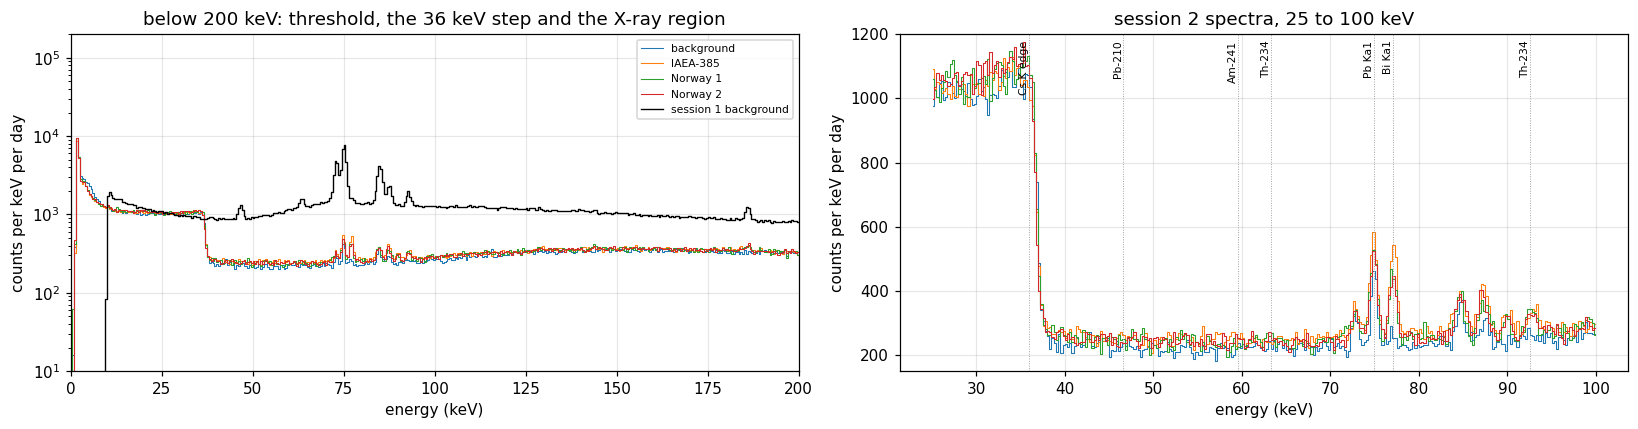

background: continuum 25-35 keV  1029.1 +-  5.9, 38-48 keV  234.9 +-  2.8 counts/keV/day, ratio 4.38
IAEA-385  : continuum 25-35 keV  1050.1 +-  5.1, 38-48 keV  260.2 +-  2.5 counts/keV/day, ratio 4.04
Norway 1  : continuum 25-35 keV  1059.9 +-  6.2, 38-48 keV  253.5 +-  3.0 counts/keV/day, ratio 4.18
Norway 2  : continuum 25-35 keV  1079.2 +-  5.2, 38-48 keV  253.6 +-  2.5 counts/keV/day, ratio 4.25


In [21]:
s1 = G.read_spectrum(PREVIOUS["spectrum"], label="session 1 background")
g0_1, g1_1, tab_1, _ = G.auto_calibrate(s1.counts)
rough_1 = G.linear_calibration(g0_1, g1_1)
taus_1 = np.round(np.arange(0.2, 0.81, 0.05), 3)
D_1 = np.array([G.fit_lines(s1, rough_1, tail_ratio=t)[0].dev.sum() for t in taus_1])
q2, q1, q0 = np.polyfit(taus_1, D_1, 2)
TAU_1, TAU_1_ERR = float(-q1 / (2 * q2)), float(1 / np.sqrt(q2))
lines_1, _ = G.fit_lines(s1, rough_1, tail_ratio=TAU_1)
lines_1["used"] = G.select_lines(lines_1)
u1 = lines_1[lines_1.used]
cal_1 = G.fit_calibration(u1.position, u1.sposition, u1.E_ref, u1.sE_ref)
old_json = json.loads(PREVIOUS["calibration"].read_text())
print(f"session 1 with the new code: tau = {TAU_1:.3f} +- {TAU_1_ERR:.3f}, {int(lines_1.used.sum())} lines, "
      f"E = {cal_1.a[0]:.3f} +- {np.sqrt(cal_1.C[0, 0]):.3f} + ({cal_1.a[1]:.8f} +- {np.sqrt(cal_1.C[1, 1]):.8f}) x")
print(f"session 1 with the old code (s1_energy_calibration.json): E = {old_json['a0_keV']:.3f} +- {old_json['sigma_a0']:.3f} "
      f"+ ({old_json['a1_keV_per_channel']:.8f} +- {old_json['sigma_a1']:.8f}) x")
x_k1 = cal_1.channel(1460.82)
print(f"   difference at 1460.8 keV: {1000 * (old_json['a0_keV'] + old_json['a1_keV_per_channel'] * x_k1 - 1460.82):+.1f} eV, "
      f"at 2614.5 keV: {1000 * (old_json['a0_keV'] + old_json['a1_keV_per_channel'] * cal_1.channel(2614.511) - 2614.511):+.1f} eV")
u1g = cal_1.gain(u1.position)
W1, W1_cov, _, _ = G.fit_resolution(u1.E_ref.values, (G.FWHM_PER_SIGMA * u1.sigma_ch * u1g).values,
                                    (G.FWHM_PER_SIGMA * u1.ssigma_ch * u1g).values)
WT1, _, _, _ = G.fit_resolution(u1.E_ref.values, (u1.fwhm_ch * u1g).values, (u1.sfwhm_ch * u1g).values)
sigma1_keV = lambda E: G.fwhm_model(E, *W1) / G.FWHM_PER_SIGMA
beta1_keV = lambda E: TAU_1 * sigma1_keV(E)
fano_1, s_fano_1 = G.fano_from_w1(W1[1], np.sqrt(W1_cov[1, 1]))

setups = {"session 1 (3rd floor)": dict(spec=s1, cal=cal_1, sig=sigma1_keV, W=W1, WT=WT1, tau=TAU_1, fano=fano_1),
          "session 2 (basement)": dict(spec=specs[BACKGROUND], cal=cals[BACKGROUND], sig=sigma_keV, W=W, WT=WT, tau=TAU,
                                        fano=fano)}
rows = []
for name, d in setups.items():
    sp, cal = d["spec"], d["cal"]
    edge = int(np.argmax(sp.counts >= 0.5 * sp.counts[:300].max()))          # lower-level discriminator edge
    above20 = sp.counts[int(np.ceil(cal.channel(20.0))):].sum()
    below = G.window_rate(sp, cal, 25, 35)[0]
    above = G.window_rate(sp, cal, 38, 48)[0]
    rows.append({"setup": name, "MCA / format": sp.fmt, "channels": sp.n, "gain keV/ch": float(cal.gain(cal.channel(1460.82))),
                 "range keV": f"{float(cal.energy(-0.5)):.1f} to {float(cal.energy(sp.n - 0.5)):.0f}",
                 "threshold edge keV": float(cal.energy(edge)),
                 "counts below 10 keV %": 100 * sp.counts[:int(cal.channel(10.0))].sum() / sp.counts.sum(),
                 "live d": sp.live / 86400, "dead %": 100 * sp.dead_fraction,
                 "total cps": sp.counts.sum() / sp.live, "cps above 20 keV": above20 / sp.live,
                 "continuum 25-35 / 38-48 keV": below / above,
                 "FWHM 122 keV": G.fwhm_model(122.06, *d["WT"]), "FWHM 1332 keV": G.fwhm_model(1332.49, *d["WT"]),
                 "FWHM 2614 keV": G.fwhm_model(2614.511, *d["WT"]), "tail beta/sigma": d["tau"], "Fano": d["fano"]})
system = pd.DataFrame(rows).set_index("setup").T
print()
print(system.to_string())

# The low-energy region of every spectrum on a common energy grid
edges = np.arange(0.0, 200.01, 0.5)
cen = 0.5 * (edges[1:] + edges[:-1])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.0))
for k, s in specs.items():
    r_, _ = G.rebin_to_energy(s, cals[k], edges)
    axes[0].step(cen, np.maximum(86400 * r_, 1e-2), where="mid", lw=0.7, label=k)
r_, _ = G.rebin_to_energy(s1, cal_1, edges)
axes[0].step(cen, np.maximum(86400 * r_, 1e-2), where="mid", lw=0.9, color="k", label="session 1 background")
axes[0].set(yscale="log", xlim=(0, 200), ylim=(10, 2e5), xlabel="energy (keV)", ylabel="counts per keV per day",
            title="below 200 keV: threshold, the 36 keV step and the X-ray region")
axes[0].legend(fontsize=7)
edges2 = np.arange(25.0, 100.01, 0.25)
cen2 = 0.5 * (edges2[1:] + edges2[:-1])
for k, s in specs.items():
    r_, _ = G.rebin_to_energy(s, cals[k], edges2)
    axes[1].step(cen2, 86400 * r_, where="mid", lw=0.7, label=k)
for E, lab in [(35.985, "Cs K edge"), (46.539, "Pb-210"), (59.541, "Am-241"), (63.29, "Th-234"), (74.969, "Pb Ka1"),
               (77.108, "Bi Ka1"), (92.6, "Th-234")]:
    axes[1].axvline(E, color="0.6", lw=0.6, ls=":")
    axes[1].text(E, 1180, lab, rotation=90, fontsize=7, va="top", ha="right")
axes[1].set(xlabel="energy (keV)", ylabel="counts per keV per day", ylim=(150, 1200), title="session 2 spectra, 25 to 100 keV")
fig.tight_layout(); save(fig, "low_energy_region"); plt.show()
for k, s in specs.items():
    lo_r, s_lo = G.window_rate(s, cals[k], 25, 35)
    hi_r, s_hi = G.window_rate(s, cals[k], 38, 48)
    print(f"{k:10s}: continuum 25-35 keV {86400 * lo_r:7.1f} +- {86400 * s_lo:4.1f}, 38-48 keV {86400 * hi_r:6.1f} +- "
          f"{86400 * s_hi:4.1f} counts/keV/day, ratio {lo_r / hi_r:.2f}")

In [22]:
BKG_LINES = [("Pb-210", 46.539, []), ("Pb K-alpha1 X-ray", 74.969, [72.805, 77.108]), ("Pb-212", 238.632, [241.995]),
             ("Pb-214", 295.224, [300.087]), ("Pb-214", 351.932, []), ("Tl-208", 583.187, []), ("Bi-214", 609.321, []),
             ("Cs-137", 661.657, []), ("Ac-228", 911.204, []), ("Bi-214", 1120.294, []), ("K-40", 1460.820, []),
             ("Bi-214", 1764.491, []), ("Tl-208", 2614.511, []), ("Pb-206(n,n') neutron line", 803.06, [])]
rows = []
for name, E, nb in BKG_LINES:
    row = {"line": f"{name} {E:.1f}"}
    for setup, d in setups.items():
        p, fit = G.fit_line_at(d["spec"], d["cal"], E, d["sig"], d["tau"], neighbours=nb)
        row[f"{setup} cpd"] = p["rate"] * 86400
        row[f"{setup} err"] = p["s_rate"] * 86400
    r_, sr_ = G.ratio(row["session 2 (basement) cpd"], row["session 2 (basement) err"],
                      row["session 1 (3rd floor) cpd"], row["session 1 (3rd floor) err"])
    row["ratio s2/s1"], row["ratio err"] = r_, sr_
    rows.append(row)
for setup, d in setups.items():                       # 511 keV: Doppler broadened, so its width is fitted
    cal = d["cal"]
    x5 = float(cal.channel(510.999))
    f5 = G.fit_roi(d["spec"].counts, [x5], 2.0 * float(d["sig"](511)) / float(cal.gain(x5)), shape="gauss", step=0.0,
                   half=5.0)
    p5 = G.peak(f5)
    d["511"] = (p5["A"] / d["spec"].live * 86400, p5["sA"] / d["spec"].live * 86400,
                p5["fwhm"] * float(cal.gain(x5)))
r5 = G.ratio(setups["session 2 (basement)"]["511"][0], setups["session 2 (basement)"]["511"][1],
             setups["session 1 (3rd floor)"]["511"][0], setups["session 1 (3rd floor)"]["511"][1])
rows.append({"line": "annihilation 511.0 (width free)", "session 1 (3rd floor) cpd": setups["session 1 (3rd floor)"]["511"][0],
             "session 1 (3rd floor) err": setups["session 1 (3rd floor)"]["511"][1],
             "session 2 (basement) cpd": setups["session 2 (basement)"]["511"][0],
             "session 2 (basement) err": setups["session 2 (basement)"]["511"][1], "ratio s2/s1": r5[0], "ratio err": r5[1]})
bkg_lines = pd.DataFrame(rows)
table(bkg_lines, 3)
for setup, d in setups.items():
    print(f"{setup}: 511 keV FWHM {d['511'][2]:.2f} keV against {G.fwhm_model(511, *d['WT']):.2f} keV for a photopeak")

                           line  session 1 (3rd floor) cpd  session 1 (3rd floor) err  session 2 (basement) cpd  session 2 (basement) err  ratio s2/s1  ratio err
                    Pb-210 46.5                    603.373                     28.034                    21.062                    12.232        0.035      0.020
         Pb K-alpha1 X-ray 75.0                   9303.361                     60.596                   218.159                    14.642        0.023      0.002
                   Pb-212 238.6                    875.980                     27.632                    45.103                    14.719        0.051      0.017
                   Pb-214 295.2                    427.768                     22.533                   120.440                    14.118        0.282      0.036
                   Pb-214 351.9                    867.551                     24.119                   226.976                    14.313        0.262      0.018
                   Tl-208 58

setup                                      session 1 (3rd floor) session 2 (basement)
radon / thorium (609 vs 583, per decay)             1.25 +- 0.04         8.36 +- 4.40
Tl-208 2614 / 583 per photon emitted                1.64 +- 0.05        13.58 +- 7.12
Pb-214 352 / Bi-214 609 per photon emitted          0.71 +- 0.02         1.70 +- 0.15
Bi-214 609 / K-40                                   0.26 +- 0.00         1.06 +- 0.09
K-40 / Tl-208 2614                                  3.72 +- 0.05         0.73 +- 0.05
Pb X-ray / K-40                                     1.55 +- 0.01         1.36 +- 0.12
511 / K-40                                          0.56 +- 0.01         7.98 +- 0.48
2650-2750 keV continuum, counts/keV/day           4.768 +- 0.111       2.772 +- 0.097
continuum 2650-2750 / 1500-2500                   0.202 +- 0.005       0.374 +- 0.013
S at Ge-74(n,n') 596 keV                                     1.8                  0.5
S at Ge-72(n,n') 691 keV                              

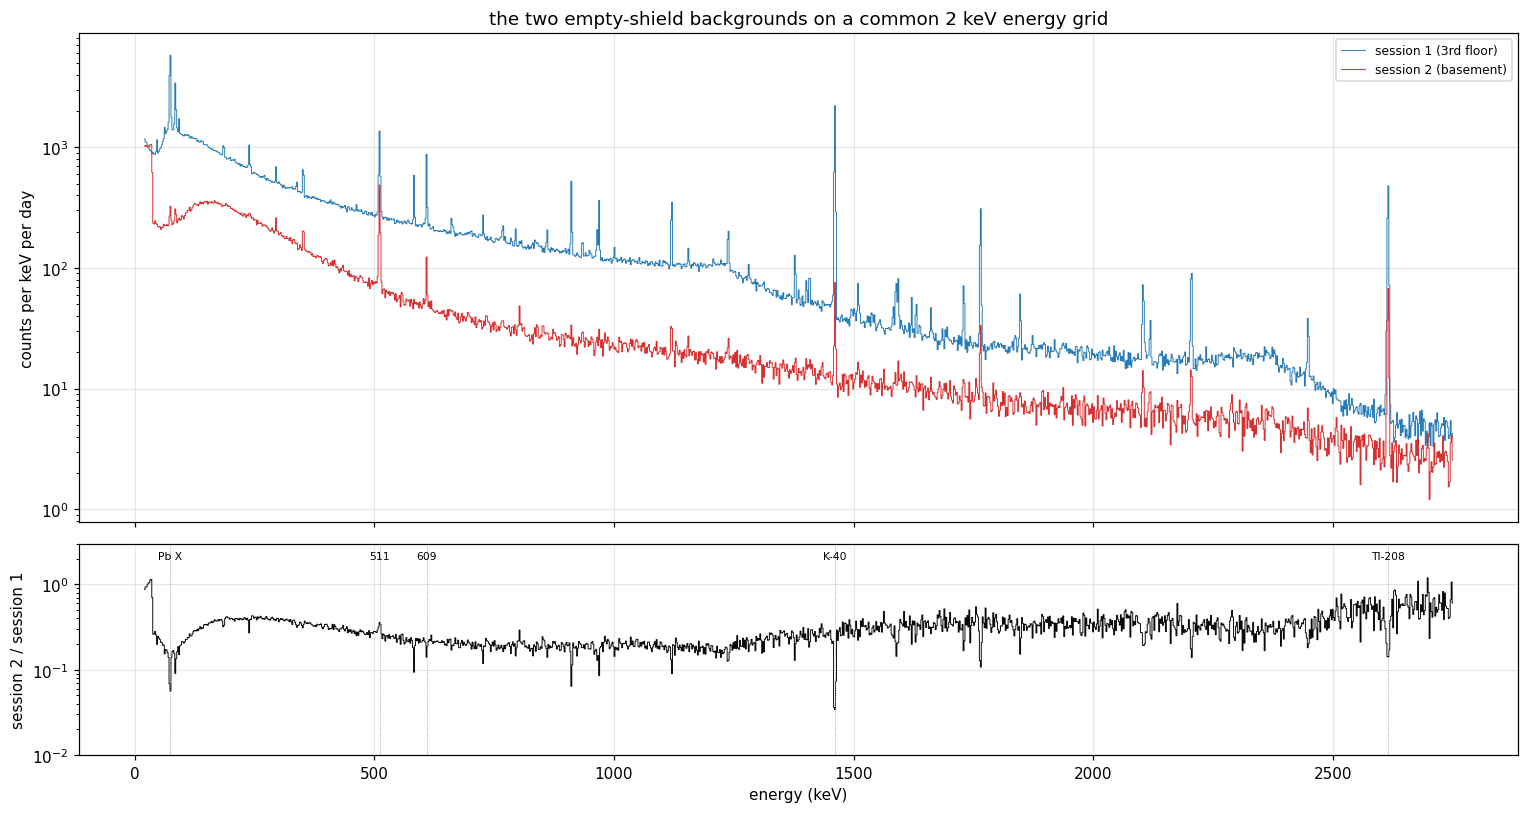

In [23]:
bl = bkg_lines.set_index("line")
I609, I583 = 45.44, 85.0 * 0.3594                       # % per decay of Bi-214, and per Th-232 decay for Tl-208 583
I2614 = 99.755 * 0.3594
indicators = []
for setup in setups:
    R = lambda key: (bl.loc[key, f"{setup} cpd"], bl.loc[key, f"{setup} err"])
    rn = G.ratio(R("Bi-214 609.3")[0] / I609, R("Bi-214 609.3")[1] / I609, R("Tl-208 583.2")[0] / I583, R("Tl-208 583.2")[1] / I583)
    I352 = 35.60
    hard_tl = G.ratio(R("Tl-208 2614.5")[0] / I2614, R("Tl-208 2614.5")[1] / I2614, R("Tl-208 583.2")[0] / I583,
                      R("Tl-208 583.2")[1] / I583)
    hard_rn = G.ratio(R("Pb-214 351.9")[0] / I352, R("Pb-214 351.9")[1] / I352, R("Bi-214 609.3")[0] / I609,
                      R("Bi-214 609.3")[1] / I609)
    k_t = G.ratio(*R("K-40 1460.8"), *R("Tl-208 2614.5"))
    xr = G.ratio(*R("Pb K-alpha1 X-ray 75.0"), *R("K-40 1460.8"))
    an = G.ratio(*R("annihilation 511.0 (width free)"), *R("K-40 1460.8"))
    d = setups[setup]
    hi = G.window_rate(d["spec"], d["cal"], 2650, 2750)
    mid = G.window_rate(d["spec"], d["cal"], 1500, 2500)
    cont = G.ratio(hi[0], hi[1], mid[0], mid[1])
    cands, S_cal, _ = G.calibrated_search(d["spec"].counts, d["cal"], d["sig"], threshold=-1e9)
    S_at = lambda E: float(S_cal[int(round(d["cal"].channel(E))) - 3:int(round(d["cal"].channel(E))) + 4].max())
    indicators.append({"setup": setup, "radon / thorium (609 vs 583, per decay)": f"{rn[0]:.2f} +- {rn[1]:.2f}",
                       "Tl-208 2614 / 583 per photon emitted": f"{hard_tl[0]:.2f} +- {hard_tl[1]:.2f}",
                       "Pb-214 352 / Bi-214 609 per photon emitted": f"{hard_rn[0]:.2f} +- {hard_rn[1]:.2f}",
                       "Bi-214 609 / K-40": f"{G.ratio(*R('Bi-214 609.3'), *R('K-40 1460.8'))[0]:.2f} +- "
                                            f"{G.ratio(*R('Bi-214 609.3'), *R('K-40 1460.8'))[1]:.2f}",
                       "K-40 / Tl-208 2614": f"{k_t[0]:.2f} +- {k_t[1]:.2f}",
                       "Pb X-ray / K-40": f"{xr[0]:.2f} +- {xr[1]:.2f}",
                       "511 / K-40": f"{an[0]:.2f} +- {an[1]:.2f}",
                       "2650-2750 keV continuum, counts/keV/day": f"{86400 * hi[0]:.3f} +- {86400 * hi[1]:.3f}",
                       "continuum 2650-2750 / 1500-2500": f"{cont[0]:.3f} +- {cont[1]:.3f}",
                       "S at Ge-74(n,n') 596 keV": f"{S_at(595.85):.1f}", "S at Ge-72(n,n') 691 keV": f"{S_at(691.4):.1f}"})
print(pd.DataFrame(indicators).set_index("setup").T.to_string())

WINDOWS = [(30, 60), (60, 100), (100, 200), (200, 500), (500, 1000), (1000, 1450), (1500, 2600), (2650, 2750)]
rows = []
for lo_E, hi_E in WINDOWS:
    row = {"window keV": f"{lo_E}-{hi_E}"}
    for setup, d in setups.items():
        r_, sr_ = G.window_rate(d["spec"], d["cal"], lo_E, hi_E)
        row[f"{setup} /keV/day"] = 86400 * r_
    row["ratio s2/s1"] = row["session 2 (basement) /keV/day"] / row["session 1 (3rd floor) /keV/day"]
    rows.append(row)
print()
table(pd.DataFrame(rows), 3)

edges = np.arange(20.0, 2751.0, 2.0)
centres_E = 0.5 * (edges[1:] + edges[:-1])
fig, axes = plt.subplots(2, 1, figsize=(14, 7.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
rates = {}
for (setup, d), col in zip(setups.items(), ("tab:blue", "tab:red")):
    r_, sr_ = G.rebin_to_energy(d["spec"], d["cal"], edges)
    rates[setup] = (r_ * 86400, sr_ * 86400)
    axes[0].step(centres_E, np.maximum(r_ * 86400, 1e-3), where="mid", lw=0.6, color=col, label=setup)
axes[0].set_yscale("log")
axes[0].set(ylabel="counts per keV per day", title="the two empty-shield backgrounds on a common 2 keV energy grid")
axes[0].legend(fontsize=8)
ratio_E = rates["session 2 (basement)"][0] / np.where(rates["session 1 (3rd floor)"][0] > 0, rates["session 1 (3rd floor)"][0], np.nan)
axes[1].step(centres_E, ratio_E, where="mid", lw=0.6, color="k")
axes[1].set(yscale="log", ylim=(0.01, 3), xlabel="energy (keV)", ylabel="session 2 / session 1")
for E, lab in [(75, "Pb X"), (511, "511"), (609, "609"), (1461, "K-40"), (2615, "Tl-208")]:
    axes[1].axvline(E, color="0.6", lw=0.6, ls=":")
    axes[1].text(E, 2.0, lab, fontsize=7, ha="center")
fig.tight_layout(); save(fig, "backgrounds_compared"); plt.show()

**The system itself.** The new setup has a lower gain (0.1685 against 0.1971 keV per channel), so the same 16 384 channels cover 0 to 2760 keV instead of 0 to 3230 keV, and nothing above 2.76 MeV is recorded. Its threshold is much lower (1.6 against 10 keV), so 12 % of all its counts are electronic noise below 10 keV. That inflates its total rate but does no harm above 20 keV. It resolves peaks better at every energy, has a similar Fano factor and a similar, slightly shorter tail, and its dead time is negligible (0.02 %).

**A step at 36 keV.** Every session-2 spectrum, the empty-shield background included, shows a sharp drop of the continuum by a factor of 4.0 to 4.4 between 35 and 37 keV, while the session-1 spectrum shows nothing of the kind (ratio 1.05). Because the step is the same in all four runs, it comes from the setup, not from any sample. Two explanations fit a sharp, sample-independent edge. One is an absorber with a K edge near 36 keV in front of the crystal (caesium, at 35.985 keV, would fit, for example in a CsI veto counter). The other is an electronic threshold in the Lynx, such as a fast-discriminator or pile-up-rejection threshold, below which pulses are treated differently. The continuum above the edge rises by only about 40 % from 40 to 150 keV, whereas an absorber strong enough to remove three quarters of the photons just above its K edge would let through far more at 150 keV, so the shape argues for the electronic explanation. We cannot settle it from the spectra alone, so the region below 40 keV is treated as unreliable, and the Lynx settings and the detector's construction should be checked. InterSpec's automatic search mistakes the same edge for two broad peaks (Section 14).

**Far fewer environmental gammas.** The new background is lower by a factor of 37 at K-40, 60 at Tl-208 583 keV and Ac-228 911 keV, 20 at Pb-212 and 40 at the lead X-rays. Detector size alone cannot explain factors this large, so the new detector is far better shielded. The lines that survive best confirm it. Tl-208 2614.5 keV drops by only a factor of 7, while its sister line at 583 keV from the same decay drops by 60, so their ratio per emitted photon rises from 1.6 to 14. Lead attenuates 583 keV photons much more strongly than 2614.5 keV ones, so a thick shield hardens the external spectrum in exactly this way. The continuum shows the same trend, falling by a factor of 7.6 between 60 and 100 keV but only 3 between 1.5 and 2.6 MeV. The Pb-210 line at 46.5 keV, 600 counts per day in session 1 and a sign of Pb-210 in the old shield, is not detected in session 2 ($21 \pm 12$ per day), and the Cs-137 contamination of the old setup (155 per day) is not significant here either.

**Radon becomes the dominant line source.** The radon daughters drop by only a factor of 4 (Pb-214 at 295 and 352 keV) to 17 (Bi-214 at 1120 keV). Relative to K-40 they are four times more important in the new background (Bi-214 609/K-40 is 1.06 against 0.26), and their spectrum is unattenuated, with Pb-214 352 keV per emitted photon 1.7 times Bi-214 609 keV against 0.7 in session 1. Both say that the radon seen in session 2 sits inside the shield, in the air around the detector, where the lead cannot attenuate it, while in session 1 most radon-daughter photons came through the shield. A basement is close to the soil and usually has more radon, which fits, and flushing the shield cavity with nitrogen would remove most of it.

**Cosmic rays.** With the environmental gammas suppressed, the cosmic-ray components stand out. The 511 keV line is only 2.6 times weaker than in session 1, so relative to K-40 it is 14 times stronger, and the continuum between 2650 and 2750 keV, where no natural gamma line contributes, falls only by a factor of 1.7 (from 4.8 to 2.8 counts per keV per day). Muons pass through a few centimetres of lead almost unhindered, which is why these features survive good shielding. That both are lower in the basement is consistent with the reduced cosmic-ray flux under several floors of concrete, although the different crystal size prevents a clean separation of the two effects. The fast-neutron features of germanium at 596 and 691 keV are not seen in either background ($S < 2$), but the 803 keV line of Pb-206, excited when fast neutrons scatter inelastically in the lead shield, is present in both at about 32 counts per day (2.7 and 4.7 standard deviations). It does not fall in the basement (ratio $0.96 \pm 0.41$). That is what one expects if most of these neutrons are made by muons inside the lead itself (through muon capture and spallation), since the muon flux is only mildly reduced underground and the new shield contains more lead. Neutrons are therefore a small but real part of the background at both locations.

**In short**, the new setup is a better-shielded, better-resolving, lower-threshold system whose continuum above 40 keV is two to eight times lower and whose environmental lines are twenty to sixty times lower than before. What remains is mostly radon inside the shield and cosmic rays, so for weak samples the most useful improvements would be radon suppression and longer counting, while the step at 36 keV and the response below it must be understood before any line below about 60 keV is used.

### What the comparison cannot separate

Detector, electronics, location and shielding change together. These data establish lower observed rates and different spectral shapes, but do not determine shielding thickness or isolate the effect of moving underground. Nearby-line ratios reduce efficiency dependence; they do not remove differences in source geometry, attenuation or coincidence summing.

The radon-daughter pattern supports a relatively important contribution inside the shield, but cannot uniquely locate the source or determine room radon concentration. The 511 keV line is not an exclusive cosmic-ray monitor because several processes produce positrons. Likewise, matching the 36 keV feature to an absorption-edge energy does not identify a material. Hardware records and controlled changes to discriminator settings or absorber configuration would distinguish the proposed explanations.

## 13. The samples against their background

### Why subtract the background
Every line in the background is also present when a sample sits in the shield, because the walls, the radon and the detector do not switch off. The rate of a line that belongs to the sample is therefore the gross rate in the sample spectrum minus the rate of the same line in the background spectrum, each divided by its own live time,
$$ R_\text{net} = \frac{N_s}{t_s} - \frac{N_b}{t_b} , \qquad \sigma_{R}^2 = \frac{\sigma_{N_s}^2}{t_s^2} + \frac{\sigma_{N_b}^2}{t_b^2} , $$
where the variances add because the two runs are independent. Without the subtraction, every rate would include the background contribution, which is a large fraction for weak samples (last column of the table below).

### Two caveats
* **The sample shields part of the background.** A few hundred grams of sediment absorb some of the external photons that the empty-shield run recorded, so subtracting the full background slightly over-subtracts, most at low energy. This is a systematic effect we note but do not correct here.
* **Radon varies.** The radon in the shield during a sample run need not equal that during the background run, so the subtraction of Pb-214 and Bi-214 lines carries an extra, unknown uncertainty. If the pots were sealed, the radon inside them grows towards equilibrium with Ra-226 over about three weeks, which is a separate time dependence.

### Method
Each line is fitted at its expected energy in every spectrum with the same fixed-shape model, whether or not the search found it, so that sample and background are measured identically. Two lines that are too close to resolve are fitted as one, the Th-234 doublet at 92.4 and 92.8 keV and the 185.7 keV U-235 line with the 186.2 keV Ra-226 line.

In [24]:
SAMPLE_LINES = [("Pb-210", 46.539, []), ("Am-241", 59.5409, []), ("Th-234", 63.29, []), ("Th-234 doublet", 92.59, []),
                ("Ra-226 + U-235", 186.0, []), ("Pb-212", 238.632, [241.995]), ("Pb-214", 295.224, [300.087]),
                ("Pb-214", 351.932, []), ("Tl-208", 583.187, []), ("Bi-214", 609.321, []), ("Cs-137", 661.657, []),
                ("Ac-228", 911.204, []), ("Ac-228", 968.971, [964.766]), ("Bi-214", 1120.294, []), ("K-40", 1460.820, []),
                ("Bi-214", 1764.491, []), ("Tl-208", 2614.511, []), ("Cs-134", 795.864, []), ("Co-60", 1332.492, [])]
gross = {}
for k, s in specs.items():
    rows = []
    for name, E, nb in SAMPLE_LINES:
        p, fit = G.fit_line_at(s, cals[k], E, sigma_keV, TAU, neighbours=nb)
        rows.append(dict(line=f"{name} {E:.1f}", rate=p["rate"], s_rate=p["s_rate"], area=p["A"], s_area=p["sA"],
                         E_fit=p["E_fit"], pval=p["pval"]))
    gross[k] = pd.DataFrame(rows).set_index("line")
net_rows = []
b = gross[BACKGROUND]
for k in specs:
    if k == BACKGROUND:
        continue
    g = gross[k]
    for line in g.index:
        R, sR, z = G.net_rate(g.loc[line, "rate"], g.loc[line, "s_rate"], b.loc[line, "rate"], b.loc[line, "s_rate"])
        net_rows.append(dict(spectrum=k, line=line, gross_cpd=86400 * g.loc[line, "rate"],
                             bkg_cpd=86400 * b.loc[line, "rate"], net_cpd=86400 * R, s_net_cpd=86400 * sR, z=z,
                             bkg_share_pct=100 * b.loc[line, "rate"] / g.loc[line, "rate"]
                             if g.loc[line, "rate"] > 2 * g.loc[line, "s_rate"] else np.nan))
net = pd.DataFrame(net_rows)
wide = net.pivot(index="line", columns="spectrum", values=["net_cpd", "s_net_cpd", "z", "bkg_share_pct"])
order = [f"{n} {E:.1f}" for n, E, _ in SAMPLE_LINES]
wide = wide.reindex(order)
print("net rates (counts per day of live time), their errors, significance z and the background share of the gross rate (%)")
print(wide.round(1).to_string())

ratios = []
for line in order:
    n1 = net[(net.spectrum == "Norway 1") & (net.line == line)].iloc[0]
    n2 = net[(net.spectrum == "Norway 2") & (net.line == line)].iloc[0]
    ia_ = net[(net.spectrum == "IAEA-385") & (net.line == line)].iloc[0]
    if n1.z > 3 and n2.z > 3:
        r21 = G.ratio(n2.net_cpd, n2.s_net_cpd, n1.net_cpd, n1.s_net_cpd)
        r1i = G.ratio(n1.net_cpd, n1.s_net_cpd, ia_.net_cpd, ia_.s_net_cpd) if ia_.z > 3 else (np.nan, np.nan)
        r2i = G.ratio(n2.net_cpd, n2.s_net_cpd, ia_.net_cpd, ia_.s_net_cpd) if ia_.z > 3 else (np.nan, np.nan)
        ratios.append(dict(line=line, N2_over_N1=r21[0], err=r21[1], N1_over_IAEA=r1i[0], err1=r1i[1],
                           N2_over_IAEA=r2i[0], err2=r2i[1]))
print("\nratios of net rates (same detector and geometry, so these are ratios of activity x mass)")
table(pd.DataFrame(ratios), 3)

# Ratios of two lines in the same sample do not depend on the sample mass, so they compare the
# composition of the samples even though the masses are not known.
pairs_mass_free = [("Cs-137 661.7", "K-40 1460.8"), ("Cs-137 661.7", "Pb-212 238.6"), ("Pb-214 351.9", "Pb-212 238.6"),
                   ("K-40 1460.8", "Pb-212 238.6")]
rows = []
for k in [k for k in specs if k != BACKGROUND]:
    row = {"spectrum": k}
    for a, b_ in pairs_mass_free:
        na = net[(net.spectrum == k) & (net.line == a)].iloc[0]
        nb_ = net[(net.spectrum == k) & (net.line == b_)].iloc[0]
        r_, sr_ = G.ratio(na.net_cpd, na.s_net_cpd, nb_.net_cpd, nb_.s_net_cpd)
        row[f"{a.split()[0]} / {b_.split()[0]}"] = f"{r_:.3f} +- {sr_:.3f}"
    rows.append(row)
print("\nmass-independent ratios of net rates within each sample")
print(pd.DataFrame(rows).to_string(index=False))

net rates (counts per day of live time), their errors, significance z and the background share of the gross rate (%)
                      net_cpd                   s_net_cpd                          z                   bkg_share_pct                  
spectrum             IAEA-385 Norway 1 Norway 2  IAEA-385 Norway 1 Norway 2 IAEA-385 Norway 1 Norway 2      IAEA-385 Norway 1 Norway 2
line                                                                                                                                  
Pb-210 46.5              -1.7     -3.9     -8.3      16.2     18.6     16.6     -0.1     -0.2     -0.5           NaN      NaN      NaN
Am-241 59.5              -1.5    -10.9      4.6      16.3     17.9     16.0     -0.1     -0.6      0.3           NaN      NaN      NaN
Th-234 63.3             -12.6     10.0      9.6      17.2     18.2     16.6     -0.7      0.5      0.6           NaN      NaN     56.7
Th-234 doublet 92.6      43.1     63.4     33.8      17.9     19.7     17

### Using IAEA-385 to remove the unknown masses and efficiencies
The rate of a line is $R = A\,m\,I\,\varepsilon(E)$, the activity concentration times the mass, the emission probability and the full-energy efficiency. In the ratio of two lines X and Y measured in the same pot the mass cancels, $R_X/R_Y = (A_X I_X \varepsilon_X)/(A_Y I_Y \varepsilon_Y)$. If a sample and the reference material are measured in the same geometry (same pot, similar fill and density), the efficiency ratio $\varepsilon_X/\varepsilon_Y$ is the same for both, and so are the emission probabilities, so
$$ \left(\frac{A_X}{A_Y}\right)_\text{sample} = \frac{(R_X/R_Y)_\text{sample}}{(R_X/R_Y)_\text{IAEA-385}}\left(\frac{A_X}{A_Y}\right)_\text{IAEA-385} . $$
This gives activity ratios of the sediments with no knowledge of mass or efficiency. The certificate values are decayed from 1 January 2019 to the middle of the IAEA-385 run, Cs-137 with its 30.08 year half-life and Pb-210 towards equilibrium with Ra-226 with its 22.2 year half-life. Th-228 and its daughters are taken to be in equilibrium with Th-232, and Am-241 ingrowth from Pu-241 (about 0.1 Bq/kg since 2019) is neglected.

The same ratio for IAEA-385 alone measures the efficiency ratio of the detector, $\varepsilon_X/\varepsilon_{1460.8} = (R_X/R_K)(A_K I_K)/(A_X I_X)$. For lines that are not detected this gives an upper limit, which tells us whether the missing low-energy lines are simply too weak or point to a very low efficiency.

In [25]:
rm = REFERENCE_MATERIAL
t_y = (rm["measured_mid_date"] - rm["reference_date"]).days / 365.25
A_ref = {"K-40": rm["K40"], "Cs-137": (rm["Cs137"][0] * 2**(-t_y / 30.08), rm["Cs137"][1] * 2**(-t_y / 30.08)),
         "Th-232": rm["Th232"], "Ra-226": rm["Ra226"], "Am-241": rm["Am241"],
         "Pb-210": (rm["Ra226"][0] + (rm["Pb210"][0] - rm["Ra226"][0]) * 2**(-t_y / 22.2), rm["Pb210"][1])}
print(f"IAEA-385 on {rm['measured_mid_date']} ({t_y:.2f} y after the reference date): "
      + ", ".join(f"{k} {v[0]:.2f} +- {v[1]:.2f}" for k, v in A_ref.items()) + " Bq/kg")
ens = G.load_ensdf()
I = lambda nuc, E: float(ens.loc[(ens.source_name == nuc) & np.isclose(ens.E_keV, E, atol=1e-3), "I_pct"].iloc[0]) / 100
get = lambda k, line: net[(net.spectrum == k) & (net.line == line)].iloc[0]
ref_name = rm["name"]
K = get(ref_name, "K-40 1460.8")

print("\nefficiency relative to 1460.8 keV, from IAEA-385 (upper limits at 2 standard deviations where not detected)")
rows = []
for nuc, line, E, act in [("Cs-137", "Cs-137 661.7", 661.657, "Cs-137"), ("Pb-212", "Pb-212 238.6", 238.632, "Th-232"),
                          ("Tl-208", "Tl-208 583.2", 583.187, "Th-232"), ("Am-241", "Am-241 59.5", 59.5409, "Am-241"),
                          ("Pb-210", "Pb-210 46.5", 46.539, "Pb-210")]:
    Iy = I(nuc, E) * (0.3594 if nuc == "Tl-208" else 1.0)          # Tl-208 is fed in 35.94 % of Th-232 chain decays
    expect_per_eff = K.net_cpd * (A_ref[act][0] * Iy) / (A_ref["K-40"][0] * I("K-40", 1460.820))
    x = get(ref_name, line)
    if x.z > 3:
        r_, sr_ = G.ratio(x.net_cpd, x.s_net_cpd, expect_per_eff, expect_per_eff * np.hypot(K.s_net_cpd / K.net_cpd,
                                                                                            A_ref[act][1] / A_ref[act][0]))
        rows.append(dict(line=line, measured_cpd=x.net_cpd, s_cpd=x.s_net_cpd, efficiency_ratio=f"{r_:.2f} +- {sr_:.2f}"))
    else:
        rows.append(dict(line=line, measured_cpd=x.net_cpd, s_cpd=x.s_net_cpd,
                         efficiency_ratio=f"< {(max(x.net_cpd, 0) + 2 * x.s_net_cpd) / expect_per_eff:.2f}"))
table(pd.DataFrame(rows), 1)

print("\nactivity ratios of the sediments, calibrated with IAEA-385 in the same geometry (no masses needed)")
rows = []
for k in [k for k in specs if roles[k] == "sample"]:
    row = {"sample": k}
    for line, act in [("Cs-137 661.7", "Cs-137"), ("Pb-212 238.6", "Th-232"), ("Tl-208 583.2", "Th-232"),
                      ("Pb-214 351.9", "Ra-226"), ("Bi-214 609.3", "Ra-226")]:
        xs_, ks_, xr_ = get(k, line), get(k, "K-40 1460.8"), get(ref_name, line)
        r_s = G.ratio(xs_.net_cpd, xs_.s_net_cpd, ks_.net_cpd, ks_.s_net_cpd)
        r_r = G.ratio(xr_.net_cpd, xr_.s_net_cpd, K.net_cpd, K.s_net_cpd)
        a_r = G.ratio(A_ref[act][0], A_ref[act][1], A_ref["K-40"][0], A_ref["K-40"][1])
        q, sq = G.ratio(*r_s, *r_r)
        val, s_val = q * a_r[0], q * a_r[0] * np.hypot(sq / q, a_r[1] / a_r[0])
        row[f"{act}/K-40 from {line.split()[0]} {line.split()[1]}"] = f"{val:.4f} +- {s_val:.4f}"
    rows.append(row)
with pd.option_context("display.width", 250):
    print(pd.DataFrame(rows).set_index("sample").T.to_string())
print(f"\nfor comparison IAEA-385 itself: Cs-137/K-40 = {A_ref['Cs-137'][0] / A_ref['K-40'][0]:.4f}, "
      f"Th-232/K-40 = {A_ref['Th-232'][0] / A_ref['K-40'][0]:.4f}, Ra-226/K-40 = {A_ref['Ra-226'][0] / A_ref['K-40'][0]:.4f}")

IAEA-385 on 2026-10-17 (7.79 y after the reference date): K-40 611.00 +- 13.50, Cs-137 16.55 +- 0.25, Th-232 33.80 +- 0.45, Ra-226 22.80 +- 0.30, Am-241 4.42 +- 0.12, Pb-210 27.27 +- 0.95 Bq/kg

efficiency relative to 1460.8 keV, from IAEA-385 (upper limits at 2 standard deviations where not detected)
        line  measured_cpd  s_cpd efficiency_ratio
Cs-137 661.7         342.8   13.2     2.07 +- 0.10
Pb-212 238.6         725.1   24.3     4.19 +- 0.18
Tl-208 583.2         203.3   12.2     1.68 +- 0.11
 Am-241 59.5          -1.5   16.3           < 1.75
 Pb-210 46.5          -1.7   16.2           < 2.38

activity ratios of the sediments, calibrated with IAEA-385 in the same geometry (no masses needed)
sample                                 Norway 1          Norway 2
Cs-137/K-40 from Cs-137 661.7  0.0462 +- 0.0044  0.0277 +- 0.0027
Th-232/K-40 from Pb-212 238.6  0.0659 +- 0.0067  0.0699 +- 0.0060
Th-232/K-40 from Tl-208 583.2  0.0668 +- 0.0104  0.0738 +- 0.0093
Ra-226/K-40 from Pb-214 351

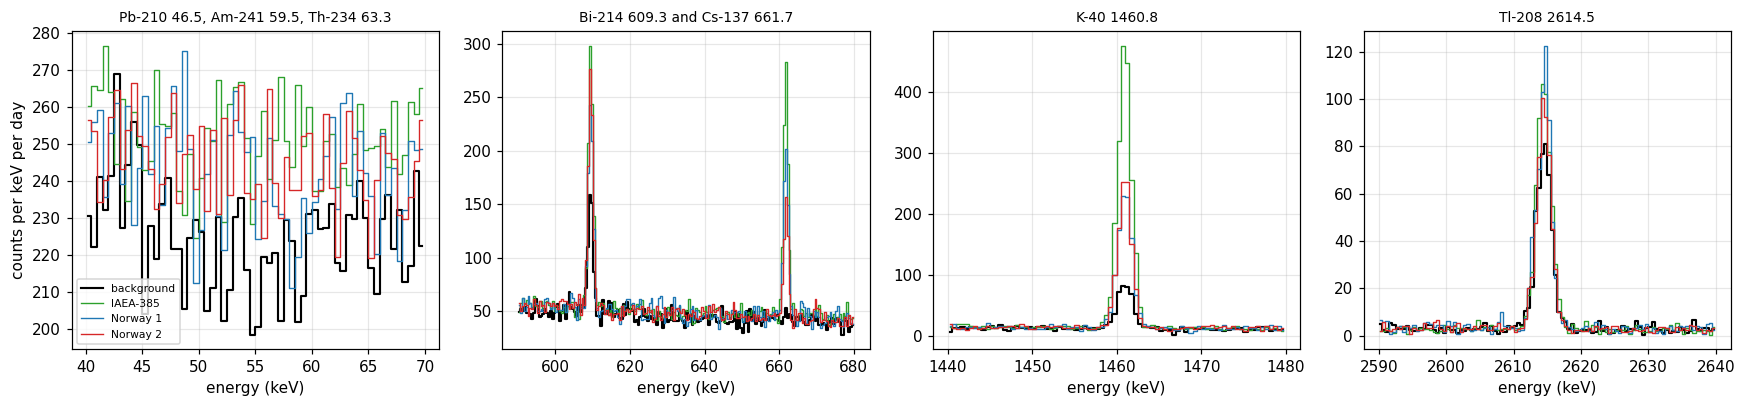

In [26]:
zoom = [(40, 70, "Pb-210 46.5, Am-241 59.5, Th-234 63.3"), (590, 680, "Bi-214 609.3 and Cs-137 661.7"),
        (1440, 1480, "K-40 1460.8"), (2590, 2640, "Tl-208 2614.5")]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, (lo_E, hi_E, title) in zip(axes, zoom):
    edges = np.arange(lo_E, hi_E + 0.001, 0.5)
    cen = 0.5 * (edges[1:] + edges[:-1])
    for (k, s), col in zip(specs.items(), ("k", "tab:green", "tab:blue", "tab:red")):
        r_, _ = G.rebin_to_energy(s, cals[k], edges)
        ax.step(cen, 86400 * r_, where="mid", lw=0.9 if k != BACKGROUND else 1.4, color=col, label=k)
    ax.set(xlabel="energy (keV)", title=title)
    ax.title.set_fontsize(9)
axes[0].set_ylabel("counts per keV per day")
axes[0].legend(fontsize=7)
fig.tight_layout(); save(fig, "samples_vs_background"); plt.show()

**Background subtraction matters for most lines.** For the radon daughters the background supplies 38 to 56 % of the gross rate, for Tl-208 at 2614.5 keV 77 to 87 % and for K-40 17 to 34 %, so without subtraction these rates would be too high by up to a factor of eight. Cs-137 is the exception (2 to 5 %), because the new background contains almost none.

**What the samples contain.** All three show K-40, the Th-232 chain (Pb-212, Ac-228, Tl-208) and the U-238 chain through radon (Pb-214, Bi-214) at high significance, and Cs-137 at 14 to 26 standard deviations. The 186 keV line of Ra-226 and U-235 is seen at 1.5 to 3.6 standard deviations, and the Th-234 doublet at 92.6 keV at 1.9 to 3.2.

**What they do not show, and why.** Pb-210 (46.5 keV), Am-241 (59.5 keV) and Th-234 at 63.3 keV are not detected in any spectrum, IAEA-385 included. The certificate lets us turn this into a statement about the detector. IAEA-385 contains 27 Bq/kg of Pb-210 and 4.4 Bq/kg of Am-241, against 611 of K-40, so the expected Pb-210 and Am-241 rates are small, and their absence only limits the efficiency at 46.5 and 59.5 keV to less than 2.4 and 1.75 times that at 1460.8 keV. The same certificate gives an efficiency at 238.6 keV of $4.19 \pm 0.18$ times that at 1460.8 keV, so the efficiency at 59.5 keV is less than 42 % of the efficiency at 238.6 keV. A detector with a thin entrance window would normally be at least as efficient at 60 keV as at 240 keV, so this one loses most low-energy photons, through a thick dead layer or end cap or through whatever causes the 36 keV step. Excess-Pb-210 dating of the sediments will need either far more counting time, or a detector with a thin entrance window, unless the excess Pb-210 in these layers is very large. A quick test with the sealed Am-241 source in the department inventory would measure the 59.5 keV efficiency directly.

**Comparing the two sediments.** Unknown masses prevent interpreting between-pot rates as concentration differences. The reference-normalized Th-232/K-40 and Ra-226/K-40 activity ratios are consistent between the sediments within their reported errors. Cs-137/K-40 is $0.046 \pm 0.004$ for Norway 1 and $0.028 \pm 0.003$ for Norway 2. The notebook reports a factor of 1.67 and a 4.2-standard-deviation direct comparison, with the common IAEA-385 factor cancelling. This is evidence for a difference in Cs-137 relative to K-40, not proof of identical bulk composition or assignment to a particular fallout event. Absolute activity concentrations require the sample masses and a justified efficiency transfer from the reference.

### Uncertainty after subtraction

Subtraction removes an estimated background mean, not its fluctuations. When gross and background rates nearly cancel, their variances still add. Longer sample counting cannot remove the uncertainty of a fixed background exposure or a systematic radon change. A negative net-rate estimate can therefore be a legitimate fluctuation, not negative physical activity.

Both Norwegian samples use the same background. For one line, if $R_{1,\mathrm{net}}=R_1-R_b$ and $R_{2,\mathrm{net}}=R_2-R_b$, independence of the gross measurements gives
$$\operatorname{Cov}(R_{1,\mathrm{net}},R_{2,\mathrm{net}})=\operatorname{Var}(R_b).$$
That common term cancels in the direct difference for the same line; propagation through ratios is more involved. Shared reference factors also cancel in direct sample comparisons. Treating common inputs as independent can misstate comparison errors.

### From line ratios to environmental interpretation

Mass cancels within a pot, but efficiency does not cancel between different energies. Reference normalization removes the efficiency ratio only when reference and samples have comparable geometry, density and attenuation. This assumption is weakest at low energy because of self-absorption. Certificate uncertainty and decay-chain disequilibrium also affect inferred activity ratios.

The Cs-137/K-40 difference is a useful discriminant, but cannot alone establish sediment age, provenance or a Chernobyl origin. Deposition, redistribution and mineral composition can all affect this ratio. The reported significance describes the notebook's calculation; it does not include every unmeasured environmental systematic.

## 14. Comparison with InterSpec

### How InterSpec analyses a spectrum, described with the same care
InterSpec (Sandia National Laboratories, version 1.0.12 here) is a general gamma-spectroscopy program. Its own help files and its open-source code describe the method, which we summarise step by step next to ours.

| Step | InterSpec | This notebook |
|---|---|---|
| Energy scale | polynomial for the **lower edge** of each channel, $E_i = C_0 + C_1 i + C_2 i^2$ (help file "Energy Calibration") | polynomial for the channel **centre**, converted to InterSpec's form on export |
| Calibration fit | peaks associated with known gammas, weighted $\chi^2$ of the peak means using the peak-mean uncertainties, non-linear least squares | the same idea, plus the ENSDF energy uncertainties (effective variance) and the PDG scale factor |
| Peak search | candidate peaks from a smoothed second derivative of the spectrum, which also sets the ROI | matched filter (a zero-sum Gaussian second derivative) with significance $S$ |
| Peak shape | Gaussian by default, with optional skew models (Exp*Gauss, which is an EMG, GaussExp, Crystal Ball and two double-sided forms) | EMG with one shared tail ratio fitted to the data |
| Continuum | linear by default under each ROI (also constant, quadratic, cubic, step shapes or an external continuum), shared by peaks in the same ROI | straight line under each ROI, shared by peaks in it |
| Bin integration | the peak function is integrated over each channel's energy edges | the same (exact CDF of the EMG) |
| Statistic | $\chi^2 = \sum_i (n_i - f_i)^2/\sigma_i^2$ with $\sigma_i = \sqrt{n_i}$ (1 for nearly empty channels), that is Neyman's $\chi^2$, minimised with Minuit2 or, in newer code, Ceres (Levenberg–Marquardt). Amplitudes and continuum coefficients are solved by linear least squares inside the non-linear fit of means and widths | Poisson deviance (maximum likelihood), all parameters fitted together |
| Uncertainties | from the covariance of the $\chi^2$ fit, which the help file itself says should be taken "with a grain of salt" | inverse expected Fisher information, checked with simulated spectra (Section 7) |
| Peak position | the Gaussian mean (or the skewed model's parameter) | the mode of the EMG |

Two differences matter for the comparison. First, Neyman's $\chi^2$ weights each channel by its observed count, so channels that fluctuate low pull the fit harder. For a continuum of a few counts per channel this biases the continuum low by about one count per channel, which raises the net peak area. Second, a symmetric Gaussian on a skewed peak finds a slightly different centre and gives some of the tail to the continuum. Both effects are small for strong peaks and grow for weak ones.

### How the comparison is done
1. The cell below writes every spectrum as an IAEA `.Spe` file with our calibration already applied (lower-edge coefficients), plus a `.CALp` file, into `data/interspec/session2/`.
2. In InterSpec (opened in a browser through its "Use in external browser" option) each `.Spe` file is opened as the foreground, keeping the file's own calibration when InterSpec offers to reuse the previous one, "Search for Peaks" is run with the default settings and every proposed peak is kept, without any manual editing. The Peak Manager table (mean, FWHM, area, rate and its uncertainty, region of interest and continuum type) is then copied from the page into `<file stem>_interspec_peaks.csv`. InterSpec's own CSV export, saved as `<file stem>_peaks.csv`, is read instead if present.
3. The next cell refits every InterSpec peak with our model at InterSpec's energy (with InterSpec's neighbours in the same window, and with the width free for strong isolated peaks), both as an EMG and as a Gaussian, so that every number is compared like for like, and lists the peaks found by only one of the two programs.

In [27]:
spe_files = {}
for k, s in specs.items():
    stem = f"{SESSION_TAG}_{k.replace(' ', '_')}"
    G.write_spe(ISP / f"{stem}.spe", s, cals[k], title=f"{k} ({s.path.name})")
    G.write_calp(ISP / f"{stem}.CALp", cals[k])
    spe_files[k] = ISP / f"{stem}.spe"
    back = G.read_spe(ISP / f"{stem}.spe")
    C0, C1, C2 = cals[k].lower_edge_coefficients()
    assert np.array_equal(back.counts, s.counts) and abs(back.live - s.live) < 1e-2
    print(f"{stem}.spe written: lower-edge C0 = {C0:.6f} keV, C1 = {C1:.9f} keV/ch, C2 = {C2:.3e}; "
          f"K-40 should appear at 1460.82 keV")

s2_background.spe written: lower-edge C0 = 0.010174 keV, C1 = 0.168366464 keV/ch, C2 = 6.198e-09; K-40 should appear at 1460.82 keV
s2_IAEA-385.spe written: lower-edge C0 = 0.006987 keV, C1 = 0.168359584 keV/ch, C2 = 6.198e-09; K-40 should appear at 1460.82 keV
s2_Norway_1.spe written: lower-edge C0 = -0.006717 keV, C1 = 0.168371781 keV/ch, C2 = 5.334e-09; K-40 should appear at 1460.82 keV
s2_Norway_2.spe written: lower-edge C0 = -0.017758 keV, C1 = 0.168374029 keV/ch, C2 = 5.369e-09; K-40 should appear at 1460.82 keV


background: 12 InterSpec peaks (1 at the 36 keV step), 6 also in our inventory of 7; strong peaks (6): dE = -9.7 +- 11.3 eV (sd 28), area InterSpec / ours: 1.030 (EMG), 1.035 (Gaussian), FWHM ratio 1.022
IAEA-385  : 31 InterSpec peaks (2 at the 36 keV step), 17 also in our inventory of 19; strong peaks (18): dE = -14.4 +- 3.6 eV (sd 15), area InterSpec / ours: 1.012 (EMG), 1.016 (Gaussian), FWHM ratio 1.013
Norway 1  : 21 InterSpec peaks (1 at the 36 keV step), 13 also in our inventory of 16; strong peaks (12): dE = -7.0 +- 9.1 eV (sd 31), area InterSpec / ours: 1.004 (EMG), 1.021 (Gaussian), FWHM ratio 1.007
Norway 2  : 26 InterSpec peaks (1 at the 36 keV step), 15 also in our inventory of 18; strong peaks (15): dE = -9.1 +- 3.8 eV (sd 15), area InterSpec / ours: 1.002 (EMG), 1.030 (Gaussian), FWHM ratio 1.026
  spectrum  E_interspec       source in_our_inventory  dE_keV  fwhm_interspec  fwhm_ours  area_interspec  area_ours_emg  area_ours_gauss  s_area_ours  signif
background        8

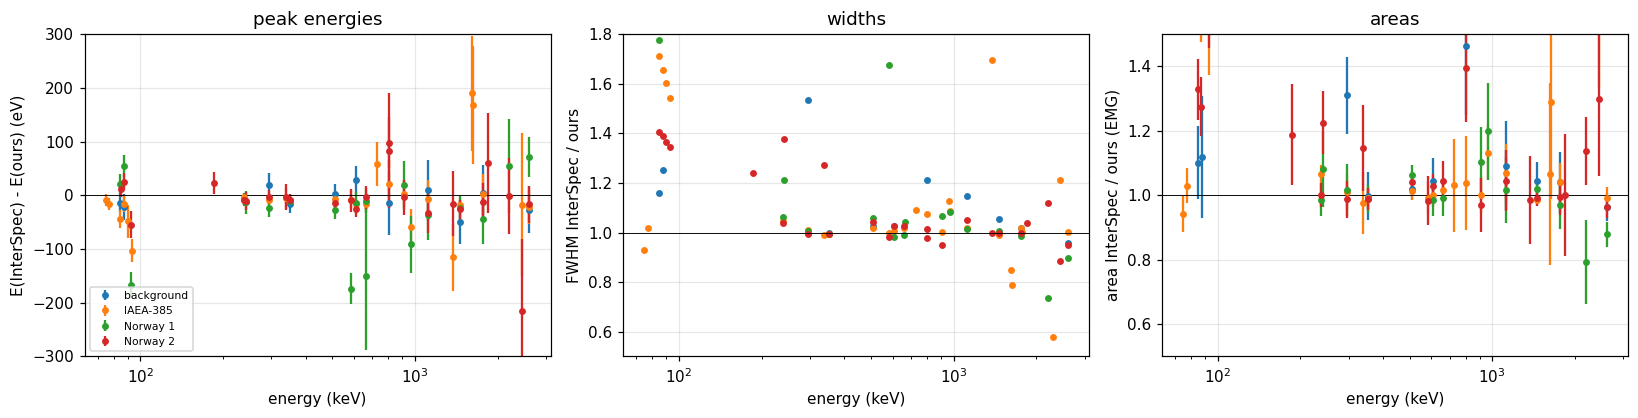

In [28]:
ISP_RESULTS = {}
for k, sp in specs.items():
    stem = f"{SESSION_TAG}_{k.replace(' ', '_')}"
    table_path = ISP / f"{stem}_interspec_peaks.csv"            # Peak Manager table read from the InterSpec page
    export_path = ISP / f"{stem}_peaks.csv"                      # or InterSpec's own CSV export, if saved instead
    if table_path.exists():
        d = pd.read_csv(table_path, comment="#")
        ISP_RESULTS[k] = pd.DataFrame({"E_interspec": d.mean_keV, "fwhm_interspec": d.fwhm_keV, "area_interspec": d.area,
                                       "s_area_interspec": d.s_cps * sp.live, "continuum": d.continuum})
    elif export_path.exists():
        ISP_RESULTS[k] = G.read_interspec_csv(export_path)
if not ISP_RESULTS:
    print("No InterSpec peak tables found yet in", ISP)

rows = []
for k, isp in ISP_RESULTS.items():
    ours = inv[k]
    for r in isp.itertuples():
        if r.E_interspec < 40:                                    # the 36 keV continuum step, not a peak
            rows.append(dict(spectrum=k, E_interspec=r.E_interspec, note="continuum step at 36 keV, not a peak"))
            continue
        nb = [e for e in isp.E_interspec if 0 < abs(e - r.E_interspec) < 4.0]   # InterSpec's neighbours in the ROI
        strong = r.area_interspec / r.s_area_interspec > 10 and not nb      # strong isolated peak: width free
        pe, _ = G.fit_line_at(specs[k], cals[k], float(r.E_interspec), sigma_keV, TAU, free_width=strong, neighbours=nb)
        pg, _ = G.fit_line_at(specs[k], cals[k], float(r.E_interspec), sigma_keV, 0.0, shape="gauss",
                              free_width=strong, neighbours=nb)
        j = (ours.E_keV - r.E_interspec).abs().idxmin() if len(ours) else None
        found = j is not None and abs(ours.E_keV[j] - r.E_interspec) < 0.6
        rows.append(dict(spectrum=k, E_interspec=r.E_interspec, E_ours=pe["E_fit"], dE_keV=r.E_interspec - pe["E_fit"],
                         fwhm_interspec=r.fwhm_interspec, fwhm_ours=pg["fwhm"] * float(cals[k].gain(cals[k].channel(r.E_interspec))),
                         area_interspec=r.area_interspec, s_area_interspec=r.s_area_interspec, area_ours_emg=pe["A"],
                         s_area_ours=pe["sA"], area_ours_gauss=pg["A"], signif=r.area_interspec / r.s_area_interspec,
                         in_our_inventory=found, source=ours.source[j] if found else "", note=""))
cmp_isp = pd.DataFrame(rows)
if len(cmp_isp):
    peaks_only = cmp_isp[cmp_isp.note == ""].copy()
    peaks_only["area_ratio_isp_emg"] = peaks_only.area_interspec / peaks_only.area_ours_emg
    peaks_only["area_ratio_isp_gauss"] = peaks_only.area_interspec / peaks_only.area_ours_gauss
    peaks_only["area_pull_emg"] = (peaks_only.area_interspec - peaks_only.area_ours_emg) / peaks_only.s_area_ours
    for k, d in peaks_only.groupby("spectrum", sort=False):
        st = d[d.signif > 10]
        print(f"{k:10s}: {len(ISP_RESULTS[k])} InterSpec peaks ({np.sum(cmp_isp[cmp_isp.spectrum == k].note != '')} at the "
              f"36 keV step), {int(d.in_our_inventory.astype(bool).sum())} also in our inventory of {len(inv[k])}; strong peaks ({len(st)}): "
              f"dE = {1000 * st.dE_keV.mean():+.1f} +- {1000 * st.dE_keV.std() / np.sqrt(len(st)):.1f} eV (sd {1000 * st.dE_keV.std():.0f}), "
              f"area InterSpec / ours: {st.area_ratio_isp_emg.median():.3f} (EMG), {st.area_ratio_isp_gauss.median():.3f} (Gaussian), "
              f"FWHM ratio {(st.fwhm_interspec / st.fwhm_ours).median():.3f}")
    with pd.option_context("display.width", 250):
        table(peaks_only[["spectrum", "E_interspec", "source", "in_our_inventory", "dE_keV", "fwhm_interspec", "fwhm_ours",
                          "area_interspec", "area_ours_emg", "area_ours_gauss", "s_area_ours", "signif"]], 3)
    only_ours = []
    for k, df in inv.items():
        if k in ISP_RESULTS:
            for r in df.itertuples():
                if np.min(np.abs(ISP_RESULTS[k].E_interspec - r.E_keV)) > 0.6:
                    only_ours.append(dict(spectrum=k, E_keV=r.E_keV, source=r.source, S=r.S, area=r.area, s_area=r.s_area))
    print("\npeaks in our inventory that InterSpec's search did not report:")
    table(pd.DataFrame(only_ours), 2)

    fig, axes = plt.subplots(1, 3, figsize=(15, 3.9))
    for k, d in peaks_only.groupby("spectrum", sort=False):
        axes[0].errorbar(d.E_interspec, 1000 * d.dE_keV, yerr=1000 * d.fwhm_ours / (G.FWHM_PER_SIGMA * np.sqrt(d.area_ours_emg.clip(1))),
                         fmt="o", ms=3.5, label=k)
        axes[1].plot(d.E_interspec, d.fwhm_interspec / d.fwhm_ours, "o", ms=3.5, label=k)
        axes[2].errorbar(d.E_interspec, d.area_ratio_isp_emg, yerr=d.s_area_ours / d.area_ours_emg.clip(1), fmt="o", ms=3.5, label=k)
    axes[0].set(xscale="log", xlabel="energy (keV)", ylabel="E(InterSpec) - E(ours) (eV)", ylim=(-300, 300), title="peak energies")
    axes[1].set(xscale="log", xlabel="energy (keV)", ylabel="FWHM InterSpec / ours", ylim=(0.5, 1.8), title="widths")
    axes[2].set(xscale="log", xlabel="energy (keV)", ylabel="area InterSpec / ours (EMG)", ylim=(0.5, 1.5), title="areas")
    for ax, y0 in zip(axes, (0, 1, 1)):
        ax.axhline(y0, color="k", lw=0.6)
    axes[0].legend(fontsize=7)
    fig.tight_layout(); save(fig, "interspec_comparison"); plt.show()
    cmp_isp.to_csv(RES / f"{SESSION_TAG}_interspec_comparison.csv", index=False)

**Energies.** For the strong peaks (significance above 10) InterSpec's centroids are on average 7 to 14 eV lower than ours, with a scatter of 15 to 30 eV, which is far below the 79 to 98 eV calibration systematic. This is the size of offset the simulation of Section 7 predicts when a symmetric Gaussian is fitted to a peak with this tail (about $-15$ eV at K-40), so the two programs agree to within the known effect of the peak model. Since both programs use the same calibration, this confirms that InterSpec applies the `.Spe` coefficients to the lower edge of each channel, exactly as its manual says. A channel-centre reading would have shifted every InterSpec energy down by half a bin, 84 eV, and that is excluded by many standard deviations. This settles the convention question left open in session 1 (`s1_BkgRun5_Long.CALp` uses the right form).

**Widths.** InterSpec's FWHM values for strong peaks are 1 to 3 % larger than ours, consistent with a symmetric Gaussian stretching to cover the low-energy tail. The exceptions are informative. For the weak Tl-208 583 keV line in Norway 1, InterSpec fitted a FWHM of 2.04 keV, against 1.2 keV for every other peak at that energy, and so doubled the area (665 against our 312 counts). Letting the width float on a weak peak is exactly the instability that fixing widths from a resolution model avoids.

**Areas.** InterSpec's areas for strong peaks are 0.2 to 3 % higher than ours (median over spectra), and 1.6 to 3.5 % higher than our own Gaussian fits. Two effects push in this direction. Neyman's $\chi^2$, which InterSpec minimises, weights each channel by its own observed count, so channels that fluctuated low pull the fitted continuum down, and every count taken from the continuum is added to the peak. The second is the continuum shape itself, since InterSpec chooses its region of interest and continuum order per peak (quadratic for the X-ray group near 85 keV), while we use a straight line over ±7 widths. A few per cent is the size of systematic that should be quoted when areas from the two programs are mixed.

**What each program finds.** InterSpec reports 12 to 31 peaks per spectrum and we report 7 to 19, because its search goes lower in significance (several of its extra peaks have area/error between 3 and 7, for example Bi-212 at 727.3 keV and the 803 keV line discussed in Section 12, and some, such as 1769 and 2305 keV, are not significant in our refit). It also reports one or two broad "peaks" at 32.7 and 35.0 keV, which are the continuum step of Section 12 fitted as Gaussians. Our inventory contains a few lines that InterSpec's search did not report, mostly the Pb and Bi K X-rays, which InterSpec grouped differently. The comparison therefore gives the same physics from two independent codes, with differences that are understood.

### What agreement with InterSpec validates

Both programs receive the same calibration and observed counts. Agreement checks export conventions and differences in peak fitting, not absolute calibration independently. Their statistical errors are correlated, so adding their variances as though they came from independent measurements does not give a justified significance for their difference.

For areas, compare the same region, neighbours and continuum before attributing differences to peak shape. The observed percent-level differences describe these spectra; they are not a universal correction factor. Weak and blended peaks need individual inspection because width and continuum choices can redistribute much of their apparent area.

## 15. Outputs

### Why export
A calibration is useful only if later steps can use it without re-running this notebook, and only if it carries its provenance. For every spectrum we write the calibrated spectrum (every channel with its lower, centre and upper energy, the calibration uncertainty, counts and rate), a JSON record (coefficients and covariance, both channel conventions, the lines used, the shape and resolution models and the raw file's SHA-256), the peak inventory and the net rates. The `.Spe` and `.CALp` files for InterSpec were written in Section 14.

In [29]:
for k, s in specs.items():
    stem = f"{SESSION_TAG}_{k.replace(' ', '_')}"
    cal = cals[k]
    G.write_calibrated_csv(RES / f"{stem}_calibrated_spectrum.csv", s, cal,
                           notes=[f"peak model EMG, tail beta = {TAU:.3f} sigma, positions are modes",
                                  f"array index 0 = file channel {s.meta['first_channel_label']}"])
    rec = dict(source_file=s.path.name, source_sha256=s.sha256, header_start=str(s.start), live_time_s=s.live,
               real_time_s=s.real, model="E = sum a_j x^j, x = channel index (channel-centre coordinate, index 0 = file channel 1)",
               coefficients=list(map(float, cal.a)), covariance=np.asarray(cal.C).tolist(), chi2=cal.chi2, ndf=cal.ndf,
               scale_factor=cal.scale, interspec_lower_edge=dict(zip(["C0", "C1", "C2"], map(float, cal.lower_edge_coefficients()))),
               lines_used=lines[k][lines[k].used][["nuclide", "E_ref", "sE_ref", "position", "sposition"]].to_dict(orient="records"),
               peak_shape=dict(model="EMG (Gaussian convolved with low-energy exponential)", tail_ratio=TAU, tail_ratio_err=TAU_ERR,
                               step_ratio=STEP),
               resolution=dict(model="FWHM^2 = w0^2 + w1^2 E + w2^2 E^2 (keV), Gaussian part", w=list(map(float, W)),
                               covariance=W_cov.tolist(), actual_fwhm_w=list(map(float, WT)), fano=fano, fano_err=s_fano))
    G.save_json(RES / f"{stem}_energy_calibration.json", rec)
    inv[k].to_csv(RES / f"{stem}_peaks.csv", index=False)
net.to_csv(RES / f"{SESSION_TAG}_net_rates.csv", index=False)
bkg_lines.to_csv(RES / f"{SESSION_TAG}_background_s1_vs_s2.csv", index=False)
cal_summary.to_csv(RES / f"{SESSION_TAG}_calibration_summary.csv", index=False)
timeline.to_csv(RES / f"{SESSION_TAG}_timeline.csv", index=False)
for p in sorted(RES.glob(f"{SESSION_TAG}_*")):
    print(f"{p.relative_to(SESSION_DIR)}  ({p.stat().st_size / 1024:.1f} kB)")

results/session2/s2_IAEA-385_calibrated_spectrum.csv  (1058.4 kB)
results/session2/s2_IAEA-385_energy_calibration.json  (3.8 kB)
results/session2/s2_IAEA-385_peaks.csv  (5.4 kB)
results/session2/s2_Norway_1_calibrated_spectrum.csv  (1056.2 kB)
results/session2/s2_Norway_1_energy_calibration.json  (3.6 kB)
results/session2/s2_Norway_1_peaks.csv  (4.5 kB)
results/session2/s2_Norway_2_calibrated_spectrum.csv  (1058.2 kB)
results/session2/s2_Norway_2_energy_calibration.json  (3.8 kB)
results/session2/s2_Norway_2_peaks.csv  (5.1 kB)
results/session2/s2_background_calibrated_spectrum.csv  (1056.1 kB)
results/session2/s2_background_energy_calibration.json  (2.9 kB)
results/session2/s2_background_peaks.csv  (2.1 kB)
results/session2/s2_background_s1_vs_s2.csv  (2.0 kB)
results/session2/s2_calibration_summary.csv  (0.9 kB)
results/session2/s2_interspec_comparison.csv  (15.9 kB)
results/session2/s2_net_rates.csv  (7.3 kB)
results/session2/s2_timeline.csv  (0.5 kB)


## 16. What changed from the old code, why, and what it does to the results

| Step | Old code (session 1) | New code (session 2) | Why | Effect on the results |
|---|---|---|---|---|
| Reading | ORTEC .Chn and Maestro .Txt only | Lynx CSV, ORTEC .Chn, IAEA .Spe, Maestro printout, plain columns, one function | the Lynx writes CSV with 1-based channels | without it nothing runs, and a 1-based offset would move every energy by 0.17 keV |
| Metadata | times read from the header | header times checked against the download clock | two of four headers are impossible | prevents wrong dates in decay corrections and in the lab book |
| Rough calibration | from the calibration stored in the file | pattern matching of 13 known lines, no prior calibration | the Lynx stores none (slope 1) | the old method silently fitted noise (gain 0.985 keV/ch), the new one finds 0.1685 keV/ch in every spectrum |
| Reusing a calibration | `load_calibration` of an earlier session | one calibration per spectrum, drift measured | gain differs by 17 % between setups | the session-1 calibration misplaces K-40 by 249 keV |
| Peak shape | Gaussian plus step (tail optional, centre-sampled) | EMG with one shared tail, exact CDF over each bin, mode as position | photopeaks have a low-energy tail, and peaks are binned | positions shift by about one statistical error (15 eV at K-40), strong-peak areas by 0.2 to 0.4 %, weak peaks and X-rays by 3 to 7 % |
| Shape parameters | fitted per peak or fixed by hand | profiled jointly over all lines and spectra | a small tail is invisible in one weak peak but clear in many | $\tau = 0.40 \pm 0.06$ found at 3.3 standard deviations, where per-line fits were inconclusive |
| Calibration model | straight line, PDG scale factor | polynomial chosen by F-test, systematic floor for ADC non-linearity, curvature borrowed by weak spectra | the Lynx scale is curved and wiggles | the old straight line was off by up to 0.46 keV, the new calibration is consistent with every line within 0.08 to 0.1 keV |
| Broad lines | width fixed for weak peaks, free above S = 10 | the same rule kept, with the tail tied to the width | 511 keV is Doppler broadened | a fixed width loses about 45 % of the 511 keV area |
| Background | rates only | net rates, mass-free ratios and IAEA-385 relative activities | samples sit on the same background | radon-daughter and 2614.5 keV rates would otherwise be 40 to 87 % too high |
| Exports | CSV, JSON, CALp | also IAEA .Spe with the calibration built in | InterSpec reads it directly | InterSpec agrees within 7 to 14 eV and a few per cent in area |

### Using this notebook for another experiment
1. Put the raw files in a folder and list them, with their roles, in the configuration cell. Any of the supported formats works (Lynx CSV, ORTEC .Chn, IAEA .Spe, Maestro printout or plain columns with the times supplied).
2. If the spectra are not natural-background or soil spectra, replace `G.NATURAL_LINES` by the lines of the source used (for example Co-60, Cs-137 or Eu-152), both for the automatic calibration and for the calibration fit.
3. Run everything. The automatic calibration, the shared tail ratio, the calibration, the resolution model and the inventory are all derived from the data. Then read the checks (calibration residuals, independent lines, pulls) before trusting the numbers, and rewrite the interpretation cells.